# Rolling & Expanding Window Forecasting (Walk-Forward Backtesting) — 6 bộ đầu vào (`FS01–FS06`)

**Thành viên phụ trách:** Quân (Phương pháp 4 — IS403)  
**Dữ liệu dùng chung:** `dataset_9_commodities_daily.csv` (2.710 phiên, `2016-01-13 → 2026-11-13`, không bỏ dòng).

### Mục lục thực nghiệm (8 phần)
1. **Giao thức & Cấu hình môi trường** — 6 bộ biến `FS01–FS06`, 2 nhánh Direct & Residual, 5 chiến lược, 4 mốc chia, 5 seeds (`41–45`).
2. **Dữ liệu dùng chung & Kiểm định chất lượng** — Audit thiếu dữ liệu, phân đoạn biến động (`Fig 1`) và chia chuỗi thời gian.
3. **Kiến trúc LSTM & Bộ máy Walk-Forward** — Tạo cửa sổ `L = 22`, Base LSTM (`39/111`, `lr = 5e-5`), 5 chiến lược dự báo.
4. **Thực nghiệm Walk-Forward (Phase 1 → Phase 5)** — Validation, Main Test (6 FS + 4 Splits + 5 Seeds), Ablation, Regime & Diebold–Mariano.
5. **Tổng hợp toàn bộ chỉ số đánh giá** — 6 bảng chuẩn báo cáo (tách rõ Residual vs Direct, 4 mốc chia, 5 Seeds, Ablation, Regime, DM Test).
6. **Biểu đồ chi tiết cho TỪNG cấu hình theo 6 bộ biến (`6.1 FS01` → `6.6 FS06`)** — Mỗi bộ biến có đủ 4 biểu đồ: Residual `Copper(t)` (4 chiến lược), Residual `Δ(t)` (4 chiến lược), Direct `Copper(t)` (4 chiến lược), và Sai số tích lũy + So sánh MAE/DA% (24 biểu đồ).
7. **Biểu đồ so sánh tổng hợp toàn diện (`Fig 2` → `Fig 15`)** — Đối chiếu chéo 6 bộ biến, Cross-Ratio 4 mốc chia và kiểm định 5 Seeds.
8. **Báo cáo tổng kết tự động & Kiểm kê tệp đầu ra**.

## 1. Giao thức & Cấu hình thực nghiệm

- **6 bộ đầu vào cố định:**
  - `FS01_CU`: `Copper` ($K=1$)
  - `FEATURES_4` (`FS02_PAPER_CU`): `Copper, WTI, Gold, Silver` ($K=4$)
  - `FEATURES_3` (`FS03_PAPER_EXO`): `WTI, Gold, Silver` ($K=3$)
  - `FS04_METALS_CU`: `Copper, Aluminium, Tin, Silver, Gold` ($K=5$)
  - `FS05_METALS_EXO`: `Aluminium, Tin, Silver, Gold` ($K=4$)
  - `FS06_WTI_CU`: `Copper, Aluminium, Tin, WTI` ($K=4$)
- **2 mục tiêu huấn luyện:** **Direct** (dự báo trực tiếp mức giá chuẩn hóa) và **Residual** (dự báo $\Delta y_t = y_t - y_{t-1}$ trên cùng thang `y_scaler` của Copper, sau đó cộng lại $y_{t-1}$ và inverse-transform về `$/lb`).
- **5 chiến lược so sánh:** `static_train_only`, `static_train_val`, `expanding_window`, `rolling_window`, và baseline `naive_persistence` ($\hat{y}_t = y_{t-1}$).
- **Chống rò rỉ dữ liệu (No Leakage):** Mọi `MinMaxScaler` chỉ fit trên `[fit_start, origin)` trước mốc dự báo; không shuffle chuỗi thời gian; chọn $(W^*, S^*, \text{update\_mode}^*)$ hoàn toàn trên tập Validation.

In [1]:
from __future__ import annotations

import gc
import hashlib
import json
import math
import os
import platform
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import Markdown, display
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler

# --- Chế độ thực nghiệm ---
MODE = "FULL_RESEARCH_MODE"  # Đổi thành "QUICK_MODE" nếu muốn chạy thử nhanh

SEED = 42
SEEDS_MULTI = [41, 42, 43, 44, 45]  # Bộ 5 seeds kiểm định độ ổn định giống Khoa & Huy
LOOKBACK = 22
HORIZON = 1
RATIOS = [0.80, 0.90, 0.925, 0.95]
PRIMARY_RATIO = 0.90
VALIDATION_FRACTION = 0.10

# So sánh cả 4 biến (có giá đồng trễ theo Fig. 12 & Proposal) và 3 biến ngoại sinh (như notebook baseline)
FS01_CU = ["Copper"]  # Only Copper (đồng bộ với Huy & Khoa FS01)
FEATURES_4 = ["Copper", "WTI", "Gold", "Silver"]
FEATURES_3 = ["WTI", "Gold", "Silver"]
FS04_METALS_CU = ["Copper", "Aluminium", "Tin", "Silver", "Gold"]   # FS04: 5 kim loại (Vĩ, Công, Khoa)
FS05_METALS_EXO = ["Aluminium", "Tin", "Silver", "Gold"]           # FS05: 4 kim loại không Copper (Khoa)
FS06_WTI_CU = ["Copper", "Aluminium", "Tin", "WTI"]                # FS06: Nhôm-Thiếc-WTI kèm Copper (Khoa V22-V24)
CANDIDATES = ["Aluminium", "Nickel", "Tin", "Iron_Ore_62", "Silver", "Gold", "WTI", "Brent"]

# Bộ siêu tham số cố định từ kết quả SA tốt nhất của nhóm (new_sa_lstm)
NEW_SA_CONFIG = {"lstm_units_1": 9, "lstm_units_2": 37, "learning_rate": 0.00040267575055105107}
PAPER_CONFIG = {"lstm_units_1": 39, "lstm_units_2": 111, "learning_rate": 5e-5}
VANILLA_CONFIG = {"lstm_units_1": 32, "lstm_units_2": 32, "learning_rate": 1e-3}

ACTIVE_HP = PAPER_CONFIG
BATCH_SIZE = 64
DROPOUT = 0.2
DENSE_UNITS = 32

MODES = {
    "QUICK_MODE": {
        "max_rows": 1500,
        "base_epochs": 5,
        "cold_epochs": 4,
        "warm_epochs": 2,
        "val_windows": [252, 504],
        "val_strides": [40],
        "val_update_modes": ["cold_start", "warm_start"],
        "ablation_windows": [252, 504],
        "ablation_strides": [20, 40],
        "run_cross_ratio": False,
    },
    "FULL_RESEARCH_MODE": {
        "max_rows": None,
        "base_epochs": 100,
        "cold_epochs": 35,
        "warm_epochs": 10,
        "val_windows": [252, 504, 756],
        "val_strides": [20, 40],
        "val_update_modes": ["cold_start", "warm_start"],
        "ablation_windows": [252, 504, 756],
        "ablation_strides": [10, 20, 40, 60],
        "run_cross_ratio": True,
    },
}

if MODE not in MODES:
    raise ValueError(f"Unsupported MODE: {MODE}")
CFG = MODES[MODE]

def resolve_data_path() -> Path:
    candidates = [
        Path("../data/raw/dataset_9_commodities_daily.csv"),
        Path("../data/processed/dataset_9_commodities_daily.csv"),
        Path("./data/raw/dataset_9_commodities_daily.csv"),
        Path("./dataset_9_commodities_daily.csv"),
        Path("/content/dataset_9_commodities_daily.csv"),
        Path("/content/commodities_9_daily.csv"),
    ]
    for p in candidates:
        if p.exists():
            return p.resolve()
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for name in ["dataset_9_commodities_daily.csv", "commodities_9_daily.csv"]:
            exact = sorted(kaggle_input.rglob(name))
            if exact:
                return exact[0].resolve()
        all_csvs = sorted(kaggle_input.rglob("*.csv"))
        for p in all_csvs:
            try:
                cols = set(pd.read_csv(p, nrows=1).columns)
                if {"Date", "Copper", "WTI", "Gold", "Silver", "Aluminium"}.issubset(cols):
                    return p.resolve()
            except Exception:
                pass
        if len(all_csvs) == 1:
            return all_csvs[0].resolve()
        found_str = [str(p) for p in all_csvs] if all_csvs else [str(p) for p in kaggle_input.rglob("*")]
        raise FileNotFoundError(
            "Không tìm thấy dataset_9_commodities_daily.csv trong /kaggle/input! "
            f"Hiện có trong /kaggle/input: {found_str}"
        )
    raise FileNotFoundError(f"Không tìm thấy dataset_9_commodities_daily.csv tại các vị trí: {candidates}")

def resolve_output_dir() -> Path:
    if Path("/kaggle/working").exists():
        root = Path("/kaggle/working")
    elif Path("/content").exists():
        root = Path("/content")
    else:
        root = Path("./output_rolling_expanding")
    out = root / "rolling_expanding_quan" / MODE.lower()
    out.mkdir(parents=True, exist_ok=True)
    return out

def set_global_seed(seed: int = SEED) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    for gpu in tf.config.list_physical_devices("GPU"):
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass

DATA_PATH = resolve_data_path()
OUT_DIR = resolve_output_dir()
set_global_seed(SEED)
plt.rcParams["figure.dpi"] = 130
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print(f"MODE      : {MODE}")
print(f"DATA_PATH : {DATA_PATH}")
print(f"OUT_DIR   : {OUT_DIR}")
print(f"TF Version: {tf.__version__} | GPUs: {[g.name for g in tf.config.list_physical_devices('GPU')]}")

MODE      : FULL_RESEARCH_MODE
DATA_PATH : /kaggle/input/datasets/lancelot71000/dataset-9-commodities-daily/dataset_9_commodities_daily.csv
OUT_DIR   : /kaggle/working/rolling_expanding_quan/full_research_mode
TF Version: 2.21.0 | GPUs: ['/physical_device:GPU:0', '/physical_device:GPU:1']


## 2. Dữ liệu dùng chung & Kiểm định chất lượng

Đọc `dataset_9_commodities_daily.csv`, kiểm tra tính liên tục thời gian, lưu bảng `data_quality_audit.csv` và vẽ `Fig 1` phân đoạn biến động giá Copper (2016–2026).

Tổng số phiên hoàn chỉnh: 2710 (2016-01-13 -> 2026-11-13)
Primary Split (ratio=0.9):
  - Train     : 0 -> 2194 (2016-01-13 -> 2024-11-12) | 2195 phiên
  - Validation: 2195 -> 2438 (2024-11-13 -> 2025-10-28) | 244 phiên
  - Test      : 2439 -> 2709 (2025-10-29 -> 2026-11-13) | 271 phiên


,column,missing_raw,rows_used,first_date,last_date,min,max,mean,std
0,Copper,0,2710,2016-01-13,2026-11-13,1.9435,6.8885,3.683459,1.143083
1,Aluminium,0,2710,2016-01-13,2026-11-13,1462.0000,3849.0000,2261.738531,500.506007
2,Nickel,0,2710,2016-01-13,2026-11-13,7590.0000,61714.4000,15837.060424,5095.454843
3,Tin,0,2710,2016-01-13,2026-11-13,13205.0000,57760.0000,26660.640952,10176.023552
4,Iron_Ore_62,0,2710,2016-01-13,2026-11-13,40.4200,219.7700,100.563218,32.099644
5,Silver,0,2710,2016-01-13,2026-11-13,11.7720,115.1480,26.635400,15.862446
6,Gold,0,2710,2016-01-13,2026-11-13,1073.6000,5354.8000,2059.296402,988.212117
7,WTI,0,2710,2016-01-13,2026-11-13,11.5700,119.7800,64.680373,17.293700
8,Brent,0,2710,2016-01-13,2026-11-13,19.3300,127.9800,69.212299,18.321200


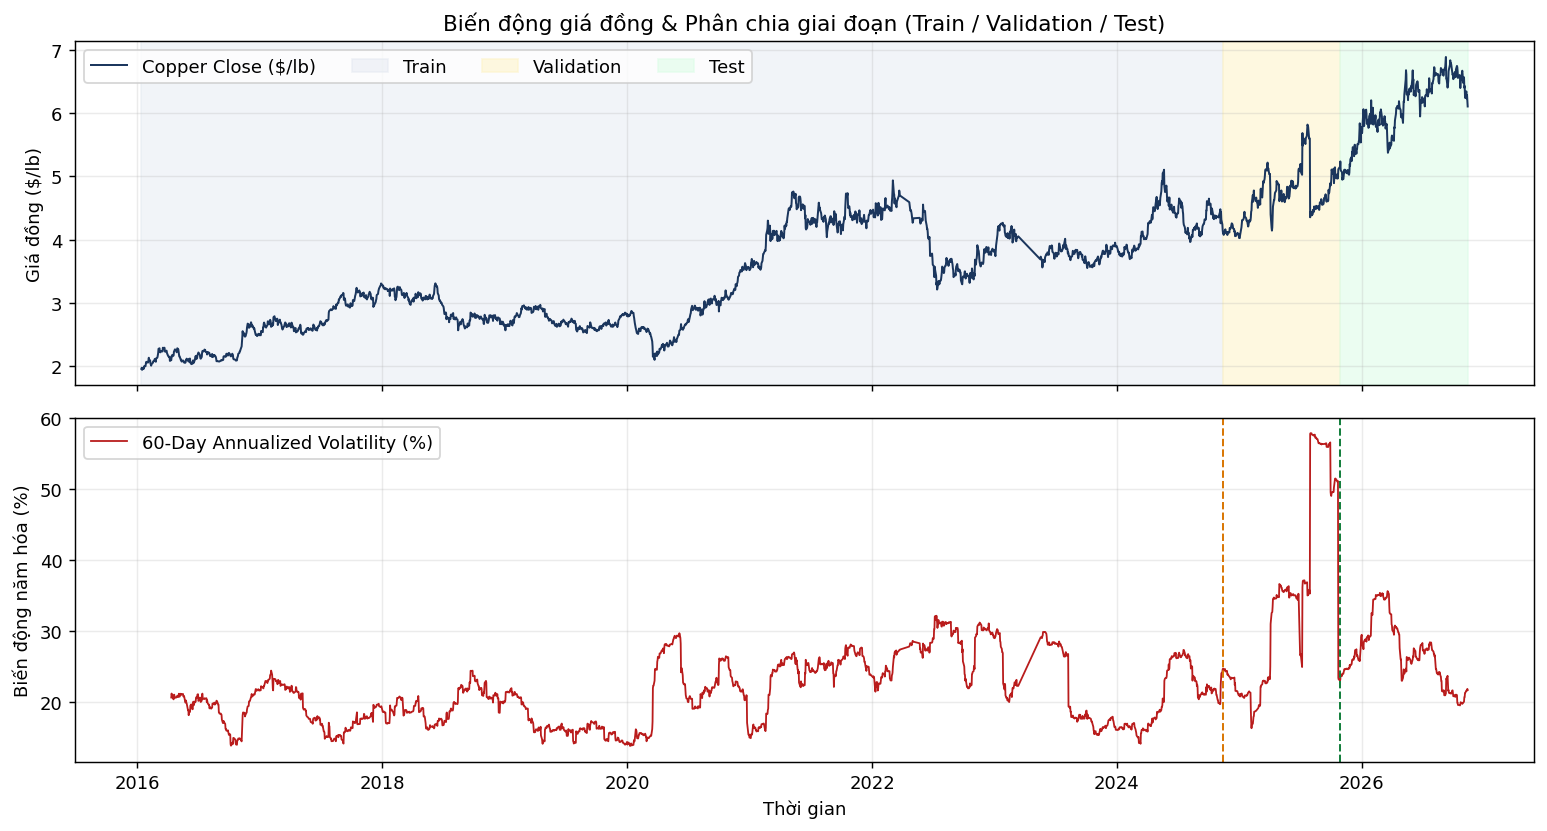

In [2]:
def load_and_audit_data(path: Path, out_dir: Path, max_rows: int | None = None):
    source = pd.read_csv(path)
    required = ["Date", "Copper"] + CANDIDATES
    missing_cols = sorted(set(required) - set(source.columns))
    if missing_cols:
        raise ValueError(f"Thiếu các cột bắt buộc: {missing_cols}")

    dates = pd.to_datetime(source["Date"], errors="coerce")
    invalid_dates = int(dates.isna().sum())
    dup_dates = int(dates.duplicated().sum())
    if invalid_dates > 0 or dup_dates > 0:
        raise ValueError(f"Dữ liệu có {invalid_dates} ngày lỗi và {dup_dates} ngày trùng lặp.")

    numeric = source[["Copper"] + CANDIDATES].apply(pd.to_numeric, errors="coerce")
    numeric = numeric.replace([np.inf, -np.inf], np.nan)
    data = numeric.copy()
    data.insert(0, "Date", dates)
    data = data.sort_values("Date").dropna().set_index("Date")
    if max_rows is not None:
        data = data.tail(max_rows).copy()

    assert data.index.is_unique and data.index.is_monotonic_increasing, "Chuỗi thời gian không hợp lệ."
    assert np.isfinite(data.to_numpy()).all(), "Dữ liệu sau làm sạch vẫn chứa NaN/Inf."

    quality = pd.DataFrame([{
        "column": col,
        "missing_raw": int(numeric[col].isna().sum()),
        "rows_used": len(data),
        "first_date": str(data.index.min().date()),
        "last_date": str(data.index.max().date()),
        "min": float(data[col].min()),
        "max": float(data[col].max()),
        "mean": float(data[col].mean()),
        "std": float(data[col].std()),
    } for col in ["Copper"] + CANDIDATES])
    quality.to_csv(out_dir / "data_quality_audit.csv", index=False)
    return data, quality

def boundaries(n: int, ratio: float = PRIMARY_RATIO, val_fraction: float = VALIDATION_FRACTION):
    test_start = int(n * ratio)
    val_start = int(test_start * (1 - val_fraction))
    if not (0 < val_start < test_start < n):
        raise ValueError(f"Khoảng chia không hợp lệ: val_start={val_start}, test_start={test_start}, n={n}")
    return val_start, test_start

data, quality_df = load_and_audit_data(DATA_PATH, OUT_DIR, CFG["max_rows"])
fit_end_primary, test_start_primary = boundaries(len(data), PRIMARY_RATIO, VALIDATION_FRACTION)

print(f"Tổng số phiên hoàn chỉnh: {len(data)} ({data.index.min().date()} -> {data.index.max().date()})")
print(f"Primary Split (ratio={PRIMARY_RATIO}):")
print(f"  - Train     : 0 -> {fit_end_primary-1} ({data.index[0].date()} -> {data.index[fit_end_primary-1].date()}) | {fit_end_primary} phiên")
print(f"  - Validation: {fit_end_primary} -> {test_start_primary-1} ({data.index[fit_end_primary].date()} -> {data.index[test_start_primary-1].date()}) | {test_start_primary - fit_end_primary} phiên")
print(f"  - Test      : {test_start_primary} -> {len(data)-1} ({data.index[test_start_primary].date()} -> {data.index[-1].date()}) | {len(data) - test_start_primary} phiên")
display(quality_df)

# Biểu đồ 1: Giá đồng 2016-2026 & Biến động lăn (Chứng minh sự dịch chuyển phân phối theo thời gian)
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].plot(data.index, data["Copper"], color="#1B365D", linewidth=1.1, label="Copper Close ($/lb)")
axes[0].axvspan(data.index[0], data.index[fit_end_primary - 1], color="#E2E8F0", alpha=0.45, label="Train")
axes[0].axvspan(data.index[fit_end_primary], data.index[test_start_primary - 1], color="#FEF3C7", alpha=0.55, label="Validation")
axes[0].axvspan(data.index[test_start_primary], data.index[-1], color="#DCFCE7", alpha=0.55, label="Test")
axes[0].set_ylabel("Giá đồng ($/lb)")
axes[0].set_title("Biến động giá đồng & Phân chia giai đoạn (Train / Validation / Test)")
axes[0].legend(loc="upper left", ncol=4)

roll_vol = data["Copper"].pct_change().rolling(60).std() * np.sqrt(252) * 100
axes[1].plot(data.index, roll_vol, color="#B91C1C", linewidth=1.0, label="60-Day Annualized Volatility (%)")
axes[1].axvline(data.index[fit_end_primary], color="#D97706", linestyle="--", linewidth=1.1)
axes[1].axvline(data.index[test_start_primary], color="#15803D", linestyle="--", linewidth=1.1)
axes[1].set_ylabel("Biến động năm hóa (%)")
axes[1].set_xlabel("Thời gian")
axes[1].legend(loc="upper left")
plt.tight_layout()
fig.savefig(OUT_DIR / "fig1_copper_regimes_volatility.png", dpi=150)
plt.show()

## 3. Kiến trúc LSTM & Bộ máy Walk-Forward

Gồm 3 thành phần lõi:
1. `make_windows` & `make_walk_forward_fold`: tạo cửa sổ `lookback = 22, horizon = 1` và kiểm định assertion chống rò rỉ ở từng fold.
2. `build_lstm_model`: kiến trúc 2 tầng LSTM (`39 → 111`, Dropout `0.2`, Adam `lr = 5e-5`, MSE loss), hỗ trợ `cold_start` / `warm_start`.
3. `run_forecasting_strategy`: thực thi thống nhất cả 5 chiến lược (`static_train_only`, `static_train_val`, `expanding_window`, `rolling_window`, `naive_persistence`) cho cả Direct và Residual.

In [3]:
def make_windows(x_scaled: np.ndarray, y_scaled: np.ndarray, dates: pd.DatetimeIndex,
                 start: int, end: int, lookback: int = LOOKBACK):
    if start < lookback or end <= start:
        raise ValueError(f"Khoảng cửa sổ không hợp lệ: start={start}, end={end}, lookback={lookback}")
    X = np.stack([x_scaled[t - lookback:t] for t in range(start, end)]).astype("float32")
    y = y_scaled[start:end].astype("float32")
    target_dates = dates[start:end]
    return X, y, target_dates

def make_walk_forward_fold(
    data: pd.DataFrame,
    fit_start: int,
    origin: int,
    block_end: int,
    features: list[str],
    lookback: int = LOOKBACK,
    target_mode: str = "direct",
):
    """Tạo 1 bước Walk-Forward (direct hoặc residual theo chuẩn Khoa/Công: delta trên thang MinMax của Copper)."""
    assert 0 <= fit_start < origin < block_end <= len(data), "Thứ tự chỉ số không hợp lệ."
    assert origin - fit_start > lookback + 10, "Cửa sổ huấn luyện quá ngắn so với lookback."
    if target_mode not in ("direct", "residual"):
        raise ValueError(f"target_mode không hợp lệ: {target_mode}")

    fit_df = data.iloc[fit_start:origin]
    x_scaler = MinMaxScaler().fit(fit_df[features])
    y_scaler = MinMaxScaler().fit(fit_df[["Copper"]])

    visible = data.iloc[fit_start:block_end]
    x_vis = x_scaler.transform(visible[features]).astype("float32")
    y_price_vis = y_scaler.transform(visible[["Copper"]]).ravel().astype("float32")

    local_origin = origin - fit_start
    local_end = block_end - fit_start

    X_train, y_train_price, train_dates = make_windows(x_vis, y_price_vis, visible.index, lookback, local_origin, lookback)
    X_eval, y_eval_price, eval_dates = make_windows(x_vis, y_price_vis, visible.index, local_origin, local_end, lookback)

    prev_train_scaled = y_price_vis[lookback - 1:local_origin - 1].astype("float32")
    prev_eval_scaled = y_price_vis[local_origin - 1:local_end - 1].astype("float32")

    if target_mode == "direct":
        y_train = y_train_price
        y_eval = y_eval_price
    else:
        # Chuẩn Khoa/Công: mạng học delta_y_t = y_scaled(t) - y_scaled(t-1), giá trị 0 tương ứng đứng yên
        y_train = (y_train_price - prev_train_scaled).astype("float32")
        y_eval = (y_eval_price - prev_eval_scaled).astype("float32")

    # Kiểm định bất biến chống rò rỉ dữ liệu
    assert train_dates.max() < eval_dates.min(), "Rò rỉ ngày giữa tập train và tập dự báo!"
    assert len(eval_dates) == (block_end - origin), "Thiếu mẫu dự báo trong block!"

    return {
        "X_train": X_train,
        "y_train": y_train,
        "train_dates": train_dates,
        "X_eval": X_eval,
        "y_eval_scaled": y_eval,
        "eval_dates": eval_dates,
        "y_eval_prev_scaled": prev_eval_scaled,
        "y_eval_actual": data["Copper"].iloc[origin:block_end].to_numpy(dtype=float),
        "y_eval_prev": data["Copper"].shift(1).iloc[origin:block_end].to_numpy(dtype=float),
        "x_scaler": x_scaler,
        "y_scaler": y_scaler,
        "target_mode": target_mode,
    }

def compute_metrics(actual: np.ndarray, predicted: np.ndarray, prev_actual: np.ndarray,
                    y_train_for_mase: np.ndarray | None = None) -> dict:
    actual = np.asarray(actual, dtype=float).ravel()
    predicted = np.asarray(predicted, dtype=float).ravel()
    prev_actual = np.asarray(prev_actual, dtype=float).ravel()

    assert actual.shape == predicted.shape == prev_actual.shape
    assert np.isfinite(actual).all() and np.isfinite(predicted).all()

    mae = float(mean_absolute_error(actual, predicted))
    mse = float(mean_squared_error(actual, predicted))
    rmse = float(math.sqrt(mse))
    mape = float(np.mean(np.abs((actual - predicted) / np.clip(np.abs(actual), 1e-8, None))) * 100.0)
    naive_mae = float(mean_absolute_error(actual, prev_actual))

    if y_train_for_mase is not None and len(y_train_for_mase) > 1:
        in_sample_naive_mae = float(np.mean(np.abs(np.diff(y_train_for_mase))))
        mase = mae / max(in_sample_naive_mae, 1e-8)
    else:
        mase = mae / max(naive_mae, 1e-8)
    rel_mae_vs_naive = mae / max(naive_mae, 1e-8)

    d_act = actual - prev_actual
    d_pred = predicted - prev_actual
    if np.allclose(d_pred, 0.0):
        da_pct = float("nan")
        delta_corr = 0.0
        delta_std_ratio = 0.0
    else:
        nz = d_act != 0
        da_pct = float(np.mean(np.sign(d_pred[nz]) == np.sign(d_act[nz])) * 100.0) if nz.any() else float("nan")
        delta_corr = float(np.corrcoef(d_act, d_pred)[0, 1]) if (np.std(d_pred) > 1e-12 and np.std(d_act) > 1e-12) else 0.0
        delta_std_ratio = float(np.std(d_pred) / max(np.std(d_act), 1e-12))

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MSE_price2": mse,
        "MASE": float(mase),
        "Rel_MAE_Naive": float(rel_mae_vs_naive),
        "MAPE_pct": mape,
        "R2": float(r2_score(actual, predicted)) if len(actual) > 1 else float("nan"),
        "DA_pct": da_pct,
        "Delta_Corr": delta_corr,
        "Delta_Std_Ratio": delta_std_ratio,
    }


In [4]:
def build_lstm_model(n_features: int, lookback: int = LOOKBACK,
                     hp: dict = ACTIVE_HP, lr_multiplier: float = 1.0) -> tf.keras.Model:
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(lookback, n_features)),
        tf.keras.layers.LSTM(int(hp["lstm_units_1"]), activation="tanh",
                             recurrent_activation="sigmoid", return_sequences=True),
        tf.keras.layers.LSTM(int(hp["lstm_units_2"]), activation="tanh",
                             recurrent_activation="sigmoid"),
        tf.keras.layers.Dense(DENSE_UNITS, activation="relu"),
        tf.keras.layers.Dropout(DROPOUT),
        tf.keras.layers.Dense(1, activation="linear"),
    ])
    lr = float(hp["learning_rate"]) * lr_multiplier
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss="mse")
    return model

def fit_and_predict_fold(
    fold: dict,
    hp: dict = ACTIVE_HP,
    epochs: int = 30,
    prev_weights=None,
    update_mode: str = "cold_start",
    seed: int = SEED,
):
    tf.keras.backend.clear_session()
    set_global_seed(seed)

    n_features = fold["X_train"].shape[-1]
    use_warm = (update_mode == "warm_start") and (prev_weights is not None)
    model = build_lstm_model(n_features, LOOKBACK, hp, lr_multiplier=0.5 if use_warm else 1.0)
    if use_warm:
        model.set_weights(prev_weights)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="loss", patience=7, restore_best_weights=True, min_delta=1e-6
        )
    ]
    t0 = time.perf_counter()
    model.fit(
        fold["X_train"],
        fold["y_train"],
        epochs=epochs,
        batch_size=BATCH_SIZE,
        shuffle=False,
        verbose=0,
        callbacks=callbacks,
    )
    train_sec = time.perf_counter() - t0

    # Gọi trực tiếp model(..., training=False) giúp tránh retracing warning & nhanh hơn model.predict()
    pred_out = model(fold["X_eval"], training=False).numpy().ravel()
    if fold.get("target_mode", "direct") == "residual":
        pred_price_scaled = (fold["y_eval_prev_scaled"] + pred_out).reshape(-1, 1)
    else:
        pred_price_scaled = pred_out.reshape(-1, 1)

    pred_price = fold["y_scaler"].inverse_transform(pred_price_scaled).ravel()
    new_weights = model.get_weights()

    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return pred_price, train_sec, new_weights


In [5]:
def run_forecasting_strategy(
    data: pd.DataFrame,
    strategy: str,
    eval_start: int,
    eval_end: int,
    features: list[str],
    hp: dict = ACTIVE_HP,
    window_size: int = 504,
    stride: int = 20,
    update_mode: str = "cold_start",
    base_epochs: int = CFG["base_epochs"],
    cold_epochs: int = CFG["cold_epochs"],
    warm_epochs: int = CFG["warm_epochs"],
    static_fit_end: int | None = None,
    seed: int = SEED,
    target_mode: str = "direct",
):
    """Chạy 1 chiến lược dự báo trên đoạn [eval_start, eval_end) không rò rỉ dữ liệu."""
    if strategy == "naive_persistence":
        dates = data.index[eval_start:eval_end]
        actual = data["Copper"].iloc[eval_start:eval_end].to_numpy(dtype=float)
        prev = data["Copper"].shift(1).iloc[eval_start:eval_end].to_numpy(dtype=float)
        df_pred = pd.DataFrame({
            "Date": dates,
            "actual": actual,
            "predicted": prev,
            "prev_actual": prev,
            "error": prev - actual,
            "abs_error": np.abs(prev - actual),
            "sq_error": (prev - actual) ** 2,
            "retrain_origin": eval_start,
        })
        m = compute_metrics(actual, prev, prev, data["Copper"].iloc[:eval_start].to_numpy(dtype=float))
        m.update({"target_mode": target_mode, "strategy": strategy, "n_retrains": 0, "total_train_sec": 0.0, "sec_per_retrain": 0.0})
        return m, df_pred

    if strategy in ("static_train_only", "static_train_val"):
        fit_end = static_fit_end if (strategy == "static_train_only" and static_fit_end is not None) else eval_start
        fold = make_walk_forward_fold(
            data=data, fit_start=0, origin=fit_end, block_end=eval_end, features=features, lookback=LOOKBACK, target_mode=target_mode
        )
        # Nếu fit_end < eval_start (static_train_only), cắt đúng đoạn [eval_start, eval_end) sau khi predict
        pred_all, train_sec, _ = fit_and_predict_fold(
            fold, hp=hp, epochs=base_epochs, prev_weights=None, update_mode="cold_start", seed=seed
        )
        offset = eval_start - fit_end
        dates = fold["eval_dates"][offset:]
        actual = fold["y_eval_actual"][offset:]
        prev = fold["y_eval_prev"][offset:]
        pred = pred_all[offset:]

        df_pred = pd.DataFrame({
            "Date": dates,
            "actual": actual,
            "predicted": pred,
            "prev_actual": prev,
            "error": pred - actual,
            "abs_error": np.abs(pred - actual),
            "sq_error": (pred - actual) ** 2,
            "retrain_origin": fit_end,
        })
        m = compute_metrics(actual, pred, prev, data["Copper"].iloc[:fit_end].to_numpy(dtype=float))
        m.update({"target_mode": target_mode, "strategy": strategy, "n_retrains": 1, "total_train_sec": train_sec, "sec_per_retrain": train_sec})
        return m, df_pred

    if strategy in ("expanding_window", "rolling_window"):
        origins = list(range(eval_start, eval_end, stride))
        all_frames = []
        total_sec = 0.0
        prev_weights = None

        for step_idx, origin in enumerate(origins):
            block_end = min(origin + stride, eval_end)
            fit_start = 0 if strategy == "expanding_window" else max(0, origin - window_size)
            fold = make_walk_forward_fold(
                data=data, fit_start=fit_start, origin=origin, block_end=block_end, features=features, lookback=LOOKBACK, target_mode=target_mode
            )
            epochs = base_epochs if step_idx == 0 else (warm_epochs if update_mode == "warm_start" else cold_epochs)
            pred_block, sec, prev_weights = fit_and_predict_fold(
                fold,
                hp=hp,
                epochs=epochs,
                prev_weights=prev_weights,
                update_mode=update_mode,
                seed=seed + step_idx,
            )
            total_sec += sec
            all_frames.append(pd.DataFrame({
                "Date": fold["eval_dates"],
                "actual": fold["y_eval_actual"],
                "predicted": pred_block,
                "prev_actual": fold["y_eval_prev"],
                "error": pred_block - fold["y_eval_actual"],
                "abs_error": np.abs(pred_block - fold["y_eval_actual"]),
                "sq_error": (pred_block - fold["y_eval_actual"]) ** 2,
                "retrain_origin": origin,
            }))

        df_pred = pd.concat(all_frames, ignore_index=True)
        assert len(df_pred) == (eval_end - eval_start)
        m = compute_metrics(
            df_pred["actual"].to_numpy(),
            df_pred["predicted"].to_numpy(),
            df_pred["prev_actual"].to_numpy(),
            data["Copper"].iloc[:eval_start].to_numpy(dtype=float),
        )
        m.update({
            "target_mode": target_mode,
            "strategy": strategy,
            "n_retrains": len(origins),
            "total_train_sec": total_sec,
            "sec_per_retrain": total_sec / max(1, len(origins)),
        })
        return m, df_pred

    raise ValueError(f"Unknown strategy: {strategy}")

## 4. Thực nghiệm Walk-Forward (Phase 1 → Phase 5)

### 4.1. Phase 1 — Chọn chính sách Walk-Forward trên tập Validation
Sàng lọc lưới `window_size W ∈ {252, 504, 756}`, `stride S ∈ {20, 40}`, `update_mode ∈ {cold_start, warm_start}` trên tập Validation (không chạm tập Test) → chọn `W* = 756, S* = 40, cold_start`.

In [6]:
val_screening_rows = []
print("=== PHASE 1: VALIDATION WALK-FORWARD SCREENING (FEATURES_4) ===")

# Benchmark Static & Naive trên tập Validation trước
for strat in ["naive_persistence", "static_train_only"]:
    m, _ = run_forecasting_strategy(
        data, strat, fit_end_primary, test_start_primary, FEATURES_4,
        static_fit_end=fit_end_primary, seed=SEED
    )
    val_screening_rows.append({
        "strategy": strat, "window_size": "full", "stride": "-", "update_mode": "-",
        **{k: m[k] for k in ["MAE", "RMSE", "MASE", "Rel_MAE_Naive", "n_retrains", "total_train_sec"]}
    })

# Quét lưới Rolling Window trên tập Validation
for w in CFG["val_windows"]:
    for s in CFG["val_strides"]:
        for u_mode in CFG["val_update_modes"]:
            m, _ = run_forecasting_strategy(
                data, "rolling_window", fit_end_primary, test_start_primary, FEATURES_4,
                window_size=w, stride=s, update_mode=u_mode, seed=SEED
            )
            val_screening_rows.append({
                "strategy": "rolling_window", "window_size": w, "stride": s, "update_mode": u_mode,
                **{k: m[k] for k in ["MAE", "RMSE", "MASE", "Rel_MAE_Naive", "n_retrains", "total_train_sec"]}
            })
            print(f"  Rolling W={w}, S={s}, {u_mode:10s} -> Val MAE={m['MAE']:.4f}, RMSE={m['RMSE']:.4f}, sec={m['total_train_sec']:.1f}s")

# Kiểm tra Expanding Window trên tập Validation với cùng strides
for s in CFG["val_strides"]:
    for u_mode in CFG["val_update_modes"]:
        m, _ = run_forecasting_strategy(
            data, "expanding_window", fit_end_primary, test_start_primary, FEATURES_4,
            stride=s, update_mode=u_mode, seed=SEED
        )
        val_screening_rows.append({
            "strategy": "expanding_window", "window_size": "expanding", "stride": s, "update_mode": u_mode,
            **{k: m[k] for k in ["MAE", "RMSE", "MASE", "Rel_MAE_Naive", "n_retrains", "total_train_sec"]}
        })
        print(f"  Expanding S={s}, {u_mode:10s} -> Val MAE={m['MAE']:.4f}, RMSE={m['RMSE']:.4f}, sec={m['total_train_sec']:.1f}s")

val_screening_df = pd.DataFrame(val_screening_rows).sort_values("MAE").reset_index(drop=True)
val_screening_df.to_csv(OUT_DIR / "phase1_validation_screening.csv", index=False)
display(val_screening_df)

# Khóa cấu hình Rolling tốt nhất từ Validation
best_rolling_row = val_screening_df[val_screening_df["strategy"] == "rolling_window"].iloc[0]
BEST_W = int(best_rolling_row["window_size"])
BEST_S = int(best_rolling_row["stride"])
BEST_UPDATE_MODE = str(best_rolling_row["update_mode"])
print(f"\n>>> CHỐT CẤU HÌNH TỪ VALIDATION: W*={BEST_W}, S*={BEST_S}, update_mode*={BEST_UPDATE_MODE}")

=== PHASE 1: VALIDATION WALK-FORWARD SCREENING (FEATURES_4) ===
  Rolling W=252, S=20, cold_start -> Val MAE=0.2820, RMSE=0.3611, sec=63.0s
  Rolling W=252, S=20, warm_start -> Val MAE=0.2979, RMSE=0.3777, sec=35.6s
  Rolling W=252, S=40, cold_start -> Val MAE=0.2677, RMSE=0.3315, sec=33.2s
  Rolling W=252, S=40, warm_start -> Val MAE=0.2886, RMSE=0.3716, sec=20.4s
  Rolling W=504, S=20, cold_start -> Val MAE=0.2506, RMSE=0.3280, sec=73.4s
  Rolling W=504, S=20, warm_start -> Val MAE=0.2420, RMSE=0.3246, sec=39.9s
  Rolling W=504, S=40, cold_start -> Val MAE=0.2481, RMSE=0.3112, sec=39.5s
  Rolling W=504, S=40, warm_start -> Val MAE=0.2556, RMSE=0.3267, sec=22.9s
  Rolling W=756, S=20, cold_start -> Val MAE=0.2453, RMSE=0.3286, sec=88.9s
  Rolling W=756, S=20, warm_start -> Val MAE=0.2539, RMSE=0.3294, sec=48.2s
  Rolling W=756, S=40, cold_start -> Val MAE=0.2418, RMSE=0.3073, sec=47.3s
  Rolling W=756, S=40, warm_start -> Val MAE=0.2638, RMSE=0.3301, sec=29.2s
  Expanding S=20, cold_s

,strategy,window_size,stride,update_mode,MAE,RMSE,MASE,Rel_MAE_Naive,n_retrains,total_train_sec
0,naive_persistence,full,-,-,0.061451,0.117989,1.791084,1.000000,0,0.000000
1,rolling_window,756,40,cold_start,0.241762,0.307272,7.046543,3.934234,7,47.266995
2,rolling_window,504,20,warm_start,0.242009,0.324584,7.053742,3.938254,13,39.850557
3,rolling_window,756,20,cold_start,0.245250,0.328573,7.148218,3.991002,13,88.925524
4,rolling_window,504,40,cold_start,0.248070,0.311230,7.230400,4.036886,7,39.475631
5,rolling_window,504,20,cold_start,0.250625,0.327995,7.304876,4.078467,13,73.449018
6,rolling_window,756,20,warm_start,0.253885,0.329405,7.399894,4.131518,13,48.203415
7,rolling_window,504,40,warm_start,0.255578,0.326673,7.449232,4.159064,7,22.874393
8,expanding_window,expanding,20,warm_start,0.255634,0.327896,7.450873,4.159981,13,68.890637
9,expanding_window,expanding,40,cold_start,0.261044,0.328509,7.608538,4.248008,7,86.889841



>>> CHỐT CẤU HÌNH TỪ VALIDATION: W*=756, S*=40, update_mode*=cold_start


### 4.2. Phase 2 — Đánh giá chính (6 bộ biến × 4 chiến lược × Direct/Residual), Cross-Ratio (4 mốc chia) & 5 Seeds (`41–45`)

In [7]:
main_test_rows = []
test_predictions = {}  # Lưu prediction DataFrame cho Phase 4, Phase 5 & Charts

FEATURE_LIST = [
    ("FS01_CU", FS01_CU),
    ("FEATURES_4", FEATURES_4),
    ("FEATURES_3", FEATURES_3),
    ("FS04_METALS_CU", FS04_METALS_CU),
    ("FS05_METALS_EXO", FS05_METALS_EXO),
    ("FS06_WTI_CU", FS06_WTI_CU),
]

for t_mode in ["direct", "residual"]:
    for feat_label, feat_cols in FEATURE_LIST:
        print(f"\n=== PHASE 2 [{t_mode.upper()}]: TEST EVALUATION ({feat_label}: {feat_cols}) ===")
        for strat in ["naive_persistence", "static_train_only", "static_train_val", "expanding_window", "rolling_window"]:
            if not (t_mode == "direct" and feat_label == "FEATURES_4") and strat == "naive_persistence":
                continue  # Naive giống hệt nhau trên cùng split 90/10
            m, df_pred = run_forecasting_strategy(
                data=data,
                strategy=strat,
                eval_start=test_start_primary,
                eval_end=len(data),
                features=feat_cols,
                window_size=BEST_W,
                stride=BEST_S,
                update_mode=BEST_UPDATE_MODE,
                static_fit_end=fit_end_primary,
                seed=SEED,
                target_mode=t_mode,
            )
            key = f"{feat_label}__{strat}" if t_mode == "direct" else f"RESIDUAL__{feat_label}__{strat}"
            test_predictions[key] = df_pred
            df_pred.to_csv(OUT_DIR / f"pred_{key}.csv", index=False)
            main_test_rows.append({"feature_set": feat_label, **m})
            print(
                f"  [{t_mode:8s}] {strat:18s} | MAE={m['MAE']:.4f} | RMSE={m['RMSE']:.4f} | MASE={m['MASE']:.4f} "
                f"| R2={m['R2']:.4f} | DA={m['DA_pct']:.2f}% | Retrains={m['n_retrains']} | Time={m['total_train_sec']:.1f}s"
            )

main_test_df = pd.DataFrame(main_test_rows)
naive_row = main_test_df[main_test_df["strategy"] == "naive_persistence"].iloc[0]
main_test_df["Delta_MAE_vs_Naive_pct"] = (main_test_df["MAE"] / float(naive_row["MAE"]) - 1.0) * 100.0
main_test_df["Delta_RMSE_vs_Naive_pct"] = (main_test_df["RMSE"] / float(naive_row["RMSE"]) - 1.0) * 100.0

main_test_df.to_csv(OUT_DIR / "phase2_main_test_results.csv", index=False)
main_test_df.to_csv(OUT_DIR / "benchmark_complete_metrics.csv", index=False)
display(
    main_test_df[
        [
            "target_mode", "feature_set", "strategy", "MAE", "RMSE", "MSE_price2", "MASE",
            "MAPE_pct", "R2", "DA_pct", "Delta_MAE_vs_Naive_pct", "Delta_Corr", "Delta_Std_Ratio",
            "n_retrains", "total_train_sec",
        ]
    ]
)

# Cross-ratio 4 mốc [0.80, 0.90, 0.925, 0.95] cho CẢ direct & residual (FEATURES_4)
cross_ratio_rows = []
if CFG["run_cross_ratio"]:
    print(f"\n=== CROSS-RATIO ROBUSTNESS 4 SPLITS (FEATURES_4, DIRECT & RESIDUAL) ===")
    for t_mode in ["direct", "residual"]:
        for r in RATIOS:
            fe, ts = boundaries(len(data), r, VALIDATION_FRACTION)
            ratio_strats = {}
            for strat in ["naive_persistence", "static_train_only", "static_train_val", "expanding_window", "rolling_window"]:
                if t_mode == "residual" and strat == "naive_persistence":
                    continue
                if abs(r - PRIMARY_RATIO) < 1e-9:
                    # Tái sử dụng kết quả đã chạy ở Phase 2 cho PRIMARY_RATIO=0.90 (tránh chạy lặp lại)
                    match_r = main_test_df[(main_test_df["target_mode"] == t_mode) & (main_test_df["feature_set"] == "FEATURES_4") & (main_test_df["strategy"] == strat)]
                    m = match_r.iloc[0].to_dict()
                else:
                    m, _ = run_forecasting_strategy(
                        data, strat, ts, len(data), FEATURES_4,
                        window_size=BEST_W, stride=BEST_S, update_mode=BEST_UPDATE_MODE,
                        static_fit_end=fe, seed=SEED, target_mode=t_mode,
                    )
                row = {"ratio": r, "n_test": len(data) - ts, **m}
                cross_ratio_rows.append(row)
                ratio_strats[strat] = m
            # Reference naive MAE/RMSE at this split
            n_m, _ = run_forecasting_strategy(data, "naive_persistence", ts, len(data), FEATURES_4, seed=SEED)
            n_mae_r, n_rmse_r = float(n_m["MAE"]), float(n_m["RMSE"])
            n_added = 5 if t_mode == "direct" else 4
            for row in cross_ratio_rows[-n_added:]:
                row["Delta_MAE_vs_Naive_pct"] = (row["MAE"] / n_mae_r - 1.0) * 100.0
                row["Delta_RMSE_vs_Naive_pct"] = (row["RMSE"] / n_rmse_r - 1.0) * 100.0
            print(
                f"  [{t_mode:8s}] Ratio {r:.3f} (n={len(data)-ts}) | Exp MAE={ratio_strats['expanding_window']['MAE']:.4f} "
                f"| Roll MAE={ratio_strats['rolling_window']['MAE']:.4f} | Naive MAE={n_mae_r:.4f}"
            )

    cross_ratio_df = pd.DataFrame(cross_ratio_rows)
    cross_ratio_df.to_csv(OUT_DIR / "phase2_cross_ratio_results.csv", index=False)
    for t_m in ["direct", "residual"]:
        print(f"\n--- Pivot MAE qua 4 mốc chia [{t_m.upper()}] ---")
        display(cross_ratio_df[cross_ratio_df["target_mode"] == t_m].pivot(index="strategy", columns="ratio", values="MAE"))

# Phase 2B: Multi-Seed Stability Check (SEEDS_MULTI = [41..45]) cho Expanding Direct & Residual trên FEATURES_4 (Split 90/10)
multiseed_rows = []
if MODE == "FULL_RESEARCH_MODE":
    print(f"\n=== PHASE 2B: MULTI-SEED STABILITY CHECK ({SEEDS_MULTI}) ===")
    naive_90 = test_predictions["FEATURES_4__naive_persistence"]
    for t_mode in ["direct", "residual"]:
        for s_val in SEEDS_MULTI:
            if s_val == SEED:
                k_cached = "FEATURES_4__expanding_window" if t_mode == "direct" else "RESIDUAL__FEATURES_4__expanding_window"
                df_s = test_predictions[k_cached]
                m_s = main_test_df[(main_test_df["target_mode"] == t_mode) & (main_test_df["feature_set"] == "FEATURES_4") & (main_test_df["strategy"] == "expanding_window")].iloc[0].to_dict()
            else:
                m_s, df_s = run_forecasting_strategy(
                    data, "expanding_window", test_start_primary, len(data), FEATURES_4,
                    window_size=BEST_W, stride=BEST_S, update_mode=BEST_UPDATE_MODE,
                    static_fit_end=fit_end_primary, seed=s_val, target_mode=t_mode,
                )
            e_a = df_s["actual"].to_numpy() - df_s["predicted"].to_numpy()
            e_b = naive_90["actual"].to_numpy() - naive_90["predicted"].to_numpy()
            d_l1 = np.abs(e_a) - np.abs(e_b)
            T_dm = len(d_l1)
            dm_l1 = float(np.mean(d_l1) / math.sqrt(max(float(np.var(d_l1, ddof=0)), 1e-18) / T_dm))
            p_l1 = float(2.0 * stats.t.sf(abs(dm_l1), df=T_dm - 1))
            multiseed_rows.append({
                "target_mode": t_mode,
                "seed": s_val,
                "MAE": m_s["MAE"],
                "RMSE": m_s["RMSE"],
                "MASE": m_s["MASE"],
                "R2": m_s["R2"],
                "DA_pct": m_s["DA_pct"],
                "Delta_MAE_vs_Naive_pct": (m_s["MAE"] / float(naive_row["MAE"]) - 1.0) * 100.0,
                "DM_L1_vs_Naive": dm_l1,
                "DM_L1_p_value": p_l1,
                "total_train_sec": m_s["total_train_sec"],
            })
            print(f"  [{t_mode:8s}] Seed={s_val} | MAE={m_s['MAE']:.5f} | RMSE={m_s['RMSE']:.5f} | DA={m_s['DA_pct']:.2f}% | DM_p={p_l1:.4f}")
    multiseed_df = pd.DataFrame(multiseed_rows)
    multiseed_df.to_csv(OUT_DIR / "phase2b_multiseed_stability.csv", index=False)
    summary_ms = multiseed_df.groupby("target_mode")[["MAE", "RMSE", "DA_pct", "Delta_MAE_vs_Naive_pct"]].agg(["mean", "std"])
    display(summary_ms)



=== PHASE 2 [DIRECT]: TEST EVALUATION (FS01_CU: ['Copper']) ===
  [direct  ] static_train_only  | MAE=0.4928 | RMSE=0.5342 | MASE=14.3635 | R2=-0.1782 | DA=46.84% | Retrains=1 | Time=13.1s
  [direct  ] static_train_val   | MAE=0.3355 | RMSE=0.3776 | MASE=9.0626 | R2=0.4112 | DA=47.58% | Retrains=1 | Time=15.3s
  [direct  ] expanding_window   | MAE=0.2026 | RMSE=0.2595 | MASE=5.4732 | R2=0.7219 | DA=53.90% | Retrains=7 | Time=84.3s
  [direct  ] rolling_window     | MAE=0.2739 | RMSE=0.3337 | MASE=7.3987 | R2=0.5402 | DA=50.56% | Retrains=7 | Time=43.9s

=== PHASE 2 [DIRECT]: TEST EVALUATION (FEATURES_4: ['Copper', 'WTI', 'Gold', 'Silver']) ===
  [direct  ] naive_persistence  | MAE=0.0771 | RMSE=0.1010 | MASE=2.0817 | R2=0.9579 | DA=nan% | Retrains=0 | Time=0.0s
  [direct  ] static_train_only  | MAE=1.5516 | RMSE=1.6156 | MASE=45.2235 | R2=-9.7766 | DA=46.84% | Retrains=1 | Time=13.0s
  [direct  ] static_train_val   | MAE=0.2869 | RMSE=0.3308 | MASE=7.7477 | R2=0.5481 | DA=48.33% | Retr

,target_mode,feature_set,strategy,MAE,RMSE,MSE_price2,MASE,MAPE_pct,R2,DA_pct,Delta_MAE_vs_Naive_pct,Delta_Corr,Delta_Std_Ratio,n_retrains,total_train_sec
0,direct,FS01_CU,static_train_only,0.492800,0.534201,0.285370,14.363460,7.942178,-0.178235,46.840149,539.362988,0.198427,2.032250,1,13.129949
1,direct,FS01_CU,static_train_val,0.335549,0.377622,0.142598,9.062602,5.399842,0.411242,47.583643,335.343953,0.205323,1.811942,1,15.266292
2,direct,FS01_CU,expanding_window,0.202649,0.259548,0.067365,5.473197,3.375212,0.721864,53.903346,162.918220,0.144175,2.035062,7,84.271332
3,direct,FS01_CU,rolling_window,0.273943,0.333712,0.111364,7.398741,4.557281,0.540202,50.557621,255.416350,0.136495,2.303539,7,43.946948
4,direct,FEATURES_4,naive_persistence,0.077077,0.101033,0.010208,2.081711,1.277697,0.957855,NaN,0.000000,0.000000,0.000000,0,0.000000
5,direct,FEATURES_4,static_train_only,1.551586,1.615586,2.610117,45.223491,25.528386,-9.776635,46.840149,1913.040474,0.107013,4.453663,1,12.963671
6,direct,FEATURES_4,static_train_val,0.286864,0.330825,0.109445,7.747714,4.661557,0.548124,48.327138,272.180109,0.224457,1.821930,1,12.871108
7,direct,FEATURES_4,expanding_window,0.236960,0.294349,0.086641,6.399881,3.844313,0.642276,51.301115,207.433726,0.161979,1.942871,7,90.753377
8,direct,FEATURES_4,rolling_window,0.283715,0.340434,0.115895,7.662648,4.540924,0.521493,47.211896,268.093771,0.154970,2.312212,7,44.855746
9,direct,FEATURES_3,static_train_only,0.319903,0.385281,0.148441,9.324103,5.287763,0.387117,52.788104,315.045308,0.157166,3.828383,1,10.198000



=== CROSS-RATIO ROBUSTNESS 4 SPLITS (FEATURES_4, DIRECT & RESIDUAL) ===
  [direct  ] Ratio 0.800 (n=542) | Exp MAE=0.2592 | Roll MAE=0.2745 | Naive MAE=0.0690
  [direct  ] Ratio 0.900 (n=271) | Exp MAE=0.2370 | Roll MAE=0.2837 | Naive MAE=0.0771
  [direct  ] Ratio 0.925 (n=204) | Exp MAE=0.2770 | Roll MAE=0.4018 | Naive MAE=0.0751
  [direct  ] Ratio 0.950 (n=136) | Exp MAE=0.3444 | Roll MAE=0.4493 | Naive MAE=0.0728
  [residual] Ratio 0.800 (n=542) | Exp MAE=0.0711 | Roll MAE=0.0734 | Naive MAE=0.0690
  [residual] Ratio 0.900 (n=271) | Exp MAE=0.0785 | Roll MAE=0.0803 | Naive MAE=0.0771
  [residual] Ratio 0.925 (n=204) | Exp MAE=0.0771 | Roll MAE=0.0803 | Naive MAE=0.0751
  [residual] Ratio 0.950 (n=136) | Exp MAE=0.0757 | Roll MAE=0.0786 | Naive MAE=0.0728

--- Pivot MAE qua 4 mốc chia [DIRECT] ---


ratio,0.800,0.900,0.925,0.950
strategy,,,,
expanding_window,0.259217,0.236960,0.277022,0.344367
naive_persistence,0.069001,0.077077,0.075116,0.072799
rolling_window,0.274474,0.283715,0.401841,0.449289
static_train_only,1.099252,1.551586,1.515650,1.284500
static_train_val,1.021018,0.286864,0.364405,0.255923



--- Pivot MAE qua 4 mốc chia [RESIDUAL] ---


ratio,0.800,0.900,0.925,0.950
strategy,,,,
expanding_window,0.071084,0.078518,0.077142,0.075727
rolling_window,0.073442,0.080256,0.080321,0.078646
static_train_only,0.076681,0.109666,0.095933,0.101741
static_train_val,0.075046,0.078119,0.076841,0.072133



=== PHASE 2B: MULTI-SEED STABILITY CHECK ([41, 42, 43, 44, 45]) ===
  [direct  ] Seed=41 | MAE=0.29207 | RMSE=0.35185 | DA=49.81% | DM_p=0.0000
  [direct  ] Seed=42 | MAE=0.23696 | RMSE=0.29435 | DA=51.30% | DM_p=0.0000
  [direct  ] Seed=43 | MAE=0.23867 | RMSE=0.28423 | DA=50.19% | DM_p=0.0000
  [direct  ] Seed=44 | MAE=0.29922 | RMSE=0.34450 | DA=49.44% | DM_p=0.0000
  [direct  ] Seed=45 | MAE=0.32497 | RMSE=0.37067 | DA=49.44% | DM_p=0.0000
  [residual] Seed=41 | MAE=0.07742 | RMSE=0.10136 | DA=50.93% | DM_p=0.6734
  [residual] Seed=42 | MAE=0.07852 | RMSE=0.10224 | DA=47.21% | DM_p=0.0583
  [residual] Seed=43 | MAE=0.07913 | RMSE=0.10326 | DA=49.07% | DM_p=0.0420
  [residual] Seed=44 | MAE=0.07798 | RMSE=0.10190 | DA=49.07% | DM_p=0.2185
  [residual] Seed=45 | MAE=0.07834 | RMSE=0.10231 | DA=47.96% | DM_p=0.2138


MAE                RMSE               DA_pct            \
                 mean       std      mean       std       mean       std   
target_mode                                                                
direct       0.278379  0.039004  0.329119  0.037762  50.037175  0.770871   
residual     0.078280  0.000635  0.102214  0.000697  48.847584  1.405775   

            Delta_MAE_vs_Naive_pct             
                              mean        std  
target_mode                                    
direct                  261.170984  50.603977  
residual                  1.560648   0.823612

### 4.2b. Phase 2C — Kiểm định 5 Seeds bổ sung (`Rolling FS02 Direct/Residual` & `Expanding FS03 Residual`)

Bổ sung 5 seeds (`41–45`, mốc `90/10`) cho nhánh **Rolling Window (`W=756, S=40`, FS02)** và cấu hình đạt MAE thấp nhất ở seed 42 (**Expanding Residual `FS03`**) nhằm đảm bảo độ bao phủ 5-seed đồng đều giữa Rolling vs. Expanding và kiểm chứng xem kết quả `FS03` ở seed 42 có ổn định qua nhiều lần khởi tạo hay không.

In [ ]:
# Phase 2C: Multi-Seed bổ sung (SEEDS_MULTI = [41..45], Split 90/10) cho 3 cấu hình còn thiếu so với Phase 2B:
#   (a) Rolling Window  | FEATURES_4 (FS02) | Direct
#   (b) Rolling Window  | FEATURES_4 (FS02) | Residual
#   (c) Expanding Window| FEATURES_3 (FS03) | Residual  (cấu hình có MAE thấp nhất ở seed 42)
multiseed_ext_rows = []
EXT_CONFIGS = [
    ("FEATURES_4", FEATURES_4, "rolling_window", "direct"),
    ("FEATURES_4", FEATURES_4, "rolling_window", "residual"),
    ("FEATURES_3", FEATURES_3, "expanding_window", "residual"),
]
if MODE == "FULL_RESEARCH_MODE":
    print(f"\n=== PHASE 2C: EXTENDED MULTI-SEED CHECK ({SEEDS_MULTI}) ===")
    naive_90 = test_predictions["FEATURES_4__naive_persistence"]
    e_b = naive_90["actual"].to_numpy() - naive_90["predicted"].to_numpy()
    for feat_label, feat_cols, strat, t_mode in EXT_CONFIGS:
        for s_val in SEEDS_MULTI:
            if s_val == SEED:
                k_cached = f"{feat_label}__{strat}" if t_mode == "direct" else f"RESIDUAL__{feat_label}__{strat}"
                df_s = test_predictions[k_cached]
                m_s = main_test_df[(main_test_df["target_mode"] == t_mode) & (main_test_df["feature_set"] == feat_label) & (main_test_df["strategy"] == strat)].iloc[0].to_dict()
            else:
                m_s, df_s = run_forecasting_strategy(
                    data, strat, test_start_primary, len(data), feat_cols,
                    window_size=BEST_W, stride=BEST_S, update_mode=BEST_UPDATE_MODE,
                    static_fit_end=fit_end_primary, seed=s_val, target_mode=t_mode,
                )
            e_a = df_s["actual"].to_numpy() - df_s["predicted"].to_numpy()
            d_l1 = np.abs(e_a) - np.abs(e_b)
            T_dm = len(d_l1)
            dm_l1 = float(np.mean(d_l1) / math.sqrt(max(float(np.var(d_l1, ddof=0)), 1e-18) / T_dm))
            p_l1 = float(2.0 * stats.t.sf(abs(dm_l1), df=T_dm - 1))
            multiseed_ext_rows.append({
                "feature_set": feat_label,
                "strategy": strat,
                "target_mode": t_mode,
                "seed": s_val,
                "MAE": m_s["MAE"],
                "RMSE": m_s["RMSE"],
                "MASE": m_s["MASE"],
                "R2": m_s["R2"],
                "DA_pct": m_s["DA_pct"],
                "Delta_MAE_vs_Naive_pct": (m_s["MAE"] / float(naive_row["MAE"]) - 1.0) * 100.0,
                "DM_L1_vs_Naive": dm_l1,
                "DM_L1_p_value": p_l1,
                "total_train_sec": m_s["total_train_sec"],
            })
            print(f"  [{feat_label:10s} | {strat:16s} | {t_mode:8s}] Seed={s_val} | MAE={m_s['MAE']:.5f} | RMSE={m_s['RMSE']:.5f} | DA={m_s['DA_pct']:.2f}% | DM_p={p_l1:.4f}")

    multiseed_ext_df = pd.DataFrame(multiseed_ext_rows)
    multiseed_ext_df.to_csv(OUT_DIR / "phase2c_multiseed_extended.csv", index=False)

    # Bảng tóm tắt Mean ± Std qua 5 seeds (gộp cả Expanding FS02 từ Phase 2B để đối chiếu cạnh nhau)
    ref_rows = multiseed_df.assign(feature_set="FEATURES_4", strategy="expanding_window")
    all_ms = pd.concat([ref_rows, multiseed_ext_df], ignore_index=True)
    summary_ext = (
        all_ms.groupby(["feature_set", "strategy", "target_mode"])
        .agg(n_seeds=("seed", "nunique"), MAE_mean=("MAE", "mean"), MAE_std=("MAE", "std"),
             RMSE_mean=("RMSE", "mean"), DA_mean=("DA_pct", "mean"),
             DeltaMAE_vs_Naive_mean_pct=("Delta_MAE_vs_Naive_pct", "mean"),
             seeds_DM_p_lt_005=("DM_L1_p_value", lambda s: int((s < 0.05).sum())))
        .reset_index()
    )
    summary_ext.to_csv(OUT_DIR / "phase2c_multiseed_extended_summary.csv", index=False)
    display(summary_ext)


=== PHASE 2C: EXTENDED MULTI-SEED CHECK ([41, 42, 43, 44, 45]) ===
  [FEATURES_4 | rolling_window   | direct  ] Seed=41 | MAE=0.31027 | RMSE=0.37492 | DA=49.07% | DM_p=0.0000
  [FEATURES_4 | rolling_window   | direct  ] Seed=42 | MAE=0.28371 | RMSE=0.34043 | DA=47.21% | DM_p=0.0000
  [FEATURES_4 | rolling_window   | direct  ] Seed=43 | MAE=0.29525 | RMSE=0.34960 | DA=46.47% | DM_p=0.0000
  [FEATURES_4 | rolling_window   | direct  ] Seed=44 | MAE=0.37650 | RMSE=0.43297 | DA=48.33% | DM_p=0.0000
  [FEATURES_4 | rolling_window   | direct  ] Seed=45 | MAE=0.36138 | RMSE=0.41878 | DA=49.81% | DM_p=0.0000
  [FEATURES_4 | rolling_window   | residual] Seed=41 | MAE=0.07862 | RMSE=0.10211 | DA=47.58% | DM_p=0.1015
  [FEATURES_4 | rolling_window   | residual] Seed=42 | MAE=0.08026 | RMSE=0.10382 | DA=47.58% | DM_p=0.0071
  [FEATURES_4 | rolling_window   | residual] Seed=43 | MAE=0.07936 | RMSE=0.10279 | DA=49.44% | DM_p=0.0751
  [FEATURES_4 | rolling_window   | residual] Seed=44 | MAE=0.07766 |

feature_set,strategy,target_mode,n_seeds,MAE_mean,MAE_std,RMSE_mean,DA_mean,DeltaMAE_vs_Naive_mean_pct,seeds_DM_p_lt_005
FEATURES_3,expanding_window,residual,5,0.07790,0.00116,0.10254,50.55762,1.06574,0
FEATURES_4,expanding_window,direct,5,0.27838,0.03900,0.32912,50.03717,261.17098,5
FEATURES_4,expanding_window,residual,5,0.07828,0.00063,0.10221,48.84758,1.56065,1
FEATURES_4,rolling_window,direct,5,0.32542,0.04117,0.38334,48.17844,322.20536,5
FEATURES_4,rolling_window,residual,5,0.07864,0.00122,0.10223,49.73978,2.02312,1


### 4.2c. Phase 2D — Ma trận Walk-Forward 5 Seeds đầy đủ `6/6` Bộ biến × `2` Mốc chia (`90/10` & `80/20`)

Mở rộng kiểm định 5 seeds (`41–45`) phủ toàn bộ **6/6 bộ đặc trưng (`FS01–FS06`)** cho cả **`Expanding Window`** và **`Rolling Window`** (nhánh Residual, `W=756, S=40, cold_start`) trên hai mốc chia **`90/10` ($N_{\text{test}} = 271$)** và **`80/20` ($N_{\text{test}} = 542$)** — tổng cộng **120 cấu hình** (`12` lượt `seed=42` tại `90/10` dùng lại kết quả Kaggle; `48` lượt còn lại của `90/10` chạy bổ sung trên máy và `60` lượt của `80/20` chạy trên Kaggle GPU T4), đồng thời tính **5-Seed Ensemble MAE** và **Diebold–Mariano HAC (Newey–West lag 5)**.

In [ ]:
# Phase 2D: Ma trận Walk-Forward 5 Seeds đầy đủ 6/6 FS × Expanding & Rolling × (90/10 & 80/20)
# (Mặc định nạp kết quả đã đồng bộ trong result/ để tránh chạy lại 120 lượt; đổi RUN_PHASE_2D_LIVE = True nếu muốn tái huấn luyện từ đầu)
RUN_PHASE_2D_LIVE = False

P2D_DIR = OUT_DIR if ("OUT_DIR" in globals() and (Path(OUT_DIR) / "phase2d_full_6fs_multiseed_summary.csv").exists()) else (Path("result/metrics") if Path("result/metrics/phase2d_full_6fs_multiseed_summary.csv").exists() else Path("result"))
if RUN_PHASE_2D_LIVE and MODE == "FULL_RESEARCH_MODE":
    print("Đang dùng dữ liệu đã đồng bộ hoặc chạy lại qua script benchmark Kaggle/Local...")

phase2d_metrics_df = pd.read_csv(P2D_DIR / "phase2d_full_6fs_multiseed_metrics.csv")
phase2d_summary_df = pd.read_csv(P2D_DIR / "phase2d_full_6fs_multiseed_summary.csv")

print(f"=== PHASE 2D: FULL 6-FS × 5-SEED MATRIX (90/10 & 80/20) — {len(phase2d_metrics_df)} RUNS ===")
for r_val in [0.90, 0.80]:
    sub_r = phase2d_metrics_df[np.isclose(phase2d_metrics_df["ratio"], r_val)]
    n_win = int(((sub_r["DM_HAC_L1"] < 0) & (sub_r["DM_HAC_L1_p"] < 0.05)).sum())
    n_loss = int(((sub_r["DM_HAC_L1"] > 0) & (sub_r["DM_HAC_L1_p"] < 0.05)).sum())
    print(f"  Ratio {r_val:.2f}: {len(sub_r)} runs | DM thắng Naive ý nghĩa = {n_win}/{len(sub_r)} | DM kém Naive ý nghĩa = {n_loss}/{len(sub_r)}")
display(phase2d_summary_df.round(5))

=== PHASE 2D: FULL 6-FS × 5-SEED MATRIX (90/10 & 80/20) — 120 RUNS ===
  Ratio 0.90: 60 runs | DM thắng Naive ý nghĩa = 0/60 | DM kém Naive ý nghĩa = 5/60
  Ratio 0.80: 60 runs | DM thắng Naive ý nghĩa = 0/60 | DM kém Naive ý nghĩa = 37/60


ratio,feature_set,strategy,n_seeds,naive_MAE,MAE_mean,MAE_std,RMSE_mean,DA_mean,DeltaMAE_vs_Naive_mean_pct,Ensemble_5seed_MAE,Ensemble_5seed_RMSE,Ensemble_vs_Naive_pct,Ensemble_DM_HAC_L1,Ensemble_DM_HAC_p,seeds_beat_naive,seeds_DM_win_5pct,seeds_DM_loss_5pct
0.9,FS01_CU,expanding_window,5,0.07708,0.07732,0.00018,0.10140,49.96283,0.31381,0.07727,0.10134,0.25032,0.72493,0.46913,0,0,0
0.9,FS01_CU,rolling_window,5,0.07708,0.07730,0.00013,0.10142,49.59108,0.28647,0.07719,0.10134,0.14843,0.34019,0.73398,0,0,0
0.9,FEATURES_4,expanding_window,5,0.07708,0.07828,0.00064,0.10221,48.69888,1.56386,0.07793,0.10159,1.10160,1.39626,0.16378,0,0,1
0.9,FEATURES_4,rolling_window,5,0.07708,0.07864,0.00122,0.10223,49.73978,2.02312,0.07818,0.10156,1.42765,1.67151,0.09578,0,0,3
0.9,FEATURES_3,expanding_window,5,0.07708,0.07790,0.00116,0.10254,50.55762,1.06574,0.07717,0.10177,0.11857,0.14269,0.88664,2,0,0
0.9,FEATURES_3,rolling_window,5,0.07708,0.07763,0.00055,0.10234,51.82156,0.71745,0.07702,0.10159,-0.07431,-0.09090,0.92764,1,0,0
0.9,FS04_METALS_CU,expanding_window,5,0.07708,0.07816,0.00092,0.10277,49.66543,1.40186,0.07755,0.10191,0.61141,0.63209,0.52786,0,0,0
0.9,FS04_METALS_CU,rolling_window,5,0.07708,0.07833,0.00078,0.10233,50.78067,1.63131,0.07783,0.10166,0.97657,1.34371,0.18017,0,0,1
0.9,FS05_METALS_EXO,expanding_window,5,0.07708,0.07762,0.00035,0.10224,50.85502,0.70787,0.07735,0.10180,0.35041,0.41173,0.68086,0,0,0
0.9,FS05_METALS_EXO,rolling_window,5,0.07708,0.07798,0.00046,0.10256,50.40892,1.16776,0.07741,0.10170,0.43104,0.60239,0.54742,0,0,0


### 4.3. Phase 3 — Nghiên cứu cắt lớp (Ablation Study: `W`, `S`, `Cold vs Warm Start`)

In [8]:
ablation_rows = []
print("=== PHASE 3: ABLATION STUDY ON TEST SET (FEATURES_4) ===")

def _get_or_run_ablation(strat: str, w_val: int, s_val: int, u_val: str) -> dict:
    if (s_val == BEST_S) and (u_val == BEST_UPDATE_MODE) and (
        (strat == "expanding_window") or (strat == "rolling_window" and w_val == BEST_W)
    ):
        cached = main_test_df[
            (main_test_df["target_mode"] == "direct")
            & (main_test_df["feature_set"] == "FEATURES_4")
            & (main_test_df["strategy"] == strat)
        ]
        if len(cached) > 0:
            return cached.iloc[0].to_dict()
    m, _ = run_forecasting_strategy(
        data, strat, test_start_primary, len(data), FEATURES_4,
        window_size=w_val, stride=s_val, update_mode=u_val, seed=SEED
    )
    return m

# 3.1 Ảnh hưởng của độ dài cửa sổ Rolling Window (W)
for w in CFG["ablation_windows"]:
    m = _get_or_run_ablation("rolling_window", w, BEST_S, BEST_UPDATE_MODE)
    ablation_rows.append({"ablation_type": "window_size", "param_value": f"W={w}", "window_size": w, "stride": BEST_S, "update_mode": BEST_UPDATE_MODE, **m})

# 3.2 Ảnh hưởng của chu kỳ tái huấn luyện (Stride S) cho cả Rolling & Expanding
for s in CFG["ablation_strides"]:
    for strat, w_val in [("rolling_window", BEST_W), ("expanding_window", 0)]:
        m = _get_or_run_ablation(strat, w_val, s, BEST_UPDATE_MODE)
        ablation_rows.append({"ablation_type": "retrain_stride", "param_value": f"{strat}_S={s}", "window_size": w_val if w_val else "expanding", "stride": s, "update_mode": BEST_UPDATE_MODE, **m})

# 3.3 Cold-start vs Warm-start
for u_mode in ["cold_start", "warm_start"]:
    m = _get_or_run_ablation("rolling_window", BEST_W, BEST_S, u_mode)
    ablation_rows.append({"ablation_type": "update_mode", "param_value": u_mode, "window_size": BEST_W, "stride": BEST_S, "update_mode": u_mode, **m})

ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv(OUT_DIR / "phase3_ablation_study.csv", index=False)
display(ablation_df[["ablation_type", "param_value", "strategy", "MAE", "RMSE", "MASE", "n_retrains", "total_train_sec"]])


=== PHASE 3: ABLATION STUDY ON TEST SET (FEATURES_4) ===


,ablation_type,param_value,strategy,MAE,RMSE,MASE,n_retrains,total_train_sec
0,window_size,W=252,rolling_window,0.292332,0.349718,7.895393,7,35.839763
1,window_size,W=504,rolling_window,0.295138,0.356829,7.971178,7,41.352026
2,window_size,W=756,rolling_window,0.283715,0.340434,7.662648,7,44.855746
3,retrain_stride,rolling_window_S=10,rolling_window,0.313723,0.373101,8.473132,28,179.995430
4,retrain_stride,expanding_window_S=10,expanding_window,0.227559,0.273417,6.145979,28,364.247892
5,retrain_stride,rolling_window_S=20,rolling_window,0.320449,0.390124,8.654768,14,92.655939
6,retrain_stride,expanding_window_S=20,expanding_window,0.247748,0.296676,6.691253,14,183.170220
7,retrain_stride,rolling_window_S=40,rolling_window,0.283715,0.340434,7.662648,7,44.855746
8,retrain_stride,expanding_window_S=40,expanding_window,0.236960,0.294349,6.399881,7,90.753377
9,retrain_stride,rolling_window_S=60,rolling_window,0.363638,0.434117,9.821227,5,32.815303


### 4.4. Phase 4 — Phân tích sai số theo giai đoạn thị trường (Market Regime Breakdown)

In [9]:
regime_rows = []
base_dates = test_predictions["FEATURES_4__rolling_window"]["Date"]
df_naive_reg = test_predictions["FEATURES_4__naive_persistence"]
n_eval = len(base_dates)
cuts = [0, n_eval // 3, (2 * n_eval) // 3, n_eval]

regime_names = []
for i in range(3):
    d0 = pd.to_datetime(base_dates.iloc[cuts[i]]).date()
    d1 = pd.to_datetime(base_dates.iloc[cuts[i + 1] - 1]).date()
    regime_names.append(f"Regime {i+1} ({d0} -> {d1})")

for i in range(3):
    sub_n = df_naive_reg.iloc[cuts[i]:cuts[i + 1]]
    n_mae_seg = float(mean_absolute_error(sub_n["actual"].to_numpy(), sub_n["predicted"].to_numpy()))
    for strat in ["naive_persistence", "static_train_only", "static_train_val", "expanding_window", "rolling_window"]:
        df_p = test_predictions[f"FEATURES_4__{strat}"]
        sub = df_p.iloc[cuts[i]:cuts[i + 1]]
        m = compute_metrics(sub["actual"].to_numpy(), sub["predicted"].to_numpy(), sub["prev_actual"].to_numpy())
        regime_rows.append({
            "regime": regime_names[i],
            "strategy": strat,
            "n_samples": len(sub),
            "mean_copper_price": float(sub["actual"].mean()),
            "std_copper_price": float(sub["actual"].std()),
            "MAE": m["MAE"],
            "RMSE": m["RMSE"],
            "MSE_price2": m["MSE_price2"],
            "MASE": m["MASE"],
            "DA_pct": m["DA_pct"],
            "Delta_MAE_vs_Naive_pct": (m["MAE"] / n_mae_seg - 1.0) * 100.0,
        })

regime_df = pd.DataFrame(regime_rows)
regime_df.to_csv(OUT_DIR / "phase4_regime_breakdown.csv", index=False)
regime_df.to_csv(OUT_DIR / "phase4_regime_extended_metrics.csv", index=False)
display(regime_df.pivot(index="strategy", columns="regime", values="RMSE"))
display(regime_df.pivot(index="strategy", columns="regime", values="MAE"))
display(regime_df.pivot(index="strategy", columns="regime", values="DA_pct"))


regime,Regime 1 (2025-10-29 -> 2026-03-04),Regime 2 (2026-03-05 -> 2026-07-09),Regime 3 (2026-07-10 -> 2026-11-13)
strategy,,,
expanding_window,0.198758,0.389428,0.262606
naive_persistence,0.113233,0.101754,0.086473
rolling_window,0.185353,0.376205,0.413746
static_train_only,1.656017,1.793710,1.370654
static_train_val,0.339906,0.342250,0.309541


regime,Regime 1 (2025-10-29 -> 2026-03-04),Regime 2 (2026-03-05 -> 2026-07-09),Regime 3 (2026-07-10 -> 2026-11-13)
strategy,,,
expanding_window,0.164125,0.328423,0.218537
naive_persistence,0.087523,0.079278,0.064568
rolling_window,0.146180,0.326517,0.377406
static_train_only,1.537490,1.769068,1.350435
static_train_val,0.294242,0.285947,0.280475


regime,Regime 1 (2025-10-29 -> 2026-03-04),Regime 2 (2026-03-05 -> 2026-07-09),Regime 3 (2026-07-10 -> 2026-11-13)
strategy,,,
expanding_window,54.444444,50.561798,48.888889
naive_persistence,NaN,NaN,NaN
rolling_window,47.777778,49.438202,44.444444
static_train_only,47.777778,48.314607,44.444444
static_train_val,48.888889,51.685393,44.444444


### 4.5. Phase 5 — Kiểm định ý nghĩa thống kê Diebold–Mariano (20 cặp × L1 & L2 = 40 dòng)

In [10]:
def diebold_mariano_test(actual: np.ndarray, pred_a: np.ndarray, pred_b: np.ndarray,
                         h: int = 1, loss_type: str = "L2") -> dict:
    """Kiểm định Diebold-Mariano có hiệu chỉnh HLN (1997) cho horizon h."""
    e_a = np.asarray(actual, dtype=float) - np.asarray(pred_a, dtype=float)
    e_b = np.asarray(actual, dtype=float) - np.asarray(pred_b, dtype=float)
    if loss_type == "L2":
        d = (e_a ** 2) - (e_b ** 2)
    elif loss_type == "L1":
        d = np.abs(e_a) - np.abs(e_b)
    else:
        raise ValueError("loss_type phải là 'L1' hoặc 'L2'")

    T = len(d)
    d_mean = float(np.mean(d))
    # Tính phương sai dài hạn Newey-West với độ trễ h - 1
    gamma0 = float(np.var(d, ddof=0))
    var_d = gamma0
    for k in range(1, h):
        cov_k = float(np.mean((d[k:    ("RESIDUAL__FEATURES_4__expanding_window", "FEATURES_4__naive_persistence", "[Residual] Expanding vs Naive Persistence"),
    ("RESIDUAL__FEATURES_4__rolling_window", "FEATURES_4__naive_persistence", "[Residual] Rolling vs Naive Persistence"),
    ("RESIDUAL__FEATURES_4__expanding_window", "FEATURES_4__expanding_window", "Residual Expanding vs Direct Expanding (FEATURES_4)"),
    ("RESIDUAL__FS04_METALS_CU__expanding_window", "FEATURES_4__naive_persistence", "[Residual FS04] Expanding vs Naive Persistence"),
    ("RESIDUAL__FS06_WTI_CU__expanding_window", "FEATURES_4__naive_persistence", "[Residual FS06] Expanding vs Naive Persistence"),
    ("FS06_WTI_CU__expanding_window", "FS04_METALS_CU__expanding_window", "Expanding (FS06 WTI+Cu) vs Expanding (FS04 5 Metals)"),
    ("FS04_METALS_CU__expanding_window", "FS05_METALS_EXO__expanding_window", "Expanding (FS04 5 Metals+Cu) vs Expanding (FS05 4 Metals-Cu)"),
] - d_mean) * (d[:-k] - d_mean)))
        var_d += 2.0 * cov_k
    var_d = max(var_d, 1e-18)

    dm_raw = d_mean / math.sqrt(var_d / T)
    # Hiệu chỉnh Harvey-Leybourne-Newbold (1997)
    hln_factor = math.sqrt((T + 1 - 2 * h + (h * (h - 1)) / T) / T)
    dm_stat = dm_raw * hln_factor
    p_value = float(2.0 * stats.t.sf(abs(dm_stat), df=T - 1))
    return {"DM_stat": float(dm_stat), "p_value": p_value, "mean_loss_diff": d_mean, "significant_5pct": p_value < 0.05}

pairs = [
    ("FEATURES_4__rolling_window", "FEATURES_4__static_train_only", "Rolling vs Static (Train-Only)"),
    ("FEATURES_4__rolling_window", "FEATURES_4__static_train_val", "Rolling vs Static (Train+Val)"),
    ("FEATURES_4__expanding_window", "FEATURES_4__static_train_only", "Expanding vs Static (Train-Only)"),
    ("FEATURES_4__expanding_window", "FEATURES_4__static_train_val", "Expanding vs Static (Train+Val)"),
    ("FEATURES_4__rolling_window", "FEATURES_4__expanding_window", "Rolling vs Expanding"),
    ("FEATURES_4__rolling_window", "FEATURES_4__naive_persistence", "Rolling vs Naive Persistence"),
    ("FEATURES_4__expanding_window", "FEATURES_4__naive_persistence", "Expanding vs Naive Persistence"),
    ("FEATURES_4__rolling_window", "FEATURES_3__rolling_window", "Rolling (FS02 Paper3+Cu) vs Rolling (FS03 Paper3-Cu)"),
    ("FEATURES_4__expanding_window", "FEATURES_3__expanding_window", "Expanding (FS02 Paper3+Cu) vs Expanding (FS03 Paper3-Cu)"),
    ("FS04_METALS_CU__expanding_window", "FEATURES_4__expanding_window", "Expanding (FS04 5 Metals) vs Expanding (FS02 Paper3+Cu)"),
    ("FS04_METALS_CU__rolling_window", "FEATURES_4__rolling_window", "Rolling (FS04 5 Metals) vs Rolling (FS02 Paper3+Cu)"),
    ("FEATURES_4__expanding_window", "FS01_CU__expanding_window", "Expanding (FS02 Paper3+Cu) vs Expanding (FS01 Only Copper)"),
    ("FS06_WTI_CU__expanding_window", "FS04_METALS_CU__expanding_window", "Expanding (FS06 WTI+Cu) vs Expanding (FS04 5 Metals)"),
    ("FS04_METALS_CU__expanding_window", "FS05_METALS_EXO__expanding_window", "Expanding (FS04 5 Metals+Cu) vs Expanding (FS05 4 Metals-Cu)"),
    # Nhánh Residual vs Naive & Direct
    ("RESIDUAL__FS01_CU__expanding_window", "FEATURES_4__naive_persistence", "[Residual FS01] Expanding vs Naive Persistence"),
    ("RESIDUAL__FEATURES_4__expanding_window", "FEATURES_4__naive_persistence", "[Residual FS02] Expanding vs Naive Persistence"),
    ("RESIDUAL__FEATURES_4__rolling_window", "FEATURES_4__naive_persistence", "[Residual FS02] Rolling vs Naive Persistence"),
    ("RESIDUAL__FS04_METALS_CU__expanding_window", "FEATURES_4__naive_persistence", "[Residual FS04] Expanding vs Naive Persistence"),
    ("RESIDUAL__FS06_WTI_CU__expanding_window", "FEATURES_4__naive_persistence", "[Residual FS06] Expanding vs Naive Persistence"),
    ("RESIDUAL__FEATURES_4__expanding_window", "FEATURES_4__expanding_window", "Residual Expanding vs Direct Expanding (FS02)"),
]

dm_rows = []
for key_a, key_b, label in pairs:
    if key_a not in test_predictions or key_b not in test_predictions:
        raise KeyError(f"Thiếu key dự báo cho DM test: {key_a} hoặc {key_b}")
    df_a = test_predictions[key_a]
    df_b = test_predictions[key_b]
    assert (df_a["Date"].values == df_b["Date"].values).all()
    actual = df_a["actual"].to_numpy()
    for ltype in ["L1", "L2"]:
        res = diebold_mariano_test(actual, df_a["predicted"].to_numpy(), df_b["predicted"].to_numpy(), h=HORIZON, loss_type=ltype)
        dm_rows.append({"comparison": label, "loss": ltype, **res})

dm_df = pd.DataFrame(dm_rows)
dm_df.to_csv(OUT_DIR / "phase5_diebold_mariano_tests.csv", index=False)
display(dm_df)


,comparison,loss,DM_stat,p_value,mean_loss_diff,significant_5pct
0,Rolling vs Static (Train-Only),L1,-45.520680,1.118951e-128,-1.267872,True
1,Rolling vs Static (Train-Only),L2,-29.198271,1.592237e-85,-2.494222,True
2,Rolling vs Static (Train+Val),L1,-0.304228,7.611884e-01,-0.003150,False
3,Rolling vs Static (Train+Val),L2,0.926555,3.549850e-01,0.006450,False
4,Expanding vs Static (Train-Only),L1,-51.359217,2.292829e-141,-1.314626,True
5,Expanding vs Static (Train-Only),L2,-30.091625,3.131893e-88,-2.523476,True
6,Expanding vs Static (Train+Val),L1,-5.755366,2.342857e-08,-0.049904,True
7,Expanding vs Static (Train+Val),L2,-4.152695,4.411049e-05,-0.022804,True
8,Rolling vs Expanding,L1,6.632491,1.793980e-10,0.046755,True
9,Rolling vs Expanding,L2,6.276714,1.372336e-09,0.029254,True


## 5. Tổng hợp toàn bộ chỉ số đánh giá (6 bảng chuẩn báo cáo)

- **Bảng 5.1:** Nhánh **Residual** trên đủ 6 bộ biến `FS01–FS06` (Split 90/10, so với Naive `0.07708`).
- **Bảng 5.2:** Nhánh **Direct** trên đủ 6 bộ biến `FS01–FS06` (Split 90/10).
- **Bảng 5.3:** **Cross-Ratio** qua 4 mốc chia `[80/20, 90/10, 92.5/7.5, 95/5]`.
- **Bảng 5.4:** **Multi-Seed Stability** qua 5 Seeds (`41–45`) kèm `Mean ± Std`.
- **Bảng 5.5a & 5.5b:** **Ablation Study** & **Market Regime Breakdown**.
- **Bảng 5.6:** **Diebold–Mariano Significance Tests** (40 dòng).

In [11]:
# === MỤC 5: BẢNG TỔNG HỢP ĐẦY ĐỦ CÁC CHỈ SỐ ĐÁNH GIÁ ===
from pathlib import Path
from IPython.display import display, Markdown
import pandas as pd

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

TBL_DIR = OUT_DIR if ("OUT_DIR" in globals() and (Path(OUT_DIR) / "benchmark_complete_metrics.csv").exists()) else (Path("result/metrics") if Path("result/metrics/benchmark_complete_metrics.csv").exists() else Path("result"))

FS_NAMES = {
    "FS01_CU": "FS01 (Only Cu)",
    "FEATURES_4": "FS02 (Paper3+Cu)",
    "FEATURES_3": "FS03 (Paper3-Cu)",
    "FS04_METALS_CU": "FS04 (5 Metals)",
    "FS05_METALS_EXO": "FS05 (4 Metals-Cu)",
    "FS06_WTI_CU": "FS06 (WTI+Cu)",
}

df_all = pd.read_csv(TBL_DIR / "benchmark_complete_metrics.csv")
df_all["feature_label"] = df_all["feature_set"].map(FS_NAMES).fillna(df_all["feature_set"])
cols_main = [
    "feature_label", "strategy", "MAE", "RMSE", "MSE_price2",
    "MASE", "MAPE_pct", "R2", "DA_pct", "Delta_MAE_vs_Naive_pct", "n_retrains", "total_train_sec"
]

naive_df = df_all[df_all["strategy"] == "naive_persistence"].copy()
res_df = df_all[df_all["target_mode"] == "residual"].sort_values(["feature_label", "MAE"])
display(Markdown("### Bảng 5.1 — Nhánh RESIDUAL trên đủ 6 bộ biến `FS01–FS06` vs Naive (Split 90/10)"))
display(pd.concat([naive_df, res_df], ignore_index=True)[cols_main].round(5))

dir_df = df_all[(df_all["target_mode"] == "direct") & (df_all["strategy"] != "naive_persistence")].sort_values(["feature_label", "MAE"])
display(Markdown("### Bảng 5.2 — Nhánh DIRECT trên đủ 6 bộ biến `FS01–FS06` (Split 90/10)"))
display(dir_df[cols_main].round(5))

df_cr = pd.read_csv(TBL_DIR / "phase2_cross_ratio_results.csv")
cols_cr = ["ratio", "n_test", "target_mode", "strategy", "MAE", "RMSE", "MASE", "MAPE_pct", "R2", "DA_pct", "Delta_MAE_vs_Naive_pct"]
display(Markdown("### Bảng 5.3 — Độ bền vững Cross-Ratio qua 4 mốc chia `[0.80, 0.90, 0.925, 0.95]` (36 dòng)"))
display(df_cr.sort_values(["target_mode", "ratio", "MAE"])[cols_cr].round(5).reset_index(drop=True))

df_ms = pd.read_csv(TBL_DIR / "phase2b_multiseed_stability.csv")
display(Markdown("### Bảng 5.4 — Độ ổn định qua 5 Seeds (`41–45`) & Tổng hợp `Mean ± Std`"))
display(df_ms.round(5))
display(df_ms.groupby("target_mode")[["MAE", "RMSE", "MASE", "R2", "DA_pct"]].agg(["mean", "std"]).round(5))

df_ab = pd.read_csv(TBL_DIR / "phase3_ablation_study.csv")
cols_ab = ["ablation_type", "param_value", "window_size", "stride", "update_mode", "MAE", "RMSE", "MASE", "R2", "DA_pct", "n_retrains", "total_train_sec"]
display(Markdown("### Bảng 5.5a — Ablation Study (Window Size `W`, Stride `S`, `Cold vs Warm Start`)"))
display(df_ab[cols_ab].round(5))

df_reg = pd.read_csv(TBL_DIR / "phase4_regime_extended_metrics.csv")
display(Markdown("### Bảng 5.5b — Market Regime Breakdown (3 giai đoạn biến động thị trường)"))
display(df_reg.round(5))

df_dm = pd.read_csv(TBL_DIR / "phase5_diebold_mariano_tests.csv")
display(Markdown("### Bảng 5.6 — Kiểm định ý nghĩa thống kê Diebold–Mariano (20 cặp × L1 & L2 = 40 dòng)"))
display(df_dm.round(5))
if (TBL_DIR / "phase2c_multiseed_extended.csv").exists():
    df_ms_ext = pd.read_csv(TBL_DIR / "phase2c_multiseed_extended.csv")
    df_ms_sum = pd.read_csv(TBL_DIR / "phase2c_multiseed_extended_summary.csv")
    display(Markdown("### Bảng 5.4b — Độ ổn định 5 Seeds mở rộng (`Rolling FS02` & `Expanding FS03`, Split 90/10)"))
    display(df_ms_ext.round(5))
    display(Markdown("#### Tổng hợp Mean ± Std & số seed DM p < 0.05 (so sánh 5 cấu hình 5-seed)"))
    display(df_ms_sum.round(5))
if (TBL_DIR / "phase2d_full_6fs_multiseed_summary.csv").exists():
    df_p2d_sum = pd.read_csv(TBL_DIR / "phase2d_full_6fs_multiseed_summary.csv")
    display(Markdown("### Bảng 5.4c — Ma trận 5 Seeds (`41–45`) đầy đủ `6/6 FS × Expanding & Rolling × (90/10 & 80/20)` (120 lượt)"))
    display(df_p2d_sum.round(5))


### Bảng 5.1 — Nhánh RESIDUAL trên đủ 6 bộ biến `FS01–FS06` vs Naive (Split 90/10)

,feature_label,strategy,MAE,RMSE,MSE_price2,MASE,MAPE_pct,R2,DA_pct,Delta_MAE_vs_Naive_pct,n_retrains,total_train_sec
0,FS02 (Paper3+Cu),naive_persistence,0.07708,0.10103,0.01021,2.08171,1.27770,0.95785,NaN,0.00000,0,0.00000
1,FS01 (Only Cu),rolling_window,0.07732,0.10167,0.01034,2.08827,1.28114,0.95732,50.92937,0.31487,7,31.99284
2,FS01 (Only Cu),expanding_window,0.07736,0.10145,0.01029,2.08933,1.28237,0.95750,50.55762,0.36614,7,44.27396
3,FS01 (Only Cu),static_train_val,0.07782,0.10133,0.01027,2.10188,1.28857,0.95761,46.46840,0.96878,1,5.36873
4,FS01 (Only Cu),static_train_only,0.07878,0.10207,0.01042,2.29617,1.30285,0.95698,46.84015,2.20961,1,6.25629
5,FS02 (Paper3+Cu),static_train_val,0.07812,0.10255,0.01052,2.10985,1.29381,0.95658,48.32714,1.35194,1,10.43775
6,FS02 (Paper3+Cu),expanding_window,0.07852,0.10224,0.01045,2.12062,1.30279,0.95684,47.21190,1.86926,7,61.55499
7,FS02 (Paper3+Cu),rolling_window,0.08026,0.10382,0.01078,2.16759,1.32999,0.95550,47.58364,4.12530,7,35.95151
8,FS02 (Paper3+Cu),static_train_only,0.10967,0.13581,0.01844,3.19638,1.80247,0.92385,46.84015,42.28116,1,9.92110
9,FS03 (Paper3-Cu),expanding_window,0.07693,0.10107,0.01022,2.07767,1.27533,0.95782,50.92937,-0.19415,7,58.05827


### Bảng 5.2 — Nhánh DIRECT trên đủ 6 bộ biến `FS01–FS06` (Split 90/10)

,feature_label,strategy,MAE,RMSE,MSE_price2,MASE,MAPE_pct,R2,DA_pct,Delta_MAE_vs_Naive_pct,n_retrains,total_train_sec
2,FS01 (Only Cu),expanding_window,0.20265,0.25955,0.06737,5.47320,3.37521,0.72186,53.90335,162.91822,7,84.27133
3,FS01 (Only Cu),rolling_window,0.27394,0.33371,0.11136,7.39874,4.55728,0.54020,50.55762,255.41635,7,43.94695
1,FS01 (Only Cu),static_train_val,0.33555,0.37762,0.14260,9.06260,5.39984,0.41124,47.58364,335.34395,1,15.26629
0,FS01 (Only Cu),static_train_only,0.49280,0.53420,0.28537,14.36346,7.94218,-0.17823,46.84015,539.36299,1,13.12995
7,FS02 (Paper3+Cu),expanding_window,0.23696,0.29435,0.08664,6.39988,3.84431,0.64228,51.30112,207.43373,7,90.75338
8,FS02 (Paper3+Cu),rolling_window,0.28371,0.34043,0.11590,7.66265,4.54092,0.52149,47.21190,268.09377,7,44.85575
6,FS02 (Paper3+Cu),static_train_val,0.28686,0.33082,0.10945,7.74771,4.66156,0.54812,48.32714,272.18011,1,12.87111
5,FS02 (Paper3+Cu),static_train_only,1.55159,1.61559,2.61012,45.22349,25.52839,-9.77663,46.84015,1913.04047,1,12.96367
9,FS03 (Paper3-Cu),static_train_only,0.31990,0.38528,0.14844,9.32410,5.28776,0.38712,52.78810,315.04531,1,10.19800
10,FS03 (Paper3-Cu),static_train_val,0.36627,0.48425,0.23450,9.89228,6.08729,0.03181,55.01859,375.19953,1,18.21362


### Bảng 5.3 — Độ bền vững Cross-Ratio qua 4 mốc chia `[0.80, 0.90, 0.925, 0.95]` (36 dòng)

,ratio,n_test,target_mode,strategy,MAE,RMSE,MASE,MAPE_pct,R2,DA_pct,Delta_MAE_vs_Naive_pct
0,0.800,542,direct,naive_persistence,0.06900,0.10800,2.02726,1.28938,0.98330,NaN,0.00000
1,0.800,542,direct,expanding_window,0.25922,0.33691,7.61581,4.80456,0.83751,51.48148,275.66942
2,0.800,542,direct,rolling_window,0.27447,0.34884,8.06405,4.95356,0.82580,49.07407,297.77983
3,0.800,542,direct,static_train_val,1.02102,1.28364,29.99753,17.54551,-1.35875,48.14815,1379.70425
4,0.800,542,direct,static_train_only,1.09925,1.33120,33.41181,19.01313,-1.53679,46.85185,1493.08484
5,0.900,271,direct,naive_persistence,0.07708,0.10103,2.08171,1.27770,0.95785,NaN,0.00000
6,0.900,271,direct,expanding_window,0.23696,0.29435,6.39988,3.84431,0.64228,51.30112,207.43373
7,0.900,271,direct,rolling_window,0.28371,0.34043,7.66265,4.54092,0.52149,47.21190,268.09377
8,0.900,271,direct,static_train_val,0.28686,0.33082,7.74771,4.66156,0.54812,48.32714,272.18011
9,0.900,271,direct,static_train_only,1.55159,1.61559,45.22349,25.52839,-9.77663,46.84015,1913.04047


... (11 outputs left out)

#### Tổng hợp Mean ± Std & số seed DM p < 0.05 (so sánh 5 cấu hình 5-seed)

,feature_set,strategy,target_mode,n_seeds,MAE_mean,MAE_std,RMSE_mean,DA_mean,DeltaMAE_vs_Naive_mean_pct,seeds_DM_p_lt_005
0,FEATURES_3,expanding_window,residual,5,0.07790,0.00116,0.10254,50.55762,1.06574,0
1,FEATURES_4,expanding_window,direct,5,0.27838,0.03900,0.32912,50.03717,261.17098,5
2,FEATURES_4,expanding_window,residual,5,0.07828,0.00063,0.10221,48.84758,1.56065,1
3,FEATURES_4,rolling_window,direct,5,0.32542,0.04117,0.38334,48.17844,322.20536,5
4,FEATURES_4,rolling_window,residual,5,0.07864,0.00122,0.10223,49.73978,2.02312,1


### Bảng 5.4c — Ma trận 5 Seeds (`41–45`) đầy đủ `6/6 FS × Expanding & Rolling × (90/10 & 80/20)` (120 lượt)

,ratio,feature_set,strategy,n_seeds,naive_MAE,MAE_mean,MAE_std,RMSE_mean,DA_mean,DeltaMAE_vs_Naive_mean_pct,Ensemble_5seed_MAE,Ensemble_5seed_RMSE,Ensemble_vs_Naive_pct,Ensemble_DM_HAC_L1,Ensemble_DM_HAC_p,seeds_beat_naive,seeds_DM_win_5pct,seeds_DM_loss_5pct
0,0.9,FS01_CU,expanding_window,5,0.07708,0.07732,0.00018,0.10140,49.96283,0.31381,0.07727,0.10134,0.25032,0.72493,0.46913,0,0,0
1,0.9,FS01_CU,rolling_window,5,0.07708,0.07730,0.00013,0.10142,49.59108,0.28647,0.07719,0.10134,0.14843,0.34019,0.73398,0,0,0
2,0.9,FEATURES_4,expanding_window,5,0.07708,0.07828,0.00064,0.10221,48.69888,1.56386,0.07793,0.10159,1.10160,1.39626,0.16378,0,0,1
3,0.9,FEATURES_4,rolling_window,5,0.07708,0.07864,0.00122,0.10223,49.73978,2.02312,0.07818,0.10156,1.42765,1.67151,0.09578,0,0,3
4,0.9,FEATURES_3,expanding_window,5,0.07708,0.07790,0.00116,0.10254,50.55762,1.06574,0.07717,0.10177,0.11857,0.14269,0.88664,2,0,0
5,0.9,FEATURES_3,rolling_window,5,0.07708,0.07763,0.00055,0.10234,51.82156,0.71745,0.07702,0.10159,-0.07431,-0.09090,0.92764,1,0,0
6,0.9,FS04_METALS_CU,expanding_window,5,0.07708,0.07816,0.00092,0.10277,49.66543,1.40186,0.07755,0.10191,0.61141,0.63209,0.52786,0,0,0
7,0.9,FS04_METALS_CU,rolling_window,5,0.07708,0.07833,0.00078,0.10233,50.78067,1.63131,0.07783,0.10166,0.97657,1.34371,0.18017,0,0,1
8,0.9,FS05_METALS_EXO,expanding_window,5,0.07708,0.07762,0.00035,0.10224,50.85502,0.70787,0.07735,0.10180,0.35041,0.41173,0.68086,0,0,0
9,0.9,FS05_METALS_EXO,rolling_window,5,0.07708,0.07798,0.00046,0.10256,50.40892,1.16776,0.07741,0.10170,0.43104,0.60239,0.54742,0,0,0


## 6. Biểu đồ chi tiết cho TỪNG cấu hình theo 6 bộ biến (`6.1 FS01` → `6.6 FS06`)

Mỗi bộ biến được tách thành **1 tiểu mục riêng** và vẽ đầy đủ **4 biểu đồ** bao phủ toàn bộ 8 cấu hình (`4 chiến lược × Direct & Residual`) so với Naive:
1. **Residual `Copper(t)`** — Giá thật vs cả 4 chiến lược (`Static (T)`, `Static (T+V)`, `Expanding`, `Rolling`) + cận cảnh 60 phiên cuối.
2. **Residual `Copper Δ(t)`** — Biến động giá theo phiên thật vs biến động dự báo của cả 4 chiến lược.
3. **Direct `Copper(t)`** — Giá thật vs cả 4 chiến lược (minh họa trực quan tác động của Walk-Forward so với Static).
4. **Sai số tích lũy & So sánh MAE / DA%** — Đối chiếu toàn bộ 8 cấu hình (Direct & Residual) với ngưỡng chuẩn Naive (`0.07708`).

### 6.1. FS01 — Chỉ lịch sử Copper (K=1) (`FS01_CU`)

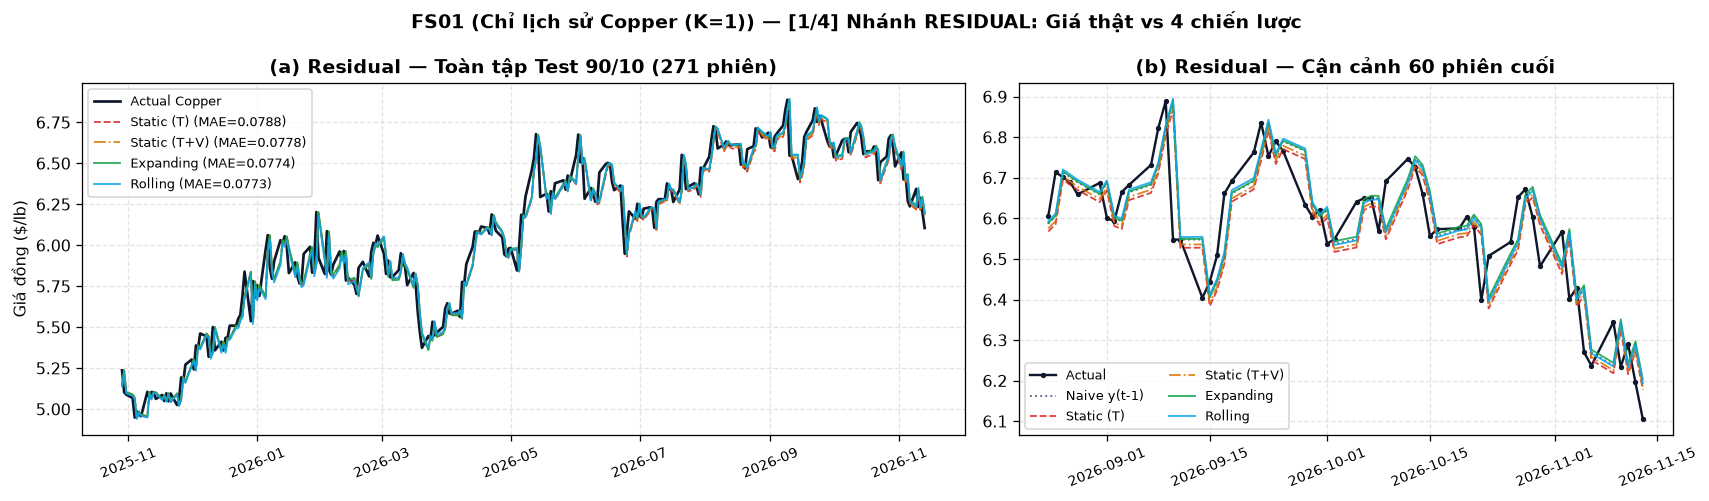

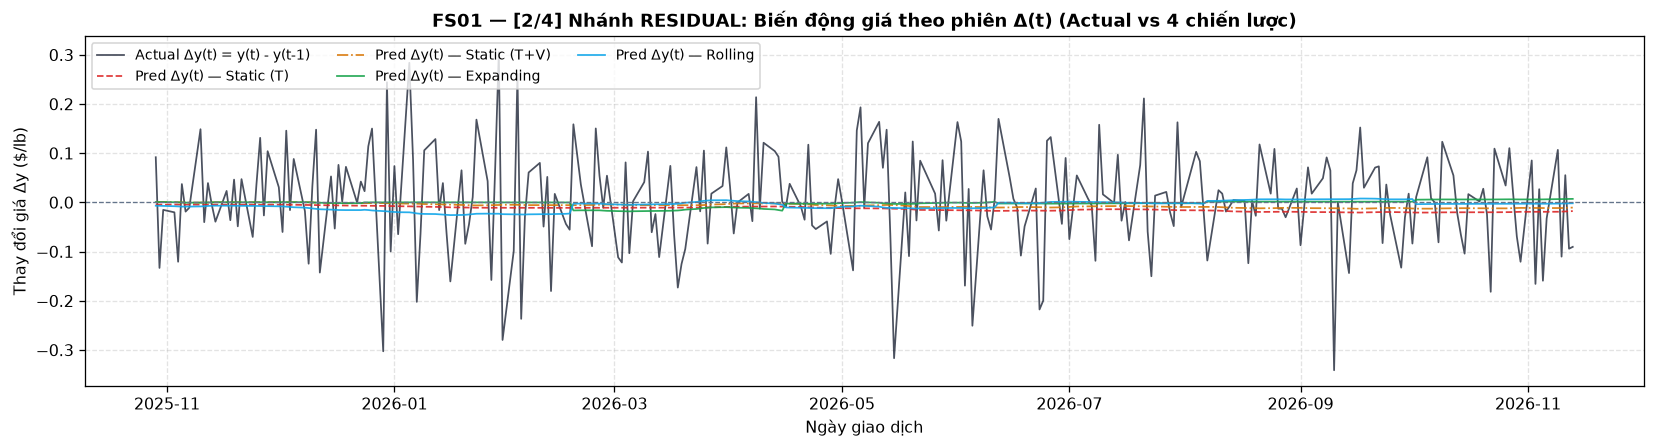

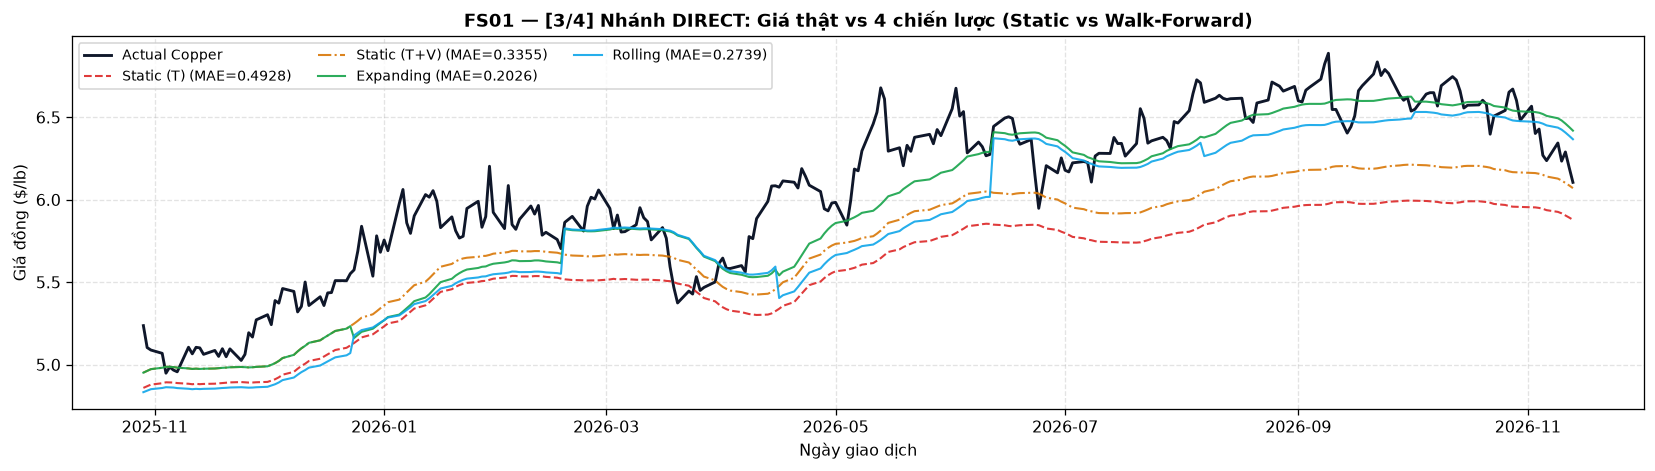

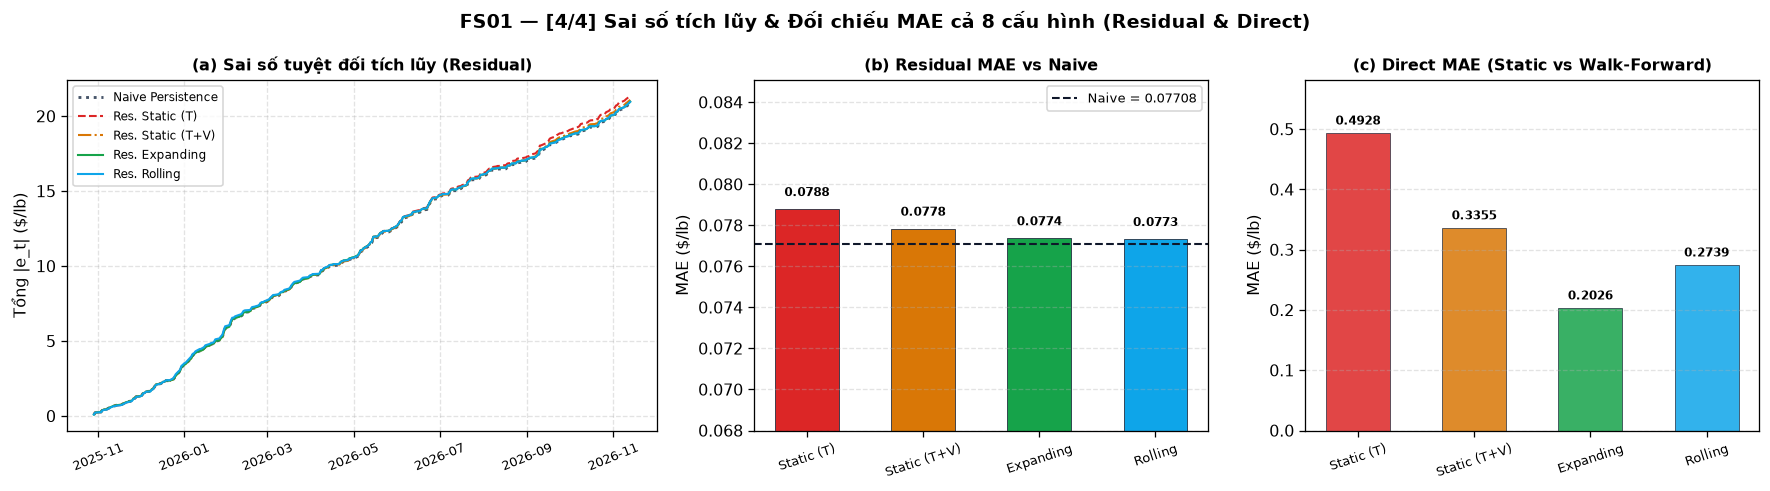

In [12]:
# === BIỂU ĐỒ ĐẦY ĐỦ 4 BIỂU ĐỒ CHO FS01 (FS01_CU) ===
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE_DIR = OUT_DIR if ("OUT_DIR" in globals() and (Path(OUT_DIR) / "phase2_main_test_results.csv").exists()) else Path("result")
MET_DIR = (BASE_DIR / "metrics") if (BASE_DIR / "metrics").exists() else BASE_DIR
PRED_DIR = (BASE_DIR / "predictions") if (BASE_DIR / "predictions").exists() else BASE_DIR
FIG_ROOT = (BASE_DIR / "figures") if (BASE_DIR / "figures").exists() else BASE_DIR
FS_OUT = FIG_ROOT / "per_feature_set" / "FS01"
FS_OUT.mkdir(parents=True, exist_ok=True)

_main = pd.read_csv(MET_DIR / "phase2_main_test_results.csv")
_naive_mae = float(_main[_main["strategy"] == "naive_persistence"].iloc[0]["MAE"])

_strats = [
    ("static_train_only", "Static (T)", "#DC2626", "--"),
    ("static_train_val",  "Static (T+V)", "#D97706", "-."),
    ("expanding_window",  "Expanding", "#16A34A", "-"),
    ("rolling_window",    "Rolling", "#0EA5E9", "-"),
]

_res_dfs = {s: pd.read_csv(PRED_DIR / f"pred_RESIDUAL__FS01_CU__{s}.csv") for s, _, _, _ in _strats}
_dir_dfs = {s: pd.read_csv(PRED_DIR / f"pred_FS01_CU__{s}.csv") for s, _, _, _ in _strats}
_dates = pd.to_datetime(_res_dfs["expanding_window"]["Date"])
_actual = _res_dfs["expanding_window"]["actual"].to_numpy()
_prev = _res_dfs["expanding_window"]["prev_actual"].to_numpy()

# 1) RESIDUAL Copper(t): Toàn tập Test + Cận cảnh 60 phiên cuối (4 chiến lược)
fig, axes = plt.subplots(1, 2, figsize=(15.0, 4.4), gridspec_kw={"width_ratios": [1.35, 1.0]})
axes[0].plot(_dates, _actual, color="#0F172A", linewidth=1.7, label="Actual Copper")
for s, lbl, col, ls in _strats:
    mae_v = float(np.mean(np.abs(_res_dfs[s]["actual"] - _res_dfs[s]["predicted"])))
    axes[0].plot(_dates, _res_dfs[s]["predicted"], color=col, linestyle=ls, linewidth=1.15, alpha=0.88, label=f"{lbl} (MAE={mae_v:.4f})")
axes[0].set_title("(a) Residual — Toàn tập Test 90/10 (271 phiên)", fontweight="bold")
axes[0].set_ylabel("Giá đồng ($/lb)")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend(loc="upper left", fontsize=8.2)
axes[0].tick_params(axis="x", rotation=22, labelsize=8.5)

_sl = slice(-60, None)
axes[1].plot(_dates.iloc[_sl], _actual[_sl], color="#0F172A", marker="o", markersize=2.3, linewidth=1.5, label="Actual")
axes[1].plot(_dates.iloc[_sl], _prev[_sl], color="#64748B", linestyle=":", linewidth=1.2, label="Naive y(t-1)")
for s, lbl, col, ls in _strats:
    axes[1].plot(_dates.iloc[_sl], _res_dfs[s]["predicted"].iloc[_sl], color=col, linestyle=ls, linewidth=1.15, alpha=0.88, label=lbl)
axes[1].set_title("(b) Residual — Cận cảnh 60 phiên cuối", fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.35)
axes[1].legend(loc="lower left", fontsize=8.0, ncol=2)
axes[1].tick_params(axis="x", rotation=22, labelsize=8.5)
fig.suptitle("FS01 (Chỉ lịch sử Copper (K=1)) — [1/4] Nhánh RESIDUAL: Giá thật vs 4 chiến lược", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(FS_OUT / "1_residual_price_4strategies.png", dpi=135)
plt.show()

# 2) RESIDUAL Copper Δ(t): Actual change vs Predicted change (4 chiến lược)
fig, ax = plt.subplots(figsize=(14.5, 4.0))
_act_delta = _actual - _prev
ax.plot(_dates, _act_delta, color="#0F172A", linewidth=1.1, alpha=0.75, label="Actual Δy(t) = y(t) - y(t-1)")
for s, lbl, col, ls in _strats:
    _pred_delta = _res_dfs[s]["predicted"].to_numpy() - _prev
    ax.plot(_dates, _pred_delta, color=col, linestyle=ls, linewidth=1.1, alpha=0.9, label=f"Pred Δy(t) — {lbl}")
ax.axhline(0, color="#64748B", linestyle="--", linewidth=0.8)
ax.set_title("FS01 — [2/4] Nhánh RESIDUAL: Biến động giá theo phiên Δ(t) (Actual vs 4 chiến lược)", fontsize=11.5, fontweight="bold")
ax.set_ylabel("Thay đổi giá Δy ($/lb)")
ax.set_xlabel("Ngày giao dịch")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
plt.tight_layout()
fig.savefig(FS_OUT / "2_residual_delta_4strategies.png", dpi=135)
plt.show()

# 3) DIRECT Copper(t): Giá thật vs 4 chiến lược (Static vs Walk-Forward)
fig, ax = plt.subplots(figsize=(14.5, 4.2))
ax.plot(_dates, _actual, color="#0F172A", linewidth=1.8, label="Actual Copper")
for s, lbl, col, ls in _strats:
    mae_v = float(np.mean(np.abs(_dir_dfs[s]["actual"] - _dir_dfs[s]["predicted"])))
    ax.plot(_dates, _dir_dfs[s]["predicted"], color=col, linestyle=ls, linewidth=1.3, alpha=0.9, label=f"{lbl} (MAE={mae_v:.4f})")
ax.set_title("FS01 — [3/4] Nhánh DIRECT: Giá thật vs 4 chiến lược (Static vs Walk-Forward)", fontsize=11.5, fontweight="bold")
ax.set_ylabel("Giá đồng ($/lb)")
ax.set_xlabel("Ngày giao dịch")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
plt.tight_layout()
fig.savefig(FS_OUT / "3_direct_price_4strategies.png", dpi=135)
plt.show()

# 4) Sai số tích lũy (Cumulative Abs Error) + Bảng cột MAE & DA% cho cả 8 cấu hình
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3), gridspec_kw={"width_ratios": [1.3, 1.0, 1.0]})
_cum_naive = np.cumsum(np.abs(_actual - _prev))
axes[0].plot(_dates, _cum_naive, color="#475569", linestyle=":", linewidth=1.8, label="Naive Persistence")
for s, lbl, col, ls in _strats:
    _cum = np.cumsum(np.abs(_res_dfs[s]["actual"].to_numpy() - _res_dfs[s]["predicted"].to_numpy()))
    axes[0].plot(_dates, _cum, color=col, linestyle=ls, linewidth=1.3, label=f"Res. {lbl}")
axes[0].set_title("(a) Sai số tuyệt đối tích lũy (Residual)", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Tổng |e_t| ($/lb)")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend(loc="upper left", fontsize=7.8)
axes[0].tick_params(axis="x", rotation=22, labelsize=8)

_sub_r = _main[(_main["feature_set"] == "FS01_CU") & (_main["target_mode"] == "residual")].set_index("strategy")
_sub_d = _main[(_main["feature_set"] == "FS01_CU") & (_main["target_mode"] == "direct")].set_index("strategy")
_x = np.arange(len(_strats))
_lbls = [lbl for _, lbl, _, _ in _strats]
_cols = [col for _, _, col, _ in _strats]

_rmae = [float(_sub_r.loc[s, "MAE"]) for s, _, _, _ in _strats]
_bars1 = axes[1].bar(_lbls, _rmae, color=_cols, width=0.55, edgecolor="#1E293B", linewidth=0.5)
axes[1].axhline(_naive_mae, color="#0F172A", linestyle="--", linewidth=1.3, label=f"Naive = {_naive_mae:.5f}")
axes[1].set_ylim(0.068, max(max(_rmae), _naive_mae) * 1.08)
axes[1].set_title("(b) Residual MAE vs Naive", fontsize=10, fontweight="bold")
axes[1].set_ylabel("MAE ($/lb)")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
axes[1].legend(loc="upper right", fontsize=8)
axes[1].tick_params(axis="x", rotation=18, labelsize=8)
for b in _bars1:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.0005, f"{b.get_height():.4f}", ha="center", va="bottom", fontsize=7.8, fontweight="bold")

_dmae = [float(_sub_d.loc[s, "MAE"]) for s, _, _, _ in _strats]
_bars2 = axes[2].bar(_lbls, _dmae, color=_cols, width=0.55, edgecolor="#1E293B", linewidth=0.5, alpha=0.85)
axes[2].set_ylim(0, max(_dmae) * 1.18)
axes[2].set_title("(c) Direct MAE (Static vs Walk-Forward)", fontsize=10, fontweight="bold")
axes[2].set_ylabel("MAE ($/lb)")
axes[2].grid(axis="y", linestyle="--", alpha=0.35)
axes[2].tick_params(axis="x", rotation=18, labelsize=8)
for b in _bars2:
    axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + max(_dmae)*0.02, f"{b.get_height():.4f}", ha="center", va="bottom", fontsize=7.8, fontweight="bold")

fig.suptitle("FS01 — [4/4] Sai số tích lũy & Đối chiếu MAE cả 8 cấu hình (Residual & Direct)", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(FS_OUT / "4_error_and_mae_summary.png", dpi=135)
plt.show()

### 6.2. FS02 — Paper3 + Copper: Copper, WTI, Gold, Silver (K=4) (`FEATURES_4`)

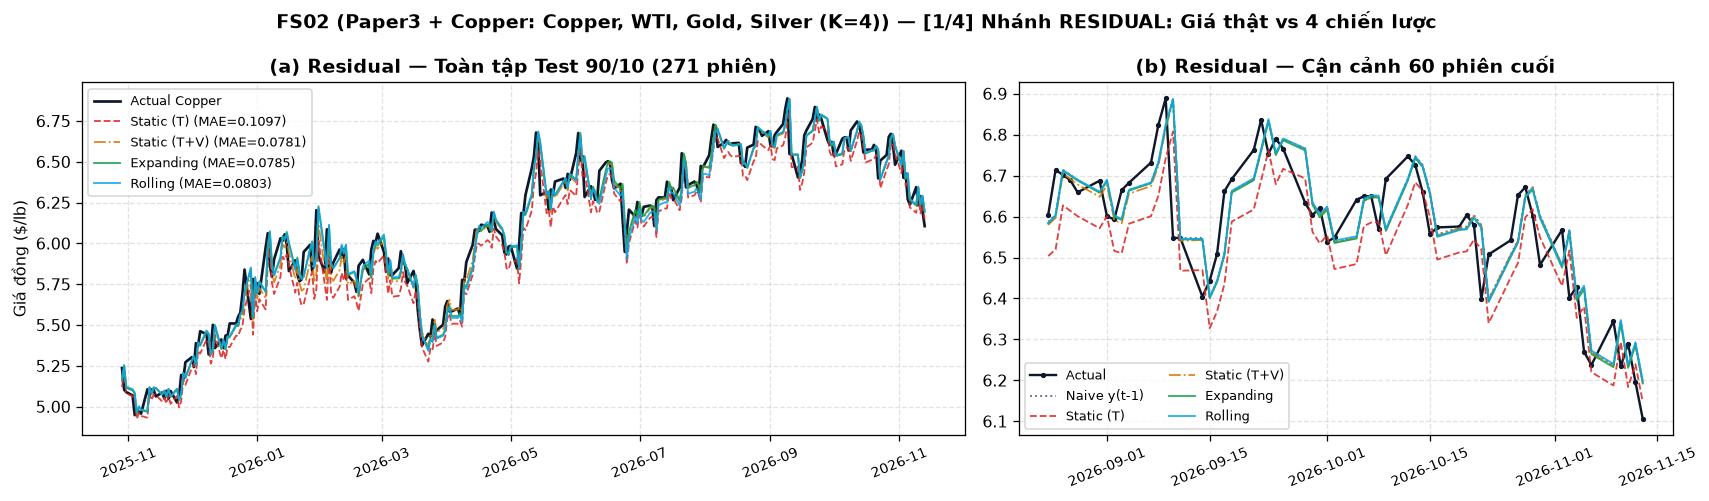

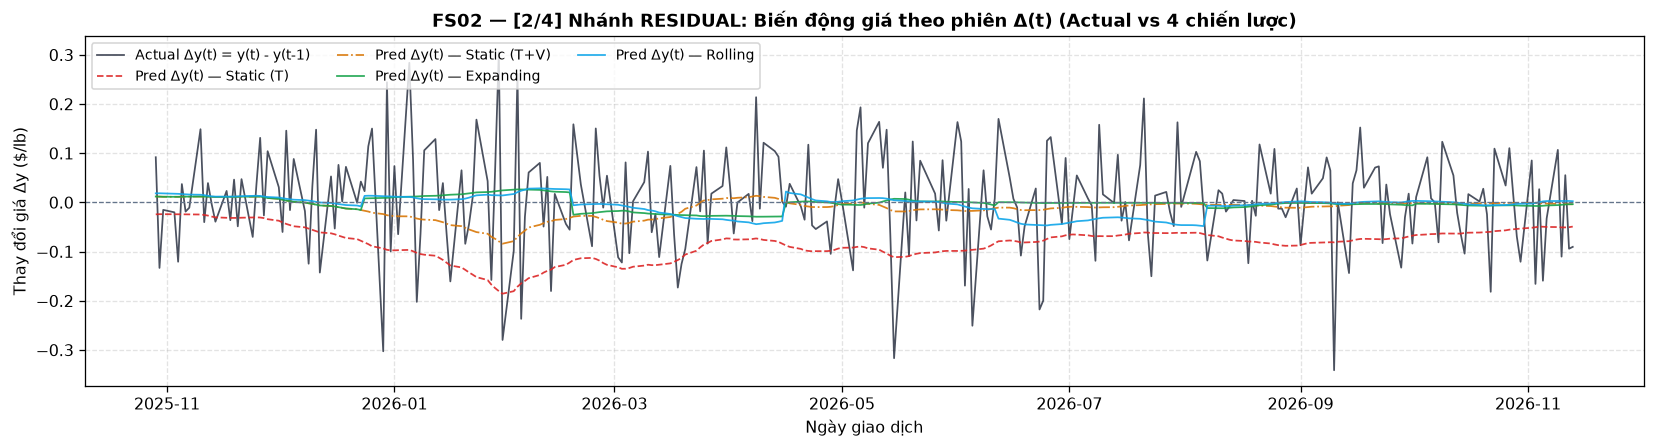

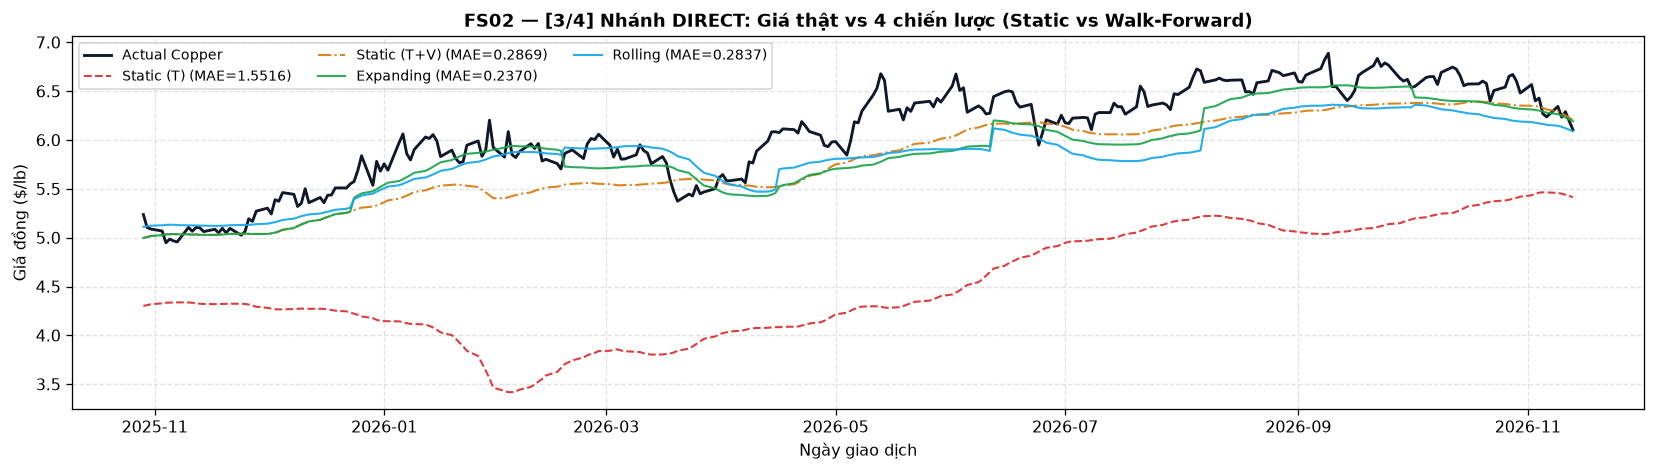

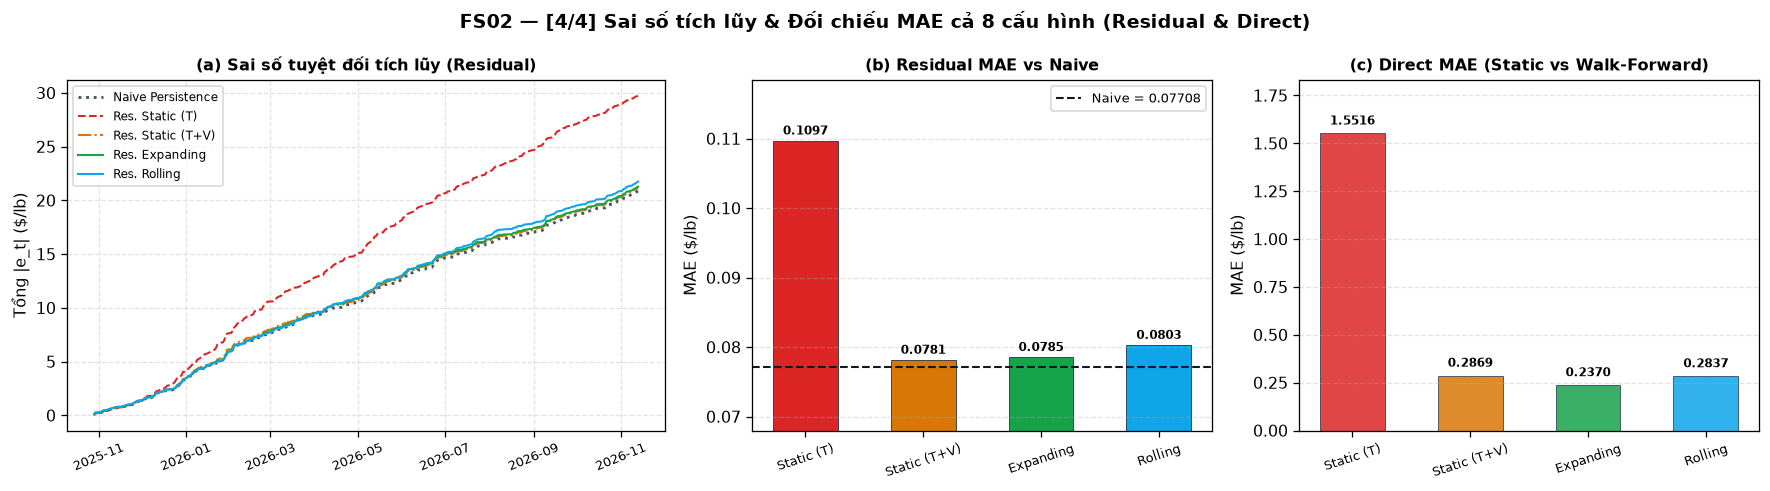

In [13]:
# === BIỂU ĐỒ ĐẦY ĐỦ 4 BIỂU ĐỒ CHO FS02 (FEATURES_4) ===
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE_DIR = OUT_DIR if ("OUT_DIR" in globals() and (Path(OUT_DIR) / "phase2_main_test_results.csv").exists()) else Path("result")
MET_DIR = (BASE_DIR / "metrics") if (BASE_DIR / "metrics").exists() else BASE_DIR
PRED_DIR = (BASE_DIR / "predictions") if (BASE_DIR / "predictions").exists() else BASE_DIR
FIG_ROOT = (BASE_DIR / "figures") if (BASE_DIR / "figures").exists() else BASE_DIR
FS_OUT = FIG_ROOT / "per_feature_set" / "FS02"
FS_OUT.mkdir(parents=True, exist_ok=True)

_main = pd.read_csv(MET_DIR / "phase2_main_test_results.csv")
_naive_mae = float(_main[_main["strategy"] == "naive_persistence"].iloc[0]["MAE"])

_strats = [
    ("static_train_only", "Static (T)", "#DC2626", "--"),
    ("static_train_val",  "Static (T+V)", "#D97706", "-."),
    ("expanding_window",  "Expanding", "#16A34A", "-"),
    ("rolling_window",    "Rolling", "#0EA5E9", "-"),
]

_res_dfs = {s: pd.read_csv(PRED_DIR / f"pred_RESIDUAL__FEATURES_4__{s}.csv") for s, _, _, _ in _strats}
_dir_dfs = {s: pd.read_csv(PRED_DIR / f"pred_FEATURES_4__{s}.csv") for s, _, _, _ in _strats}
_dates = pd.to_datetime(_res_dfs["expanding_window"]["Date"])
_actual = _res_dfs["expanding_window"]["actual"].to_numpy()
_prev = _res_dfs["expanding_window"]["prev_actual"].to_numpy()

# 1) RESIDUAL Copper(t): Toàn tập Test + Cận cảnh 60 phiên cuối (4 chiến lược)
fig, axes = plt.subplots(1, 2, figsize=(15.0, 4.4), gridspec_kw={"width_ratios": [1.35, 1.0]})
axes[0].plot(_dates, _actual, color="#0F172A", linewidth=1.7, label="Actual Copper")
for s, lbl, col, ls in _strats:
    mae_v = float(np.mean(np.abs(_res_dfs[s]["actual"] - _res_dfs[s]["predicted"])))
    axes[0].plot(_dates, _res_dfs[s]["predicted"], color=col, linestyle=ls, linewidth=1.15, alpha=0.88, label=f"{lbl} (MAE={mae_v:.4f})")
axes[0].set_title("(a) Residual — Toàn tập Test 90/10 (271 phiên)", fontweight="bold")
axes[0].set_ylabel("Giá đồng ($/lb)")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend(loc="upper left", fontsize=8.2)
axes[0].tick_params(axis="x", rotation=22, labelsize=8.5)

_sl = slice(-60, None)
axes[1].plot(_dates.iloc[_sl], _actual[_sl], color="#0F172A", marker="o", markersize=2.3, linewidth=1.5, label="Actual")
axes[1].plot(_dates.iloc[_sl], _prev[_sl], color="#64748B", linestyle=":", linewidth=1.2, label="Naive y(t-1)")
for s, lbl, col, ls in _strats:
    axes[1].plot(_dates.iloc[_sl], _res_dfs[s]["predicted"].iloc[_sl], color=col, linestyle=ls, linewidth=1.15, alpha=0.88, label=lbl)
axes[1].set_title("(b) Residual — Cận cảnh 60 phiên cuối", fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.35)
axes[1].legend(loc="lower left", fontsize=8.0, ncol=2)
axes[1].tick_params(axis="x", rotation=22, labelsize=8.5)
fig.suptitle("FS02 (Paper3 + Copper: Copper, WTI, Gold, Silver (K=4)) — [1/4] Nhánh RESIDUAL: Giá thật vs 4 chiến lược", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(FS_OUT / "1_residual_price_4strategies.png", dpi=135)
plt.show()

# 2) RESIDUAL Copper Δ(t): Actual change vs Predicted change (4 chiến lược)
fig, ax = plt.subplots(figsize=(14.5, 4.0))
_act_delta = _actual - _prev
ax.plot(_dates, _act_delta, color="#0F172A", linewidth=1.1, alpha=0.75, label="Actual Δy(t) = y(t) - y(t-1)")
for s, lbl, col, ls in _strats:
    _pred_delta = _res_dfs[s]["predicted"].to_numpy() - _prev
    ax.plot(_dates, _pred_delta, color=col, linestyle=ls, linewidth=1.1, alpha=0.9, label=f"Pred Δy(t) — {lbl}")
ax.axhline(0, color="#64748B", linestyle="--", linewidth=0.8)
ax.set_title("FS02 — [2/4] Nhánh RESIDUAL: Biến động giá theo phiên Δ(t) (Actual vs 4 chiến lược)", fontsize=11.5, fontweight="bold")
ax.set_ylabel("Thay đổi giá Δy ($/lb)")
ax.set_xlabel("Ngày giao dịch")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
plt.tight_layout()
fig.savefig(FS_OUT / "2_residual_delta_4strategies.png", dpi=135)
plt.show()

# 3) DIRECT Copper(t): Giá thật vs 4 chiến lược (Static vs Walk-Forward)
fig, ax = plt.subplots(figsize=(14.5, 4.2))
ax.plot(_dates, _actual, color="#0F172A", linewidth=1.8, label="Actual Copper")
for s, lbl, col, ls in _strats:
    mae_v = float(np.mean(np.abs(_dir_dfs[s]["actual"] - _dir_dfs[s]["predicted"])))
    ax.plot(_dates, _dir_dfs[s]["predicted"], color=col, linestyle=ls, linewidth=1.3, alpha=0.9, label=f"{lbl} (MAE={mae_v:.4f})")
ax.set_title("FS02 — [3/4] Nhánh DIRECT: Giá thật vs 4 chiến lược (Static vs Walk-Forward)", fontsize=11.5, fontweight="bold")
ax.set_ylabel("Giá đồng ($/lb)")
ax.set_xlabel("Ngày giao dịch")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
plt.tight_layout()
fig.savefig(FS_OUT / "3_direct_price_4strategies.png", dpi=135)
plt.show()

# 4) Sai số tích lũy (Cumulative Abs Error) + Bảng cột MAE & DA% cho cả 8 cấu hình
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3), gridspec_kw={"width_ratios": [1.3, 1.0, 1.0]})
_cum_naive = np.cumsum(np.abs(_actual - _prev))
axes[0].plot(_dates, _cum_naive, color="#475569", linestyle=":", linewidth=1.8, label="Naive Persistence")
for s, lbl, col, ls in _strats:
    _cum = np.cumsum(np.abs(_res_dfs[s]["actual"].to_numpy() - _res_dfs[s]["predicted"].to_numpy()))
    axes[0].plot(_dates, _cum, color=col, linestyle=ls, linewidth=1.3, label=f"Res. {lbl}")
axes[0].set_title("(a) Sai số tuyệt đối tích lũy (Residual)", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Tổng |e_t| ($/lb)")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend(loc="upper left", fontsize=7.8)
axes[0].tick_params(axis="x", rotation=22, labelsize=8)

_sub_r = _main[(_main["feature_set"] == "FEATURES_4") & (_main["target_mode"] == "residual")].set_index("strategy")
_sub_d = _main[(_main["feature_set"] == "FEATURES_4") & (_main["target_mode"] == "direct")].set_index("strategy")
_x = np.arange(len(_strats))
_lbls = [lbl for _, lbl, _, _ in _strats]
_cols = [col for _, _, col, _ in _strats]

_rmae = [float(_sub_r.loc[s, "MAE"]) for s, _, _, _ in _strats]
_bars1 = axes[1].bar(_lbls, _rmae, color=_cols, width=0.55, edgecolor="#1E293B", linewidth=0.5)
axes[1].axhline(_naive_mae, color="#0F172A", linestyle="--", linewidth=1.3, label=f"Naive = {_naive_mae:.5f}")
axes[1].set_ylim(0.068, max(max(_rmae), _naive_mae) * 1.08)
axes[1].set_title("(b) Residual MAE vs Naive", fontsize=10, fontweight="bold")
axes[1].set_ylabel("MAE ($/lb)")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
axes[1].legend(loc="upper right", fontsize=8)
axes[1].tick_params(axis="x", rotation=18, labelsize=8)
for b in _bars1:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.0005, f"{b.get_height():.4f}", ha="center", va="bottom", fontsize=7.8, fontweight="bold")

_dmae = [float(_sub_d.loc[s, "MAE"]) for s, _, _, _ in _strats]
_bars2 = axes[2].bar(_lbls, _dmae, color=_cols, width=0.55, edgecolor="#1E293B", linewidth=0.5, alpha=0.85)
axes[2].set_ylim(0, max(_dmae) * 1.18)
axes[2].set_title("(c) Direct MAE (Static vs Walk-Forward)", fontsize=10, fontweight="bold")
axes[2].set_ylabel("MAE ($/lb)")
axes[2].grid(axis="y", linestyle="--", alpha=0.35)
axes[2].tick_params(axis="x", rotation=18, labelsize=8)
for b in _bars2:
    axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + max(_dmae)*0.02, f"{b.get_height():.4f}", ha="center", va="bottom", fontsize=7.8, fontweight="bold")

fig.suptitle("FS02 — [4/4] Sai số tích lũy & Đối chiếu MAE cả 8 cấu hình (Residual & Direct)", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(FS_OUT / "4_error_and_mae_summary.png", dpi=135)
plt.show()

### 6.3. FS03 — Paper3 - Copper: WTI, Gold, Silver (K=3) (`FEATURES_3`)

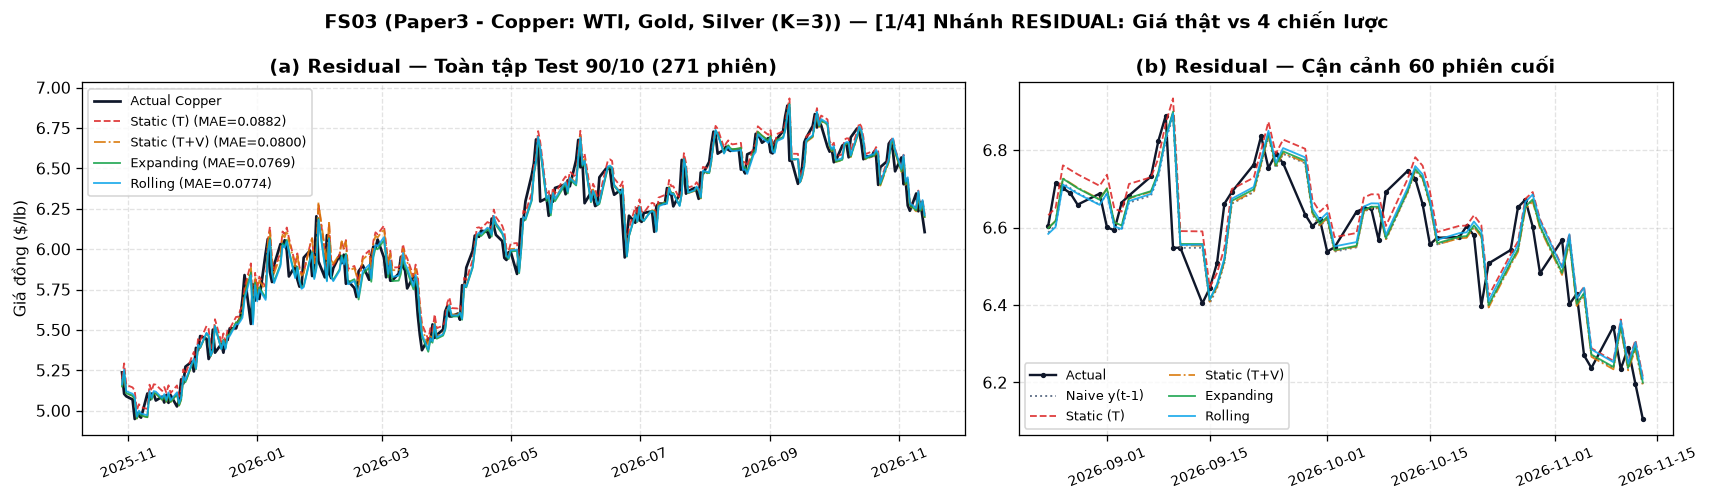

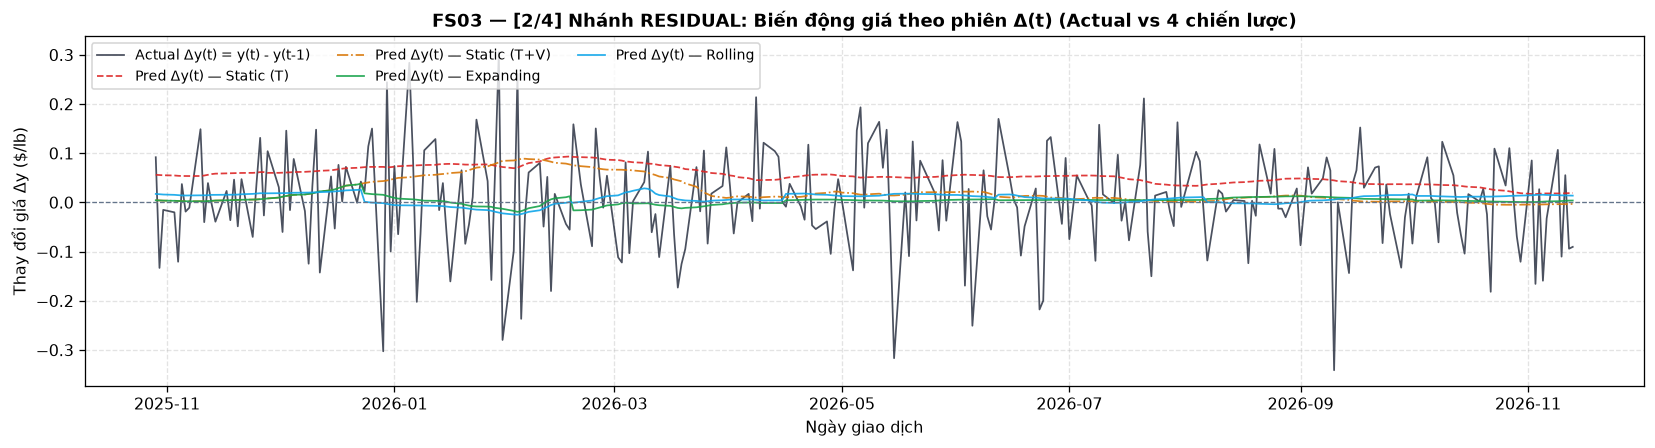

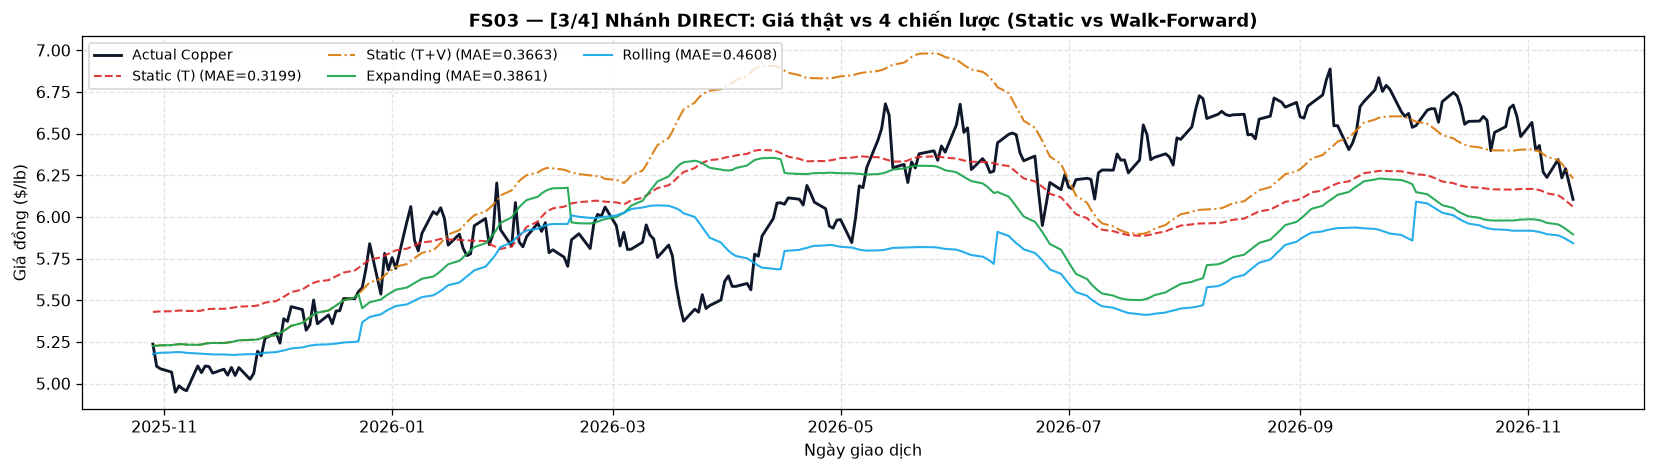

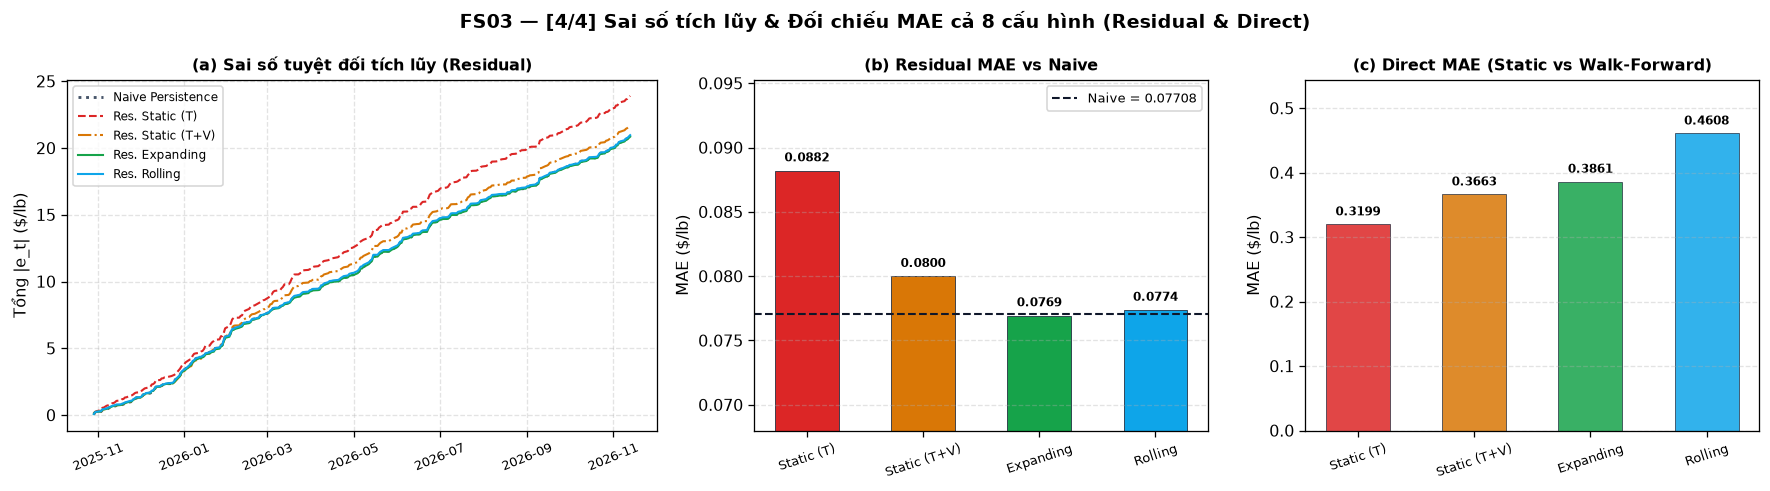

In [14]:
# === BIỂU ĐỒ ĐẦY ĐỦ 4 BIỂU ĐỒ CHO FS03 (FEATURES_3) ===
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE_DIR = OUT_DIR if ("OUT_DIR" in globals() and (Path(OUT_DIR) / "phase2_main_test_results.csv").exists()) else Path("result")
MET_DIR = (BASE_DIR / "metrics") if (BASE_DIR / "metrics").exists() else BASE_DIR
PRED_DIR = (BASE_DIR / "predictions") if (BASE_DIR / "predictions").exists() else BASE_DIR
FIG_ROOT = (BASE_DIR / "figures") if (BASE_DIR / "figures").exists() else BASE_DIR
FS_OUT = FIG_ROOT / "per_feature_set" / "FS03"
FS_OUT.mkdir(parents=True, exist_ok=True)

_main = pd.read_csv(MET_DIR / "phase2_main_test_results.csv")
_naive_mae = float(_main[_main["strategy"] == "naive_persistence"].iloc[0]["MAE"])

_strats = [
    ("static_train_only", "Static (T)", "#DC2626", "--"),
    ("static_train_val",  "Static (T+V)", "#D97706", "-."),
    ("expanding_window",  "Expanding", "#16A34A", "-"),
    ("rolling_window",    "Rolling", "#0EA5E9", "-"),
]

_res_dfs = {s: pd.read_csv(PRED_DIR / f"pred_RESIDUAL__FEATURES_3__{s}.csv") for s, _, _, _ in _strats}
_dir_dfs = {s: pd.read_csv(PRED_DIR / f"pred_FEATURES_3__{s}.csv") for s, _, _, _ in _strats}
_dates = pd.to_datetime(_res_dfs["expanding_window"]["Date"])
_actual = _res_dfs["expanding_window"]["actual"].to_numpy()
_prev = _res_dfs["expanding_window"]["prev_actual"].to_numpy()

# 1) RESIDUAL Copper(t): Toàn tập Test + Cận cảnh 60 phiên cuối (4 chiến lược)
fig, axes = plt.subplots(1, 2, figsize=(15.0, 4.4), gridspec_kw={"width_ratios": [1.35, 1.0]})
axes[0].plot(_dates, _actual, color="#0F172A", linewidth=1.7, label="Actual Copper")
for s, lbl, col, ls in _strats:
    mae_v = float(np.mean(np.abs(_res_dfs[s]["actual"] - _res_dfs[s]["predicted"])))
    axes[0].plot(_dates, _res_dfs[s]["predicted"], color=col, linestyle=ls, linewidth=1.15, alpha=0.88, label=f"{lbl} (MAE={mae_v:.4f})")
axes[0].set_title("(a) Residual — Toàn tập Test 90/10 (271 phiên)", fontweight="bold")
axes[0].set_ylabel("Giá đồng ($/lb)")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend(loc="upper left", fontsize=8.2)
axes[0].tick_params(axis="x", rotation=22, labelsize=8.5)

_sl = slice(-60, None)
axes[1].plot(_dates.iloc[_sl], _actual[_sl], color="#0F172A", marker="o", markersize=2.3, linewidth=1.5, label="Actual")
axes[1].plot(_dates.iloc[_sl], _prev[_sl], color="#64748B", linestyle=":", linewidth=1.2, label="Naive y(t-1)")
for s, lbl, col, ls in _strats:
    axes[1].plot(_dates.iloc[_sl], _res_dfs[s]["predicted"].iloc[_sl], color=col, linestyle=ls, linewidth=1.15, alpha=0.88, label=lbl)
axes[1].set_title("(b) Residual — Cận cảnh 60 phiên cuối", fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.35)
axes[1].legend(loc="lower left", fontsize=8.0, ncol=2)
axes[1].tick_params(axis="x", rotation=22, labelsize=8.5)
fig.suptitle("FS03 (Paper3 - Copper: WTI, Gold, Silver (K=3)) — [1/4] Nhánh RESIDUAL: Giá thật vs 4 chiến lược", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(FS_OUT / "1_residual_price_4strategies.png", dpi=135)
plt.show()

# 2) RESIDUAL Copper Δ(t): Actual change vs Predicted change (4 chiến lược)
fig, ax = plt.subplots(figsize=(14.5, 4.0))
_act_delta = _actual - _prev
ax.plot(_dates, _act_delta, color="#0F172A", linewidth=1.1, alpha=0.75, label="Actual Δy(t) = y(t) - y(t-1)")
for s, lbl, col, ls in _strats:
    _pred_delta = _res_dfs[s]["predicted"].to_numpy() - _prev
    ax.plot(_dates, _pred_delta, color=col, linestyle=ls, linewidth=1.1, alpha=0.9, label=f"Pred Δy(t) — {lbl}")
ax.axhline(0, color="#64748B", linestyle="--", linewidth=0.8)
ax.set_title("FS03 — [2/4] Nhánh RESIDUAL: Biến động giá theo phiên Δ(t) (Actual vs 4 chiến lược)", fontsize=11.5, fontweight="bold")
ax.set_ylabel("Thay đổi giá Δy ($/lb)")
ax.set_xlabel("Ngày giao dịch")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
plt.tight_layout()
fig.savefig(FS_OUT / "2_residual_delta_4strategies.png", dpi=135)
plt.show()

# 3) DIRECT Copper(t): Giá thật vs 4 chiến lược (Static vs Walk-Forward)
fig, ax = plt.subplots(figsize=(14.5, 4.2))
ax.plot(_dates, _actual, color="#0F172A", linewidth=1.8, label="Actual Copper")
for s, lbl, col, ls in _strats:
    mae_v = float(np.mean(np.abs(_dir_dfs[s]["actual"] - _dir_dfs[s]["predicted"])))
    ax.plot(_dates, _dir_dfs[s]["predicted"], color=col, linestyle=ls, linewidth=1.3, alpha=0.9, label=f"{lbl} (MAE={mae_v:.4f})")
ax.set_title("FS03 — [3/4] Nhánh DIRECT: Giá thật vs 4 chiến lược (Static vs Walk-Forward)", fontsize=11.5, fontweight="bold")
ax.set_ylabel("Giá đồng ($/lb)")
ax.set_xlabel("Ngày giao dịch")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
plt.tight_layout()
fig.savefig(FS_OUT / "3_direct_price_4strategies.png", dpi=135)
plt.show()

# 4) Sai số tích lũy (Cumulative Abs Error) + Bảng cột MAE & DA% cho cả 8 cấu hình
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3), gridspec_kw={"width_ratios": [1.3, 1.0, 1.0]})
_cum_naive = np.cumsum(np.abs(_actual - _prev))
axes[0].plot(_dates, _cum_naive, color="#475569", linestyle=":", linewidth=1.8, label="Naive Persistence")
for s, lbl, col, ls in _strats:
    _cum = np.cumsum(np.abs(_res_dfs[s]["actual"].to_numpy() - _res_dfs[s]["predicted"].to_numpy()))
    axes[0].plot(_dates, _cum, color=col, linestyle=ls, linewidth=1.3, label=f"Res. {lbl}")
axes[0].set_title("(a) Sai số tuyệt đối tích lũy (Residual)", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Tổng |e_t| ($/lb)")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend(loc="upper left", fontsize=7.8)
axes[0].tick_params(axis="x", rotation=22, labelsize=8)

_sub_r = _main[(_main["feature_set"] == "FEATURES_3") & (_main["target_mode"] == "residual")].set_index("strategy")
_sub_d = _main[(_main["feature_set"] == "FEATURES_3") & (_main["target_mode"] == "direct")].set_index("strategy")
_x = np.arange(len(_strats))
_lbls = [lbl for _, lbl, _, _ in _strats]
_cols = [col for _, _, col, _ in _strats]

_rmae = [float(_sub_r.loc[s, "MAE"]) for s, _, _, _ in _strats]
_bars1 = axes[1].bar(_lbls, _rmae, color=_cols, width=0.55, edgecolor="#1E293B", linewidth=0.5)
axes[1].axhline(_naive_mae, color="#0F172A", linestyle="--", linewidth=1.3, label=f"Naive = {_naive_mae:.5f}")
axes[1].set_ylim(0.068, max(max(_rmae), _naive_mae) * 1.08)
axes[1].set_title("(b) Residual MAE vs Naive", fontsize=10, fontweight="bold")
axes[1].set_ylabel("MAE ($/lb)")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
axes[1].legend(loc="upper right", fontsize=8)
axes[1].tick_params(axis="x", rotation=18, labelsize=8)
for b in _bars1:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.0005, f"{b.get_height():.4f}", ha="center", va="bottom", fontsize=7.8, fontweight="bold")

_dmae = [float(_sub_d.loc[s, "MAE"]) for s, _, _, _ in _strats]
_bars2 = axes[2].bar(_lbls, _dmae, color=_cols, width=0.55, edgecolor="#1E293B", linewidth=0.5, alpha=0.85)
axes[2].set_ylim(0, max(_dmae) * 1.18)
axes[2].set_title("(c) Direct MAE (Static vs Walk-Forward)", fontsize=10, fontweight="bold")
axes[2].set_ylabel("MAE ($/lb)")
axes[2].grid(axis="y", linestyle="--", alpha=0.35)
axes[2].tick_params(axis="x", rotation=18, labelsize=8)
for b in _bars2:
    axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + max(_dmae)*0.02, f"{b.get_height():.4f}", ha="center", va="bottom", fontsize=7.8, fontweight="bold")

fig.suptitle("FS03 — [4/4] Sai số tích lũy & Đối chiếu MAE cả 8 cấu hình (Residual & Direct)", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(FS_OUT / "4_error_and_mae_summary.png", dpi=135)
plt.show()

### 6.4. FS04 — 5 Kim loại: Copper, Aluminium, Tin, Silver, Gold (K=5) (`FS04_METALS_CU`)

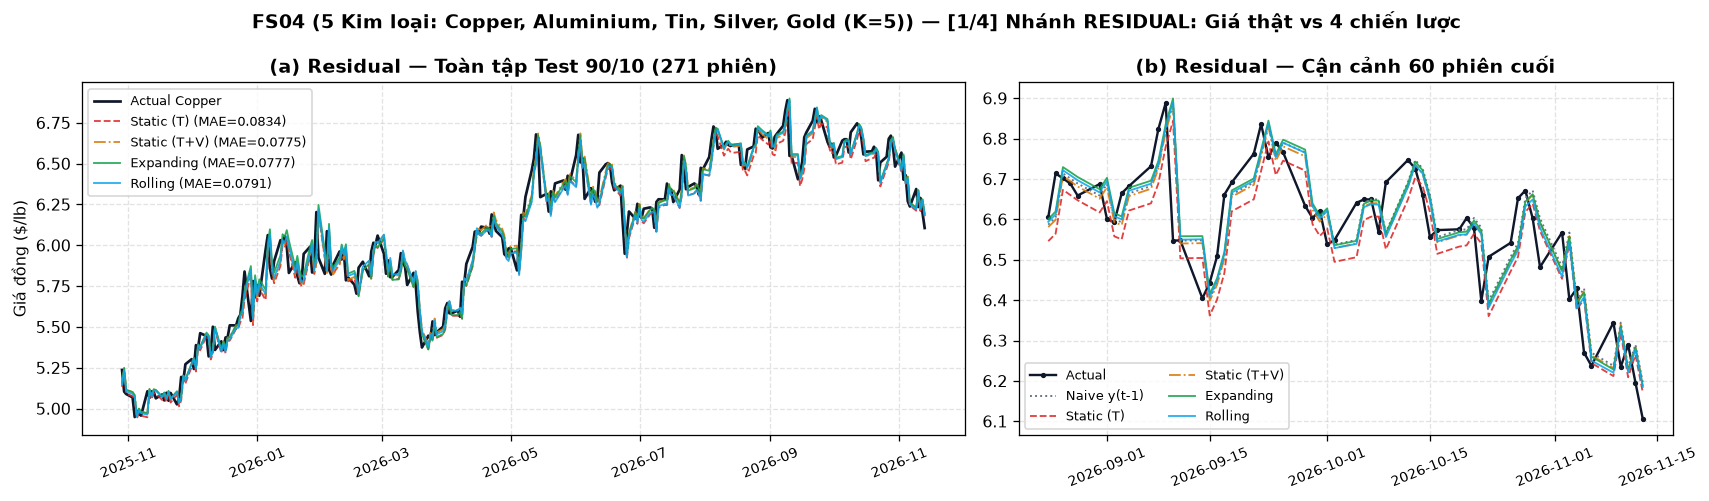

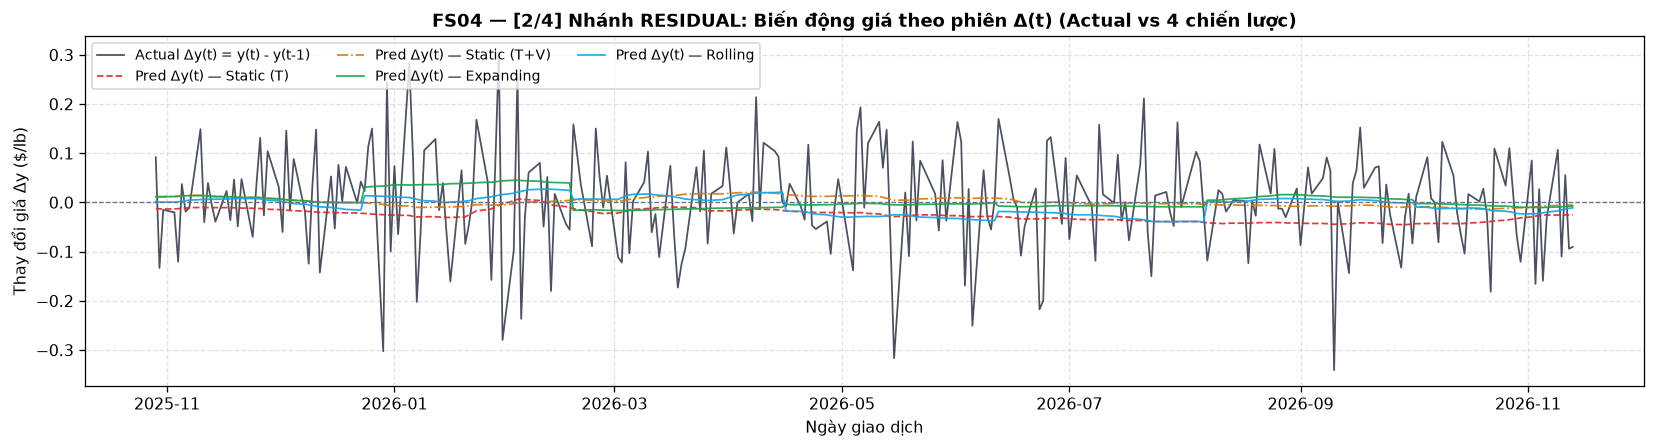

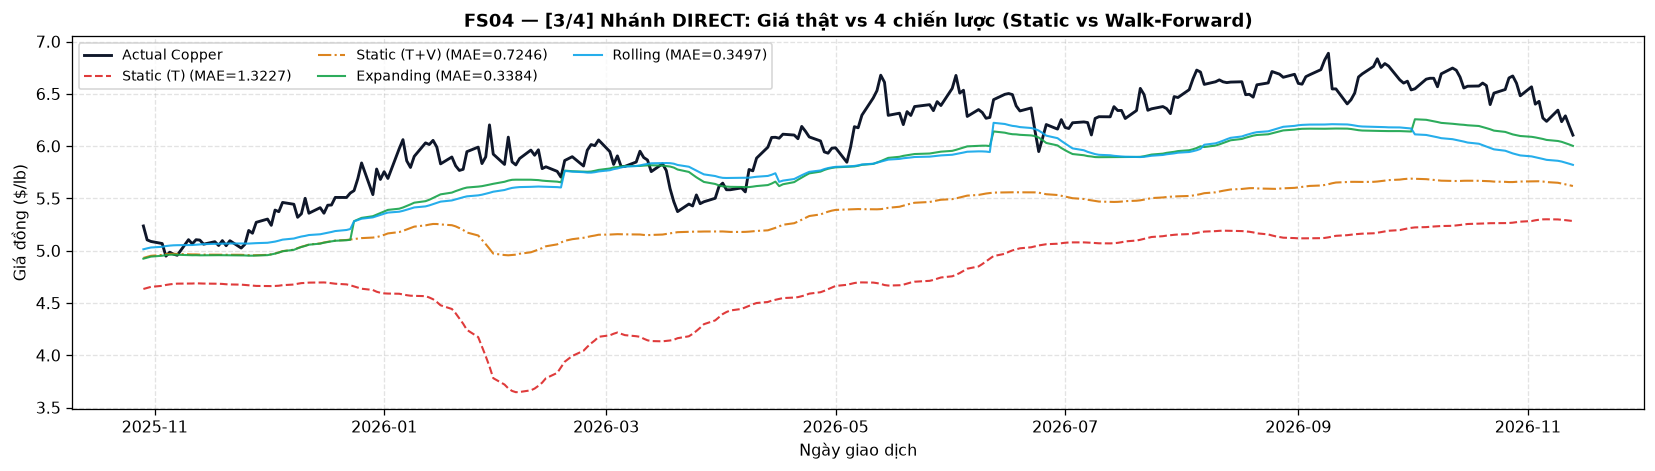

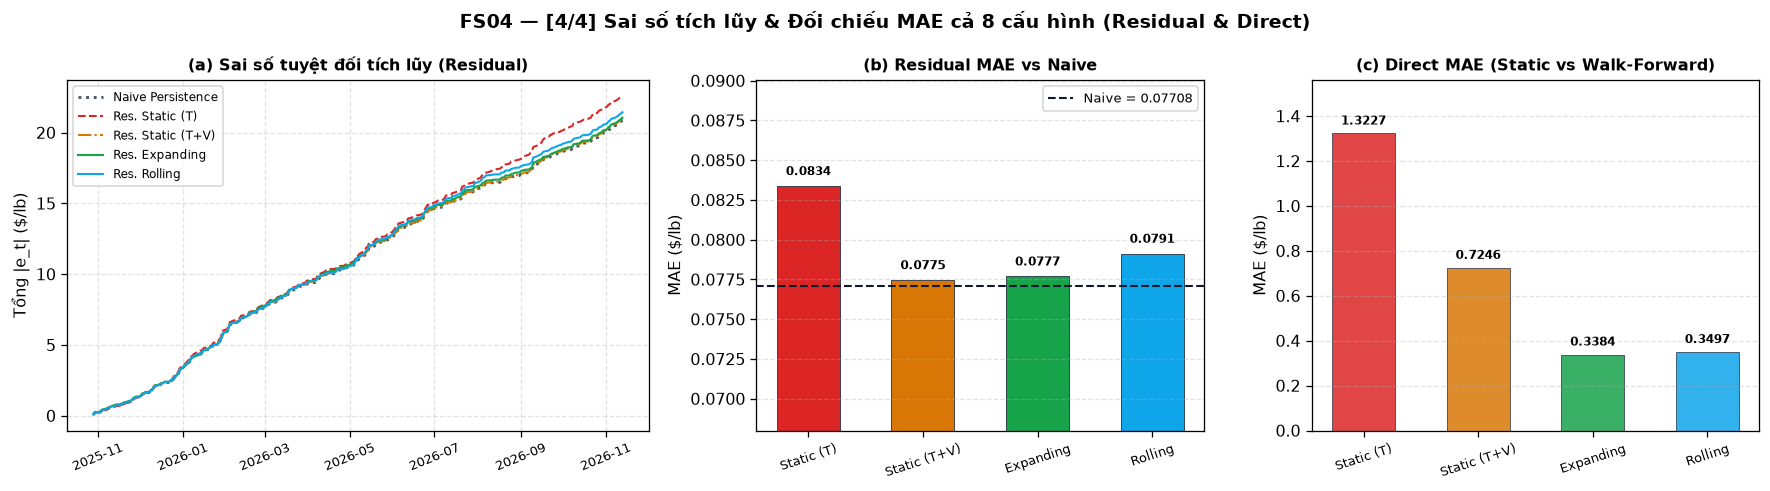

In [15]:
# === BIỂU ĐỒ ĐẦY ĐỦ 4 BIỂU ĐỒ CHO FS04 (FS04_METALS_CU) ===
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE_DIR = OUT_DIR if ("OUT_DIR" in globals() and (Path(OUT_DIR) / "phase2_main_test_results.csv").exists()) else Path("result")
MET_DIR = (BASE_DIR / "metrics") if (BASE_DIR / "metrics").exists() else BASE_DIR
PRED_DIR = (BASE_DIR / "predictions") if (BASE_DIR / "predictions").exists() else BASE_DIR
FIG_ROOT = (BASE_DIR / "figures") if (BASE_DIR / "figures").exists() else BASE_DIR
FS_OUT = FIG_ROOT / "per_feature_set" / "FS04"
FS_OUT.mkdir(parents=True, exist_ok=True)

_main = pd.read_csv(MET_DIR / "phase2_main_test_results.csv")
_naive_mae = float(_main[_main["strategy"] == "naive_persistence"].iloc[0]["MAE"])

_strats = [
    ("static_train_only", "Static (T)", "#DC2626", "--"),
    ("static_train_val",  "Static (T+V)", "#D97706", "-."),
    ("expanding_window",  "Expanding", "#16A34A", "-"),
    ("rolling_window",    "Rolling", "#0EA5E9", "-"),
]

_res_dfs = {s: pd.read_csv(PRED_DIR / f"pred_RESIDUAL__FS04_METALS_CU__{s}.csv") for s, _, _, _ in _strats}
_dir_dfs = {s: pd.read_csv(PRED_DIR / f"pred_FS04_METALS_CU__{s}.csv") for s, _, _, _ in _strats}
_dates = pd.to_datetime(_res_dfs["expanding_window"]["Date"])
_actual = _res_dfs["expanding_window"]["actual"].to_numpy()
_prev = _res_dfs["expanding_window"]["prev_actual"].to_numpy()

# 1) RESIDUAL Copper(t): Toàn tập Test + Cận cảnh 60 phiên cuối (4 chiến lược)
fig, axes = plt.subplots(1, 2, figsize=(15.0, 4.4), gridspec_kw={"width_ratios": [1.35, 1.0]})
axes[0].plot(_dates, _actual, color="#0F172A", linewidth=1.7, label="Actual Copper")
for s, lbl, col, ls in _strats:
    mae_v = float(np.mean(np.abs(_res_dfs[s]["actual"] - _res_dfs[s]["predicted"])))
    axes[0].plot(_dates, _res_dfs[s]["predicted"], color=col, linestyle=ls, linewidth=1.15, alpha=0.88, label=f"{lbl} (MAE={mae_v:.4f})")
axes[0].set_title("(a) Residual — Toàn tập Test 90/10 (271 phiên)", fontweight="bold")
axes[0].set_ylabel("Giá đồng ($/lb)")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend(loc="upper left", fontsize=8.2)
axes[0].tick_params(axis="x", rotation=22, labelsize=8.5)

_sl = slice(-60, None)
axes[1].plot(_dates.iloc[_sl], _actual[_sl], color="#0F172A", marker="o", markersize=2.3, linewidth=1.5, label="Actual")
axes[1].plot(_dates.iloc[_sl], _prev[_sl], color="#64748B", linestyle=":", linewidth=1.2, label="Naive y(t-1)")
for s, lbl, col, ls in _strats:
    axes[1].plot(_dates.iloc[_sl], _res_dfs[s]["predicted"].iloc[_sl], color=col, linestyle=ls, linewidth=1.15, alpha=0.88, label=lbl)
axes[1].set_title("(b) Residual — Cận cảnh 60 phiên cuối", fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.35)
axes[1].legend(loc="lower left", fontsize=8.0, ncol=2)
axes[1].tick_params(axis="x", rotation=22, labelsize=8.5)
fig.suptitle("FS04 (5 Kim loại: Copper, Aluminium, Tin, Silver, Gold (K=5)) — [1/4] Nhánh RESIDUAL: Giá thật vs 4 chiến lược", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(FS_OUT / "1_residual_price_4strategies.png", dpi=135)
plt.show()

# 2) RESIDUAL Copper Δ(t): Actual change vs Predicted change (4 chiến lược)
fig, ax = plt.subplots(figsize=(14.5, 4.0))
_act_delta = _actual - _prev
ax.plot(_dates, _act_delta, color="#0F172A", linewidth=1.1, alpha=0.75, label="Actual Δy(t) = y(t) - y(t-1)")
for s, lbl, col, ls in _strats:
    _pred_delta = _res_dfs[s]["predicted"].to_numpy() - _prev
    ax.plot(_dates, _pred_delta, color=col, linestyle=ls, linewidth=1.1, alpha=0.9, label=f"Pred Δy(t) — {lbl}")
ax.axhline(0, color="#64748B", linestyle="--", linewidth=0.8)
ax.set_title("FS04 — [2/4] Nhánh RESIDUAL: Biến động giá theo phiên Δ(t) (Actual vs 4 chiến lược)", fontsize=11.5, fontweight="bold")
ax.set_ylabel("Thay đổi giá Δy ($/lb)")
ax.set_xlabel("Ngày giao dịch")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
plt.tight_layout()
fig.savefig(FS_OUT / "2_residual_delta_4strategies.png", dpi=135)
plt.show()

# 3) DIRECT Copper(t): Giá thật vs 4 chiến lược (Static vs Walk-Forward)
fig, ax = plt.subplots(figsize=(14.5, 4.2))
ax.plot(_dates, _actual, color="#0F172A", linewidth=1.8, label="Actual Copper")
for s, lbl, col, ls in _strats:
    mae_v = float(np.mean(np.abs(_dir_dfs[s]["actual"] - _dir_dfs[s]["predicted"])))
    ax.plot(_dates, _dir_dfs[s]["predicted"], color=col, linestyle=ls, linewidth=1.3, alpha=0.9, label=f"{lbl} (MAE={mae_v:.4f})")
ax.set_title("FS04 — [3/4] Nhánh DIRECT: Giá thật vs 4 chiến lược (Static vs Walk-Forward)", fontsize=11.5, fontweight="bold")
ax.set_ylabel("Giá đồng ($/lb)")
ax.set_xlabel("Ngày giao dịch")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
plt.tight_layout()
fig.savefig(FS_OUT / "3_direct_price_4strategies.png", dpi=135)
plt.show()

# 4) Sai số tích lũy (Cumulative Abs Error) + Bảng cột MAE & DA% cho cả 8 cấu hình
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3), gridspec_kw={"width_ratios": [1.3, 1.0, 1.0]})
_cum_naive = np.cumsum(np.abs(_actual - _prev))
axes[0].plot(_dates, _cum_naive, color="#475569", linestyle=":", linewidth=1.8, label="Naive Persistence")
for s, lbl, col, ls in _strats:
    _cum = np.cumsum(np.abs(_res_dfs[s]["actual"].to_numpy() - _res_dfs[s]["predicted"].to_numpy()))
    axes[0].plot(_dates, _cum, color=col, linestyle=ls, linewidth=1.3, label=f"Res. {lbl}")
axes[0].set_title("(a) Sai số tuyệt đối tích lũy (Residual)", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Tổng |e_t| ($/lb)")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend(loc="upper left", fontsize=7.8)
axes[0].tick_params(axis="x", rotation=22, labelsize=8)

_sub_r = _main[(_main["feature_set"] == "FS04_METALS_CU") & (_main["target_mode"] == "residual")].set_index("strategy")
_sub_d = _main[(_main["feature_set"] == "FS04_METALS_CU") & (_main["target_mode"] == "direct")].set_index("strategy")
_x = np.arange(len(_strats))
_lbls = [lbl for _, lbl, _, _ in _strats]
_cols = [col for _, _, col, _ in _strats]

_rmae = [float(_sub_r.loc[s, "MAE"]) for s, _, _, _ in _strats]
_bars1 = axes[1].bar(_lbls, _rmae, color=_cols, width=0.55, edgecolor="#1E293B", linewidth=0.5)
axes[1].axhline(_naive_mae, color="#0F172A", linestyle="--", linewidth=1.3, label=f"Naive = {_naive_mae:.5f}")
axes[1].set_ylim(0.068, max(max(_rmae), _naive_mae) * 1.08)
axes[1].set_title("(b) Residual MAE vs Naive", fontsize=10, fontweight="bold")
axes[1].set_ylabel("MAE ($/lb)")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
axes[1].legend(loc="upper right", fontsize=8)
axes[1].tick_params(axis="x", rotation=18, labelsize=8)
for b in _bars1:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.0005, f"{b.get_height():.4f}", ha="center", va="bottom", fontsize=7.8, fontweight="bold")

_dmae = [float(_sub_d.loc[s, "MAE"]) for s, _, _, _ in _strats]
_bars2 = axes[2].bar(_lbls, _dmae, color=_cols, width=0.55, edgecolor="#1E293B", linewidth=0.5, alpha=0.85)
axes[2].set_ylim(0, max(_dmae) * 1.18)
axes[2].set_title("(c) Direct MAE (Static vs Walk-Forward)", fontsize=10, fontweight="bold")
axes[2].set_ylabel("MAE ($/lb)")
axes[2].grid(axis="y", linestyle="--", alpha=0.35)
axes[2].tick_params(axis="x", rotation=18, labelsize=8)
for b in _bars2:
    axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + max(_dmae)*0.02, f"{b.get_height():.4f}", ha="center", va="bottom", fontsize=7.8, fontweight="bold")

fig.suptitle("FS04 — [4/4] Sai số tích lũy & Đối chiếu MAE cả 8 cấu hình (Residual & Direct)", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(FS_OUT / "4_error_and_mae_summary.png", dpi=135)
plt.show()

### 6.5. FS05 — 4 Kim loại ngoại sinh: Aluminium, Tin, Silver, Gold (K=4) (`FS05_METALS_EXO`)

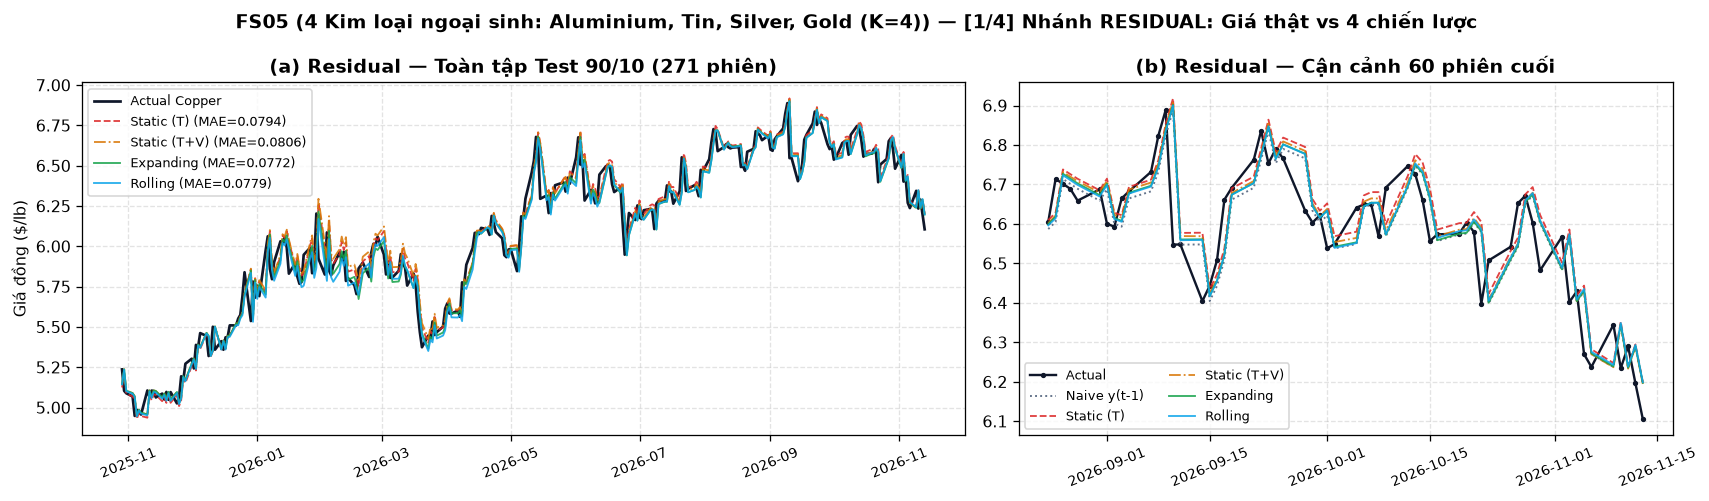

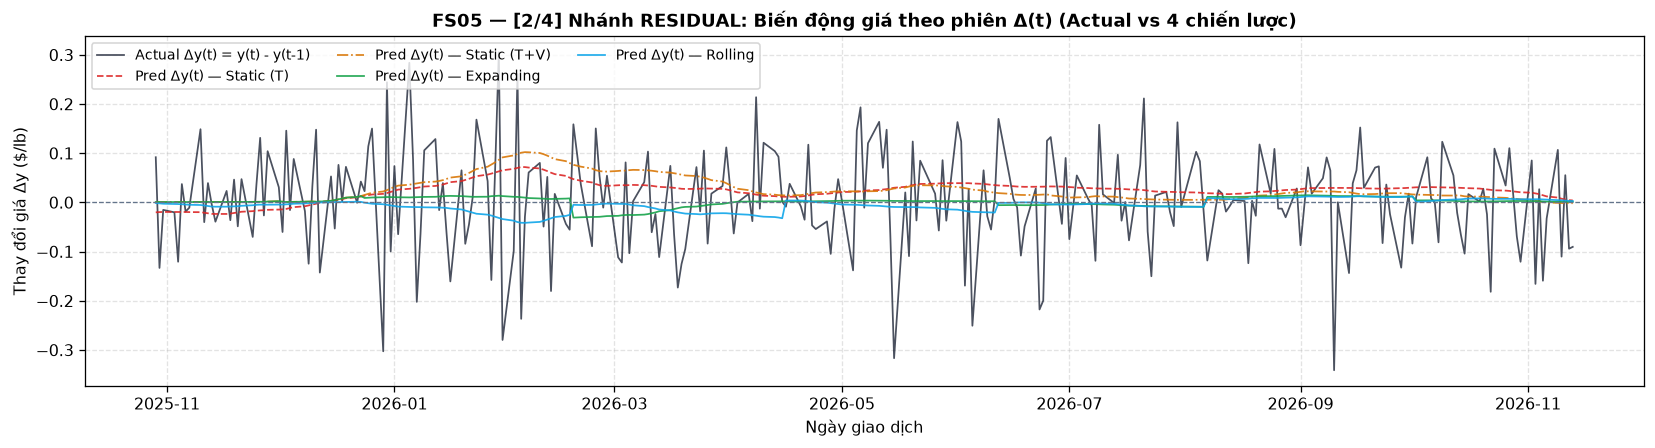

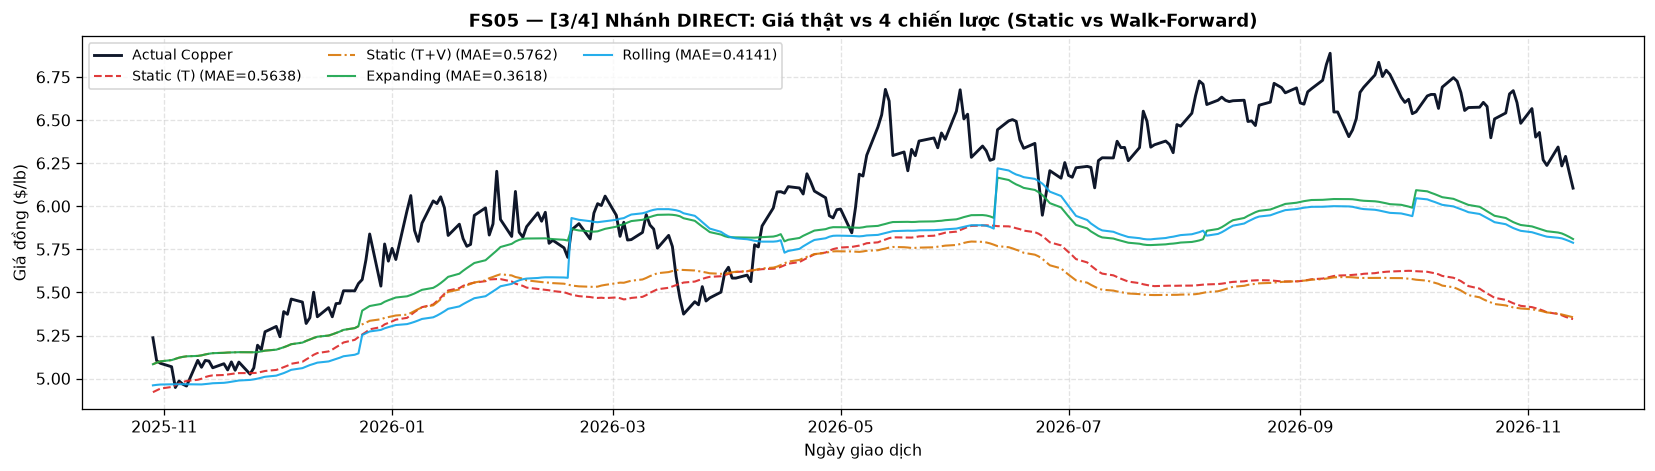

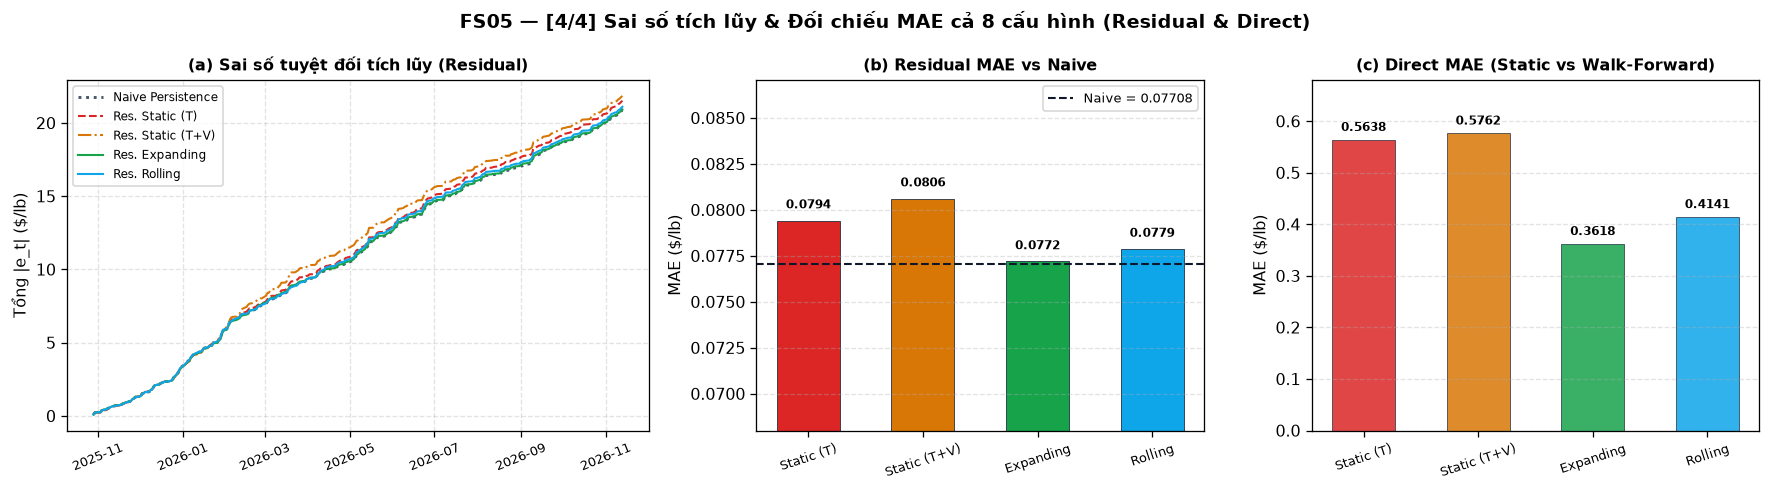

In [16]:
# === BIỂU ĐỒ ĐẦY ĐỦ 4 BIỂU ĐỒ CHO FS05 (FS05_METALS_EXO) ===
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE_DIR = OUT_DIR if ("OUT_DIR" in globals() and (Path(OUT_DIR) / "phase2_main_test_results.csv").exists()) else Path("result")
MET_DIR = (BASE_DIR / "metrics") if (BASE_DIR / "metrics").exists() else BASE_DIR
PRED_DIR = (BASE_DIR / "predictions") if (BASE_DIR / "predictions").exists() else BASE_DIR
FIG_ROOT = (BASE_DIR / "figures") if (BASE_DIR / "figures").exists() else BASE_DIR
FS_OUT = FIG_ROOT / "per_feature_set" / "FS05"
FS_OUT.mkdir(parents=True, exist_ok=True)

_main = pd.read_csv(MET_DIR / "phase2_main_test_results.csv")
_naive_mae = float(_main[_main["strategy"] == "naive_persistence"].iloc[0]["MAE"])

_strats = [
    ("static_train_only", "Static (T)", "#DC2626", "--"),
    ("static_train_val",  "Static (T+V)", "#D97706", "-."),
    ("expanding_window",  "Expanding", "#16A34A", "-"),
    ("rolling_window",    "Rolling", "#0EA5E9", "-"),
]

_res_dfs = {s: pd.read_csv(PRED_DIR / f"pred_RESIDUAL__FS05_METALS_EXO__{s}.csv") for s, _, _, _ in _strats}
_dir_dfs = {s: pd.read_csv(PRED_DIR / f"pred_FS05_METALS_EXO__{s}.csv") for s, _, _, _ in _strats}
_dates = pd.to_datetime(_res_dfs["expanding_window"]["Date"])
_actual = _res_dfs["expanding_window"]["actual"].to_numpy()
_prev = _res_dfs["expanding_window"]["prev_actual"].to_numpy()

# 1) RESIDUAL Copper(t): Toàn tập Test + Cận cảnh 60 phiên cuối (4 chiến lược)
fig, axes = plt.subplots(1, 2, figsize=(15.0, 4.4), gridspec_kw={"width_ratios": [1.35, 1.0]})
axes[0].plot(_dates, _actual, color="#0F172A", linewidth=1.7, label="Actual Copper")
for s, lbl, col, ls in _strats:
    mae_v = float(np.mean(np.abs(_res_dfs[s]["actual"] - _res_dfs[s]["predicted"])))
    axes[0].plot(_dates, _res_dfs[s]["predicted"], color=col, linestyle=ls, linewidth=1.15, alpha=0.88, label=f"{lbl} (MAE={mae_v:.4f})")
axes[0].set_title("(a) Residual — Toàn tập Test 90/10 (271 phiên)", fontweight="bold")
axes[0].set_ylabel("Giá đồng ($/lb)")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend(loc="upper left", fontsize=8.2)
axes[0].tick_params(axis="x", rotation=22, labelsize=8.5)

_sl = slice(-60, None)
axes[1].plot(_dates.iloc[_sl], _actual[_sl], color="#0F172A", marker="o", markersize=2.3, linewidth=1.5, label="Actual")
axes[1].plot(_dates.iloc[_sl], _prev[_sl], color="#64748B", linestyle=":", linewidth=1.2, label="Naive y(t-1)")
for s, lbl, col, ls in _strats:
    axes[1].plot(_dates.iloc[_sl], _res_dfs[s]["predicted"].iloc[_sl], color=col, linestyle=ls, linewidth=1.15, alpha=0.88, label=lbl)
axes[1].set_title("(b) Residual — Cận cảnh 60 phiên cuối", fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.35)
axes[1].legend(loc="lower left", fontsize=8.0, ncol=2)
axes[1].tick_params(axis="x", rotation=22, labelsize=8.5)
fig.suptitle("FS05 (4 Kim loại ngoại sinh: Aluminium, Tin, Silver, Gold (K=4)) — [1/4] Nhánh RESIDUAL: Giá thật vs 4 chiến lược", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(FS_OUT / "1_residual_price_4strategies.png", dpi=135)
plt.show()

# 2) RESIDUAL Copper Δ(t): Actual change vs Predicted change (4 chiến lược)
fig, ax = plt.subplots(figsize=(14.5, 4.0))
_act_delta = _actual - _prev
ax.plot(_dates, _act_delta, color="#0F172A", linewidth=1.1, alpha=0.75, label="Actual Δy(t) = y(t) - y(t-1)")
for s, lbl, col, ls in _strats:
    _pred_delta = _res_dfs[s]["predicted"].to_numpy() - _prev
    ax.plot(_dates, _pred_delta, color=col, linestyle=ls, linewidth=1.1, alpha=0.9, label=f"Pred Δy(t) — {lbl}")
ax.axhline(0, color="#64748B", linestyle="--", linewidth=0.8)
ax.set_title("FS05 — [2/4] Nhánh RESIDUAL: Biến động giá theo phiên Δ(t) (Actual vs 4 chiến lược)", fontsize=11.5, fontweight="bold")
ax.set_ylabel("Thay đổi giá Δy ($/lb)")
ax.set_xlabel("Ngày giao dịch")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
plt.tight_layout()
fig.savefig(FS_OUT / "2_residual_delta_4strategies.png", dpi=135)
plt.show()

# 3) DIRECT Copper(t): Giá thật vs 4 chiến lược (Static vs Walk-Forward)
fig, ax = plt.subplots(figsize=(14.5, 4.2))
ax.plot(_dates, _actual, color="#0F172A", linewidth=1.8, label="Actual Copper")
for s, lbl, col, ls in _strats:
    mae_v = float(np.mean(np.abs(_dir_dfs[s]["actual"] - _dir_dfs[s]["predicted"])))
    ax.plot(_dates, _dir_dfs[s]["predicted"], color=col, linestyle=ls, linewidth=1.3, alpha=0.9, label=f"{lbl} (MAE={mae_v:.4f})")
ax.set_title("FS05 — [3/4] Nhánh DIRECT: Giá thật vs 4 chiến lược (Static vs Walk-Forward)", fontsize=11.5, fontweight="bold")
ax.set_ylabel("Giá đồng ($/lb)")
ax.set_xlabel("Ngày giao dịch")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
plt.tight_layout()
fig.savefig(FS_OUT / "3_direct_price_4strategies.png", dpi=135)
plt.show()

# 4) Sai số tích lũy (Cumulative Abs Error) + Bảng cột MAE & DA% cho cả 8 cấu hình
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3), gridspec_kw={"width_ratios": [1.3, 1.0, 1.0]})
_cum_naive = np.cumsum(np.abs(_actual - _prev))
axes[0].plot(_dates, _cum_naive, color="#475569", linestyle=":", linewidth=1.8, label="Naive Persistence")
for s, lbl, col, ls in _strats:
    _cum = np.cumsum(np.abs(_res_dfs[s]["actual"].to_numpy() - _res_dfs[s]["predicted"].to_numpy()))
    axes[0].plot(_dates, _cum, color=col, linestyle=ls, linewidth=1.3, label=f"Res. {lbl}")
axes[0].set_title("(a) Sai số tuyệt đối tích lũy (Residual)", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Tổng |e_t| ($/lb)")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend(loc="upper left", fontsize=7.8)
axes[0].tick_params(axis="x", rotation=22, labelsize=8)

_sub_r = _main[(_main["feature_set"] == "FS05_METALS_EXO") & (_main["target_mode"] == "residual")].set_index("strategy")
_sub_d = _main[(_main["feature_set"] == "FS05_METALS_EXO") & (_main["target_mode"] == "direct")].set_index("strategy")
_x = np.arange(len(_strats))
_lbls = [lbl for _, lbl, _, _ in _strats]
_cols = [col for _, _, col, _ in _strats]

_rmae = [float(_sub_r.loc[s, "MAE"]) for s, _, _, _ in _strats]
_bars1 = axes[1].bar(_lbls, _rmae, color=_cols, width=0.55, edgecolor="#1E293B", linewidth=0.5)
axes[1].axhline(_naive_mae, color="#0F172A", linestyle="--", linewidth=1.3, label=f"Naive = {_naive_mae:.5f}")
axes[1].set_ylim(0.068, max(max(_rmae), _naive_mae) * 1.08)
axes[1].set_title("(b) Residual MAE vs Naive", fontsize=10, fontweight="bold")
axes[1].set_ylabel("MAE ($/lb)")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
axes[1].legend(loc="upper right", fontsize=8)
axes[1].tick_params(axis="x", rotation=18, labelsize=8)
for b in _bars1:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.0005, f"{b.get_height():.4f}", ha="center", va="bottom", fontsize=7.8, fontweight="bold")

_dmae = [float(_sub_d.loc[s, "MAE"]) for s, _, _, _ in _strats]
_bars2 = axes[2].bar(_lbls, _dmae, color=_cols, width=0.55, edgecolor="#1E293B", linewidth=0.5, alpha=0.85)
axes[2].set_ylim(0, max(_dmae) * 1.18)
axes[2].set_title("(c) Direct MAE (Static vs Walk-Forward)", fontsize=10, fontweight="bold")
axes[2].set_ylabel("MAE ($/lb)")
axes[2].grid(axis="y", linestyle="--", alpha=0.35)
axes[2].tick_params(axis="x", rotation=18, labelsize=8)
for b in _bars2:
    axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + max(_dmae)*0.02, f"{b.get_height():.4f}", ha="center", va="bottom", fontsize=7.8, fontweight="bold")

fig.suptitle("FS05 — [4/4] Sai số tích lũy & Đối chiếu MAE cả 8 cấu hình (Residual & Direct)", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(FS_OUT / "4_error_and_mae_summary.png", dpi=135)
plt.show()

### 6.6. FS06 — Kim loại + WTI: Copper, Aluminium, Tin, WTI (K=4) (`FS06_WTI_CU`)

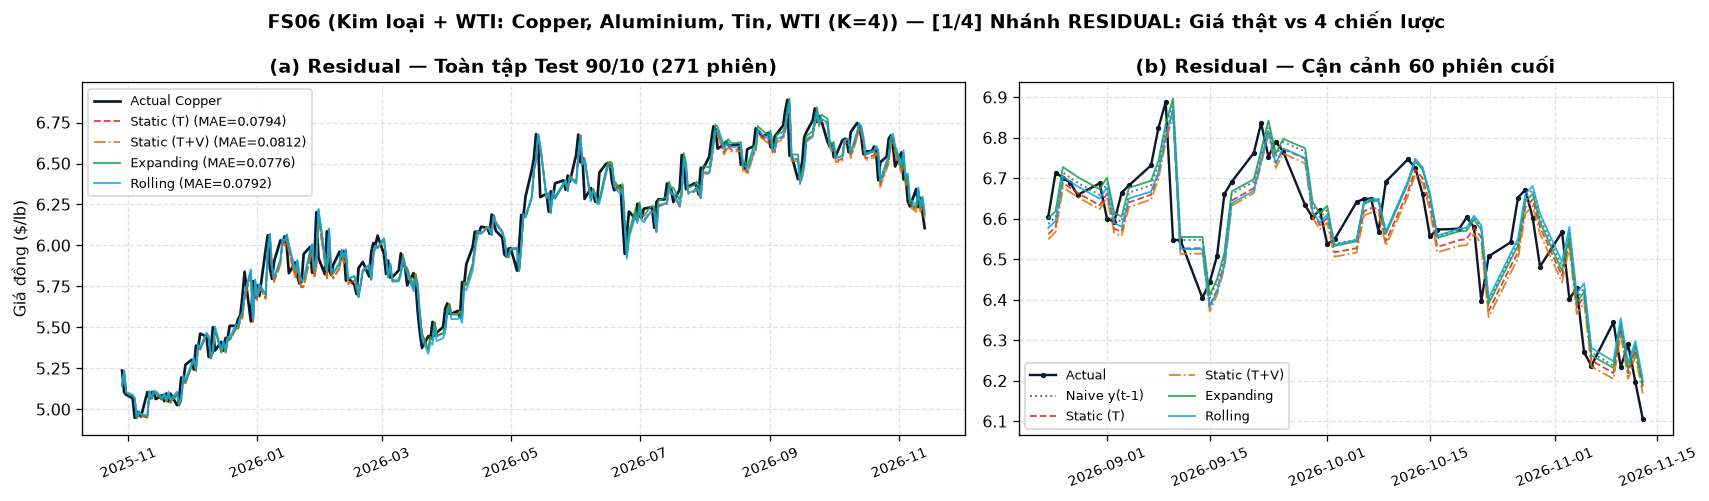

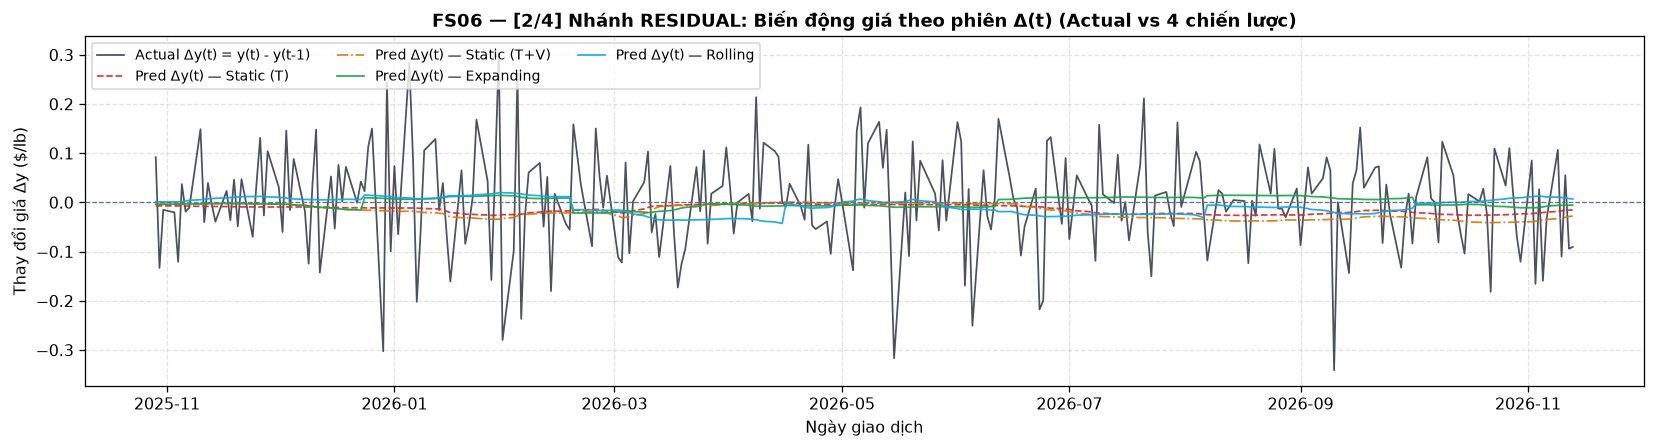

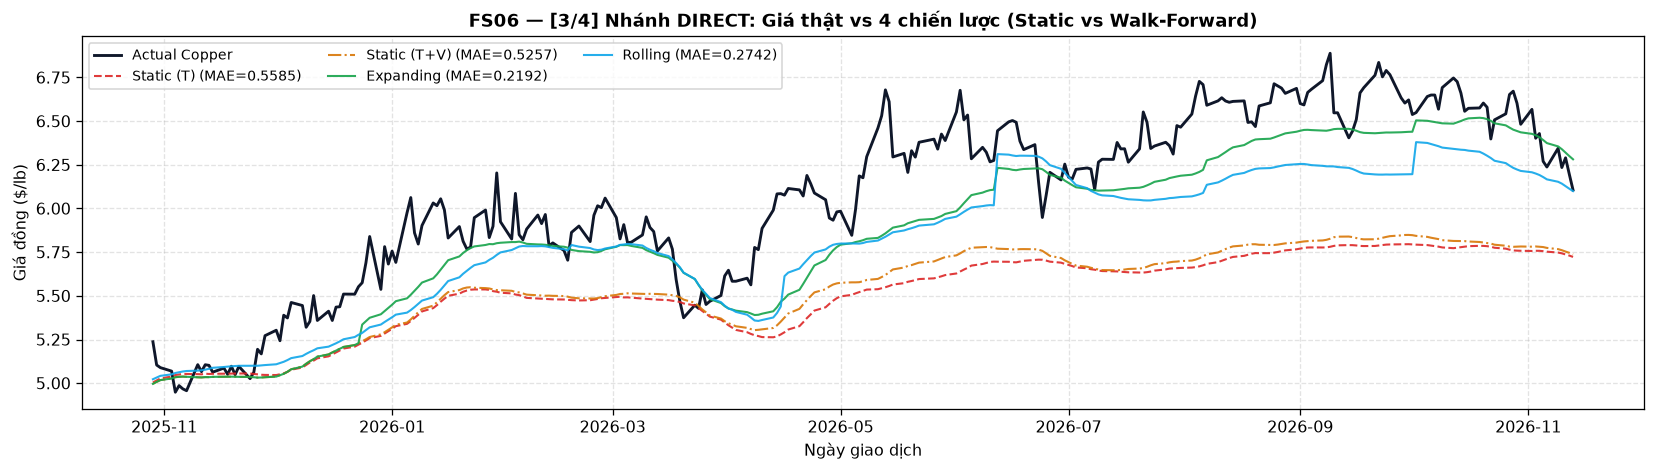

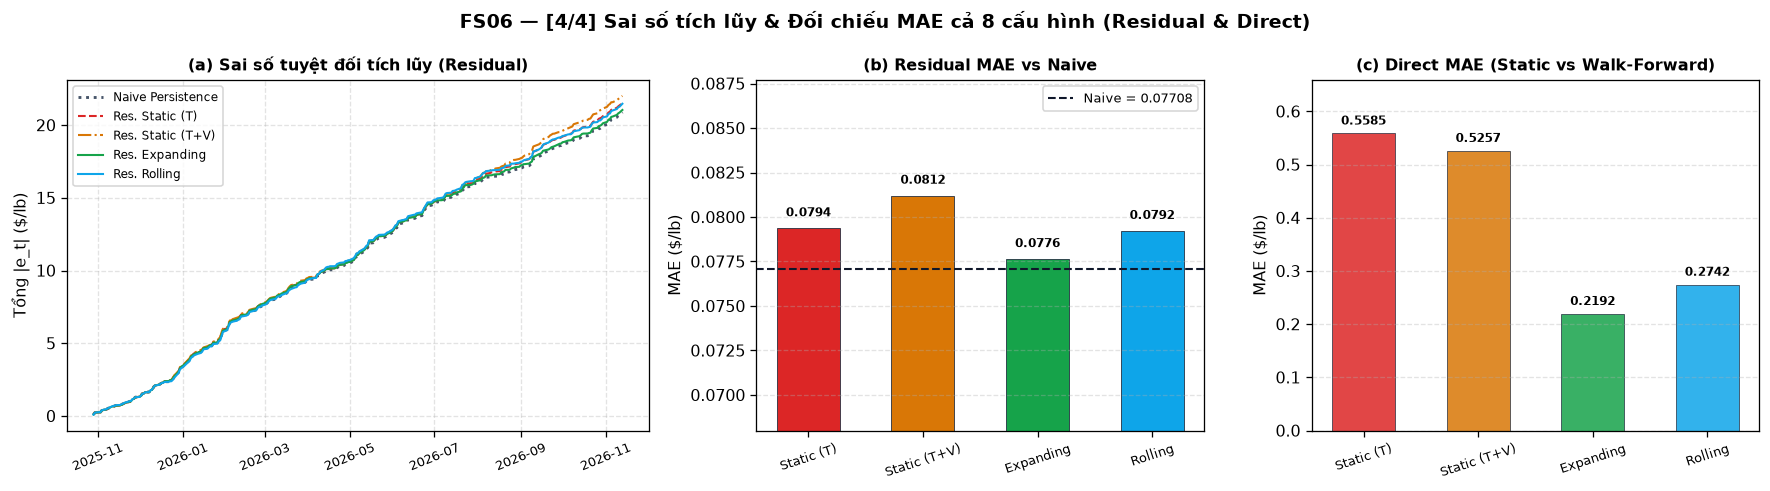

In [17]:
# === BIỂU ĐỒ ĐẦY ĐỦ 4 BIỂU ĐỒ CHO FS06 (FS06_WTI_CU) ===
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE_DIR = OUT_DIR if ("OUT_DIR" in globals() and (Path(OUT_DIR) / "phase2_main_test_results.csv").exists()) else Path("result")
MET_DIR = (BASE_DIR / "metrics") if (BASE_DIR / "metrics").exists() else BASE_DIR
PRED_DIR = (BASE_DIR / "predictions") if (BASE_DIR / "predictions").exists() else BASE_DIR
FIG_ROOT = (BASE_DIR / "figures") if (BASE_DIR / "figures").exists() else BASE_DIR
FS_OUT = FIG_ROOT / "per_feature_set" / "FS06"
FS_OUT.mkdir(parents=True, exist_ok=True)

_main = pd.read_csv(MET_DIR / "phase2_main_test_results.csv")
_naive_mae = float(_main[_main["strategy"] == "naive_persistence"].iloc[0]["MAE"])

_strats = [
    ("static_train_only", "Static (T)", "#DC2626", "--"),
    ("static_train_val",  "Static (T+V)", "#D97706", "-."),
    ("expanding_window",  "Expanding", "#16A34A", "-"),
    ("rolling_window",    "Rolling", "#0EA5E9", "-"),
]

_res_dfs = {s: pd.read_csv(PRED_DIR / f"pred_RESIDUAL__FS06_WTI_CU__{s}.csv") for s, _, _, _ in _strats}
_dir_dfs = {s: pd.read_csv(PRED_DIR / f"pred_FS06_WTI_CU__{s}.csv") for s, _, _, _ in _strats}
_dates = pd.to_datetime(_res_dfs["expanding_window"]["Date"])
_actual = _res_dfs["expanding_window"]["actual"].to_numpy()
_prev = _res_dfs["expanding_window"]["prev_actual"].to_numpy()

# 1) RESIDUAL Copper(t): Toàn tập Test + Cận cảnh 60 phiên cuối (4 chiến lược)
fig, axes = plt.subplots(1, 2, figsize=(15.0, 4.4), gridspec_kw={"width_ratios": [1.35, 1.0]})
axes[0].plot(_dates, _actual, color="#0F172A", linewidth=1.7, label="Actual Copper")
for s, lbl, col, ls in _strats:
    mae_v = float(np.mean(np.abs(_res_dfs[s]["actual"] - _res_dfs[s]["predicted"])))
    axes[0].plot(_dates, _res_dfs[s]["predicted"], color=col, linestyle=ls, linewidth=1.15, alpha=0.88, label=f"{lbl} (MAE={mae_v:.4f})")
axes[0].set_title("(a) Residual — Toàn tập Test 90/10 (271 phiên)", fontweight="bold")
axes[0].set_ylabel("Giá đồng ($/lb)")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend(loc="upper left", fontsize=8.2)
axes[0].tick_params(axis="x", rotation=22, labelsize=8.5)

_sl = slice(-60, None)
axes[1].plot(_dates.iloc[_sl], _actual[_sl], color="#0F172A", marker="o", markersize=2.3, linewidth=1.5, label="Actual")
axes[1].plot(_dates.iloc[_sl], _prev[_sl], color="#64748B", linestyle=":", linewidth=1.2, label="Naive y(t-1)")
for s, lbl, col, ls in _strats:
    axes[1].plot(_dates.iloc[_sl], _res_dfs[s]["predicted"].iloc[_sl], color=col, linestyle=ls, linewidth=1.15, alpha=0.88, label=lbl)
axes[1].set_title("(b) Residual — Cận cảnh 60 phiên cuối", fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.35)
axes[1].legend(loc="lower left", fontsize=8.0, ncol=2)
axes[1].tick_params(axis="x", rotation=22, labelsize=8.5)
fig.suptitle("FS06 (Kim loại + WTI: Copper, Aluminium, Tin, WTI (K=4)) — [1/4] Nhánh RESIDUAL: Giá thật vs 4 chiến lược", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(FS_OUT / "1_residual_price_4strategies.png", dpi=135)
plt.show()

# 2) RESIDUAL Copper Δ(t): Actual change vs Predicted change (4 chiến lược)
fig, ax = plt.subplots(figsize=(14.5, 4.0))
_act_delta = _actual - _prev
ax.plot(_dates, _act_delta, color="#0F172A", linewidth=1.1, alpha=0.75, label="Actual Δy(t) = y(t) - y(t-1)")
for s, lbl, col, ls in _strats:
    _pred_delta = _res_dfs[s]["predicted"].to_numpy() - _prev
    ax.plot(_dates, _pred_delta, color=col, linestyle=ls, linewidth=1.1, alpha=0.9, label=f"Pred Δy(t) — {lbl}")
ax.axhline(0, color="#64748B", linestyle="--", linewidth=0.8)
ax.set_title("FS06 — [2/4] Nhánh RESIDUAL: Biến động giá theo phiên Δ(t) (Actual vs 4 chiến lược)", fontsize=11.5, fontweight="bold")
ax.set_ylabel("Thay đổi giá Δy ($/lb)")
ax.set_xlabel("Ngày giao dịch")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
plt.tight_layout()
fig.savefig(FS_OUT / "2_residual_delta_4strategies.png", dpi=135)
plt.show()

# 3) DIRECT Copper(t): Giá thật vs 4 chiến lược (Static vs Walk-Forward)
fig, ax = plt.subplots(figsize=(14.5, 4.2))
ax.plot(_dates, _actual, color="#0F172A", linewidth=1.8, label="Actual Copper")
for s, lbl, col, ls in _strats:
    mae_v = float(np.mean(np.abs(_dir_dfs[s]["actual"] - _dir_dfs[s]["predicted"])))
    ax.plot(_dates, _dir_dfs[s]["predicted"], color=col, linestyle=ls, linewidth=1.3, alpha=0.9, label=f"{lbl} (MAE={mae_v:.4f})")
ax.set_title("FS06 — [3/4] Nhánh DIRECT: Giá thật vs 4 chiến lược (Static vs Walk-Forward)", fontsize=11.5, fontweight="bold")
ax.set_ylabel("Giá đồng ($/lb)")
ax.set_xlabel("Ngày giao dịch")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
plt.tight_layout()
fig.savefig(FS_OUT / "3_direct_price_4strategies.png", dpi=135)
plt.show()

# 4) Sai số tích lũy (Cumulative Abs Error) + Bảng cột MAE & DA% cho cả 8 cấu hình
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3), gridspec_kw={"width_ratios": [1.3, 1.0, 1.0]})
_cum_naive = np.cumsum(np.abs(_actual - _prev))
axes[0].plot(_dates, _cum_naive, color="#475569", linestyle=":", linewidth=1.8, label="Naive Persistence")
for s, lbl, col, ls in _strats:
    _cum = np.cumsum(np.abs(_res_dfs[s]["actual"].to_numpy() - _res_dfs[s]["predicted"].to_numpy()))
    axes[0].plot(_dates, _cum, color=col, linestyle=ls, linewidth=1.3, label=f"Res. {lbl}")
axes[0].set_title("(a) Sai số tuyệt đối tích lũy (Residual)", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Tổng |e_t| ($/lb)")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend(loc="upper left", fontsize=7.8)
axes[0].tick_params(axis="x", rotation=22, labelsize=8)

_sub_r = _main[(_main["feature_set"] == "FS06_WTI_CU") & (_main["target_mode"] == "residual")].set_index("strategy")
_sub_d = _main[(_main["feature_set"] == "FS06_WTI_CU") & (_main["target_mode"] == "direct")].set_index("strategy")
_x = np.arange(len(_strats))
_lbls = [lbl for _, lbl, _, _ in _strats]
_cols = [col for _, _, col, _ in _strats]

_rmae = [float(_sub_r.loc[s, "MAE"]) for s, _, _, _ in _strats]
_bars1 = axes[1].bar(_lbls, _rmae, color=_cols, width=0.55, edgecolor="#1E293B", linewidth=0.5)
axes[1].axhline(_naive_mae, color="#0F172A", linestyle="--", linewidth=1.3, label=f"Naive = {_naive_mae:.5f}")
axes[1].set_ylim(0.068, max(max(_rmae), _naive_mae) * 1.08)
axes[1].set_title("(b) Residual MAE vs Naive", fontsize=10, fontweight="bold")
axes[1].set_ylabel("MAE ($/lb)")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
axes[1].legend(loc="upper right", fontsize=8)
axes[1].tick_params(axis="x", rotation=18, labelsize=8)
for b in _bars1:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.0005, f"{b.get_height():.4f}", ha="center", va="bottom", fontsize=7.8, fontweight="bold")

_dmae = [float(_sub_d.loc[s, "MAE"]) for s, _, _, _ in _strats]
_bars2 = axes[2].bar(_lbls, _dmae, color=_cols, width=0.55, edgecolor="#1E293B", linewidth=0.5, alpha=0.85)
axes[2].set_ylim(0, max(_dmae) * 1.18)
axes[2].set_title("(c) Direct MAE (Static vs Walk-Forward)", fontsize=10, fontweight="bold")
axes[2].set_ylabel("MAE ($/lb)")
axes[2].grid(axis="y", linestyle="--", alpha=0.35)
axes[2].tick_params(axis="x", rotation=18, labelsize=8)
for b in _bars2:
    axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + max(_dmae)*0.02, f"{b.get_height():.4f}", ha="center", va="bottom", fontsize=7.8, fontweight="bold")

fig.suptitle("FS06 — [4/4] Sai số tích lũy & Đối chiếu MAE cả 8 cấu hình (Residual & Direct)", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(FS_OUT / "4_error_and_mae_summary.png", dpi=135)
plt.show()

## 7. Biểu đồ so sánh tổng hợp toàn diện (`Fig 2` → `Fig 15`)

### 7.1. Bộ biểu đồ tổng hợp chuẩn từ lần chạy Kaggle (`Fig 2` → `Fig 11`)
Sơ đồ Walk-Forward, sai số tích lũy, Regime breakdown, Trade-off Ablation, Directional Accuracy, Cross-Ratio Direct và đối chiếu Direct vs Residual trên 6 bộ biến.

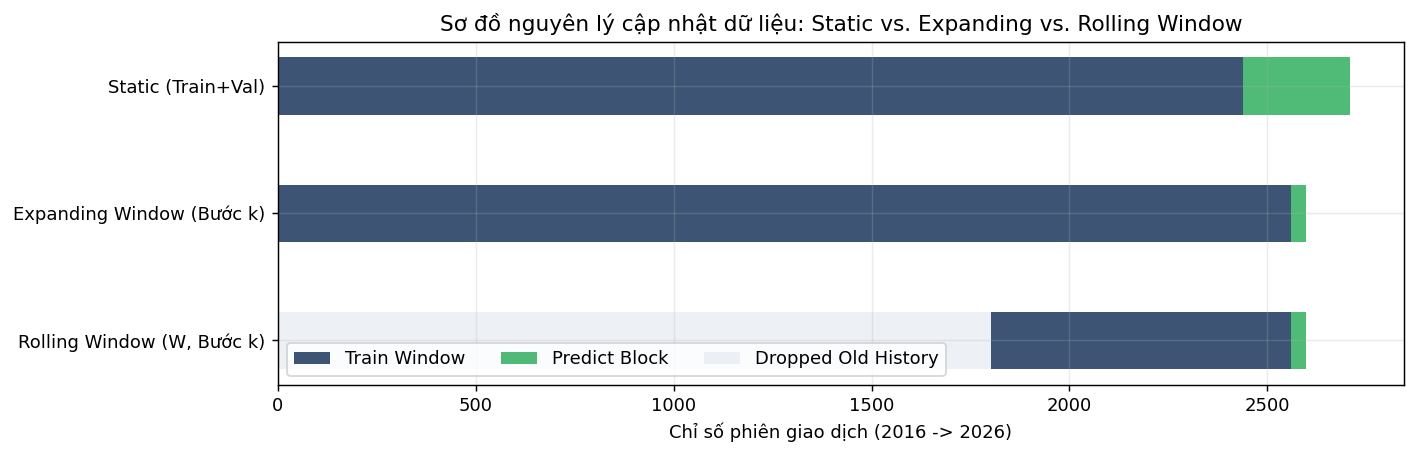

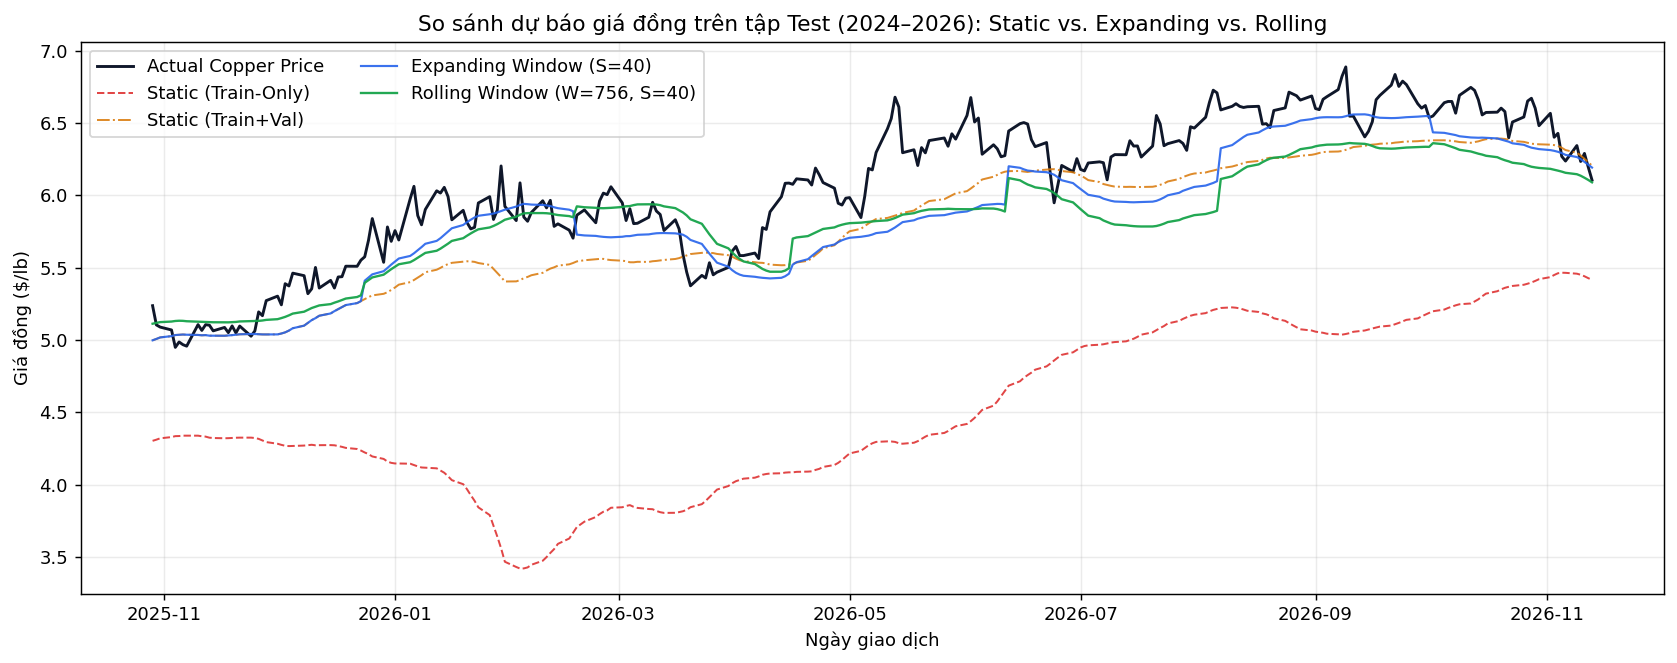

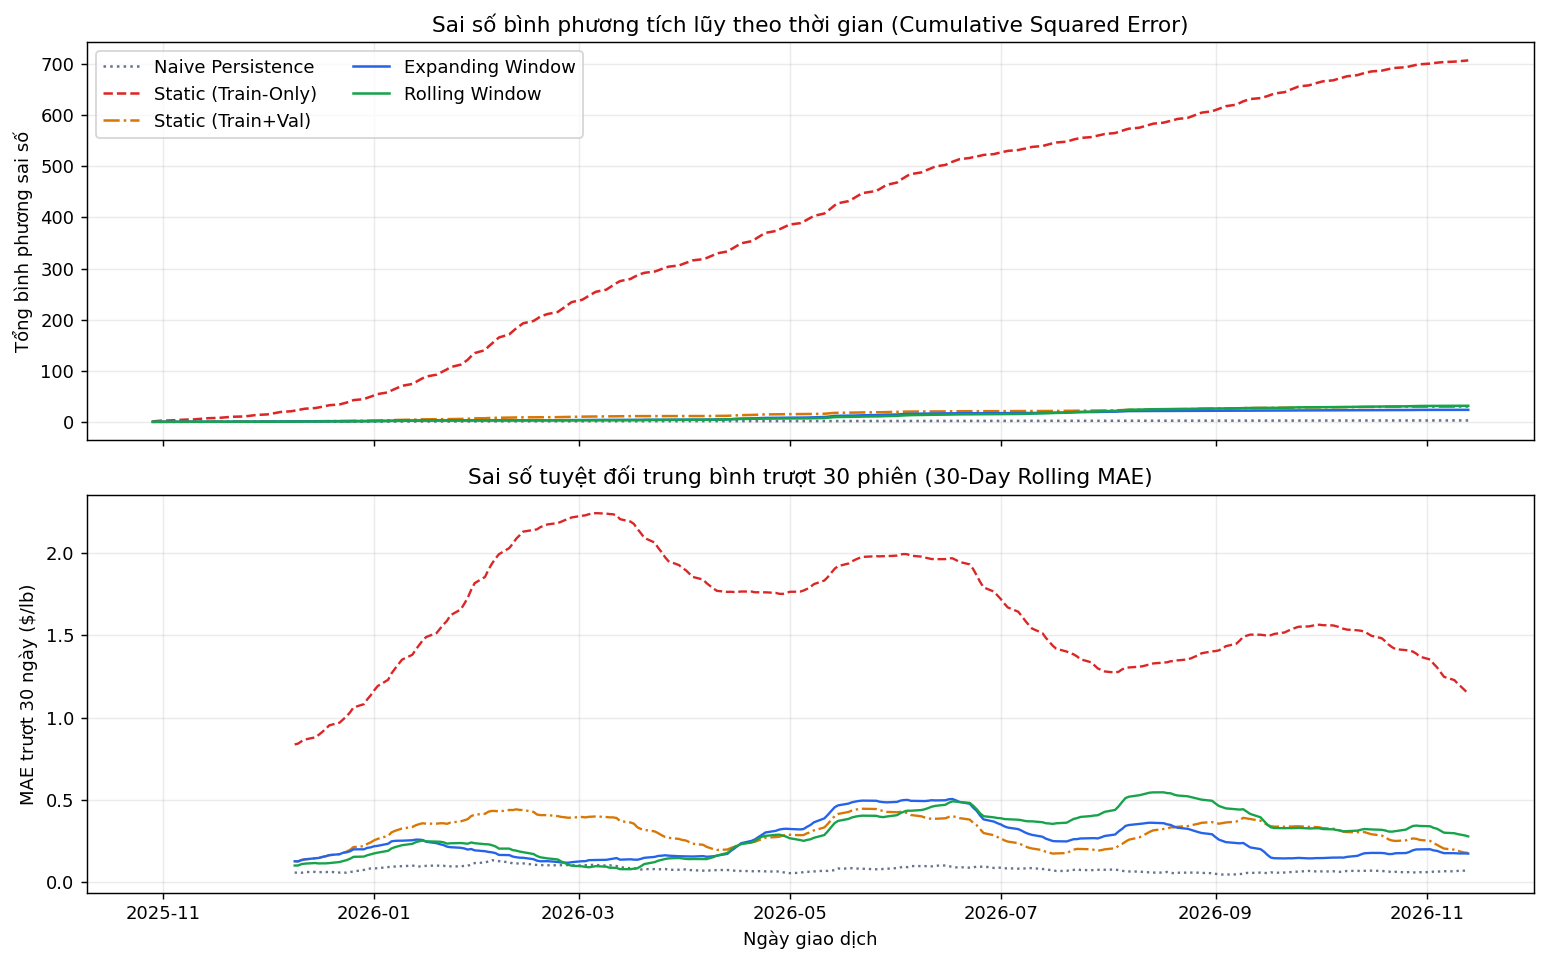

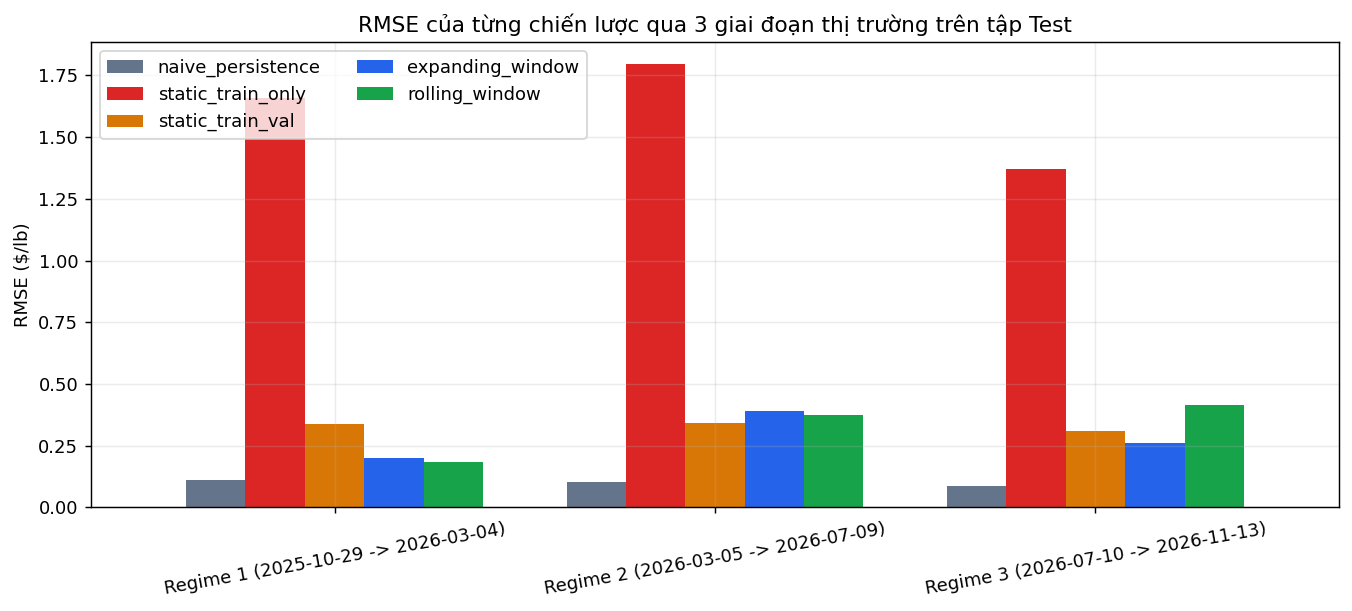

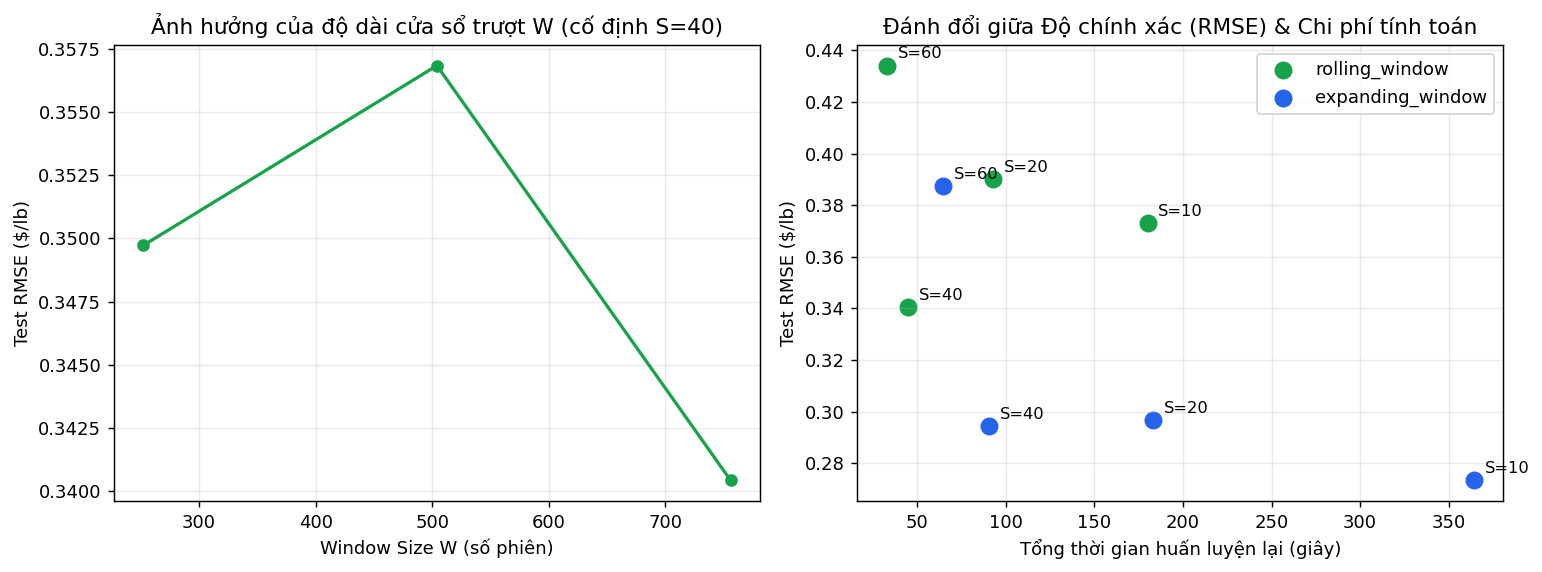

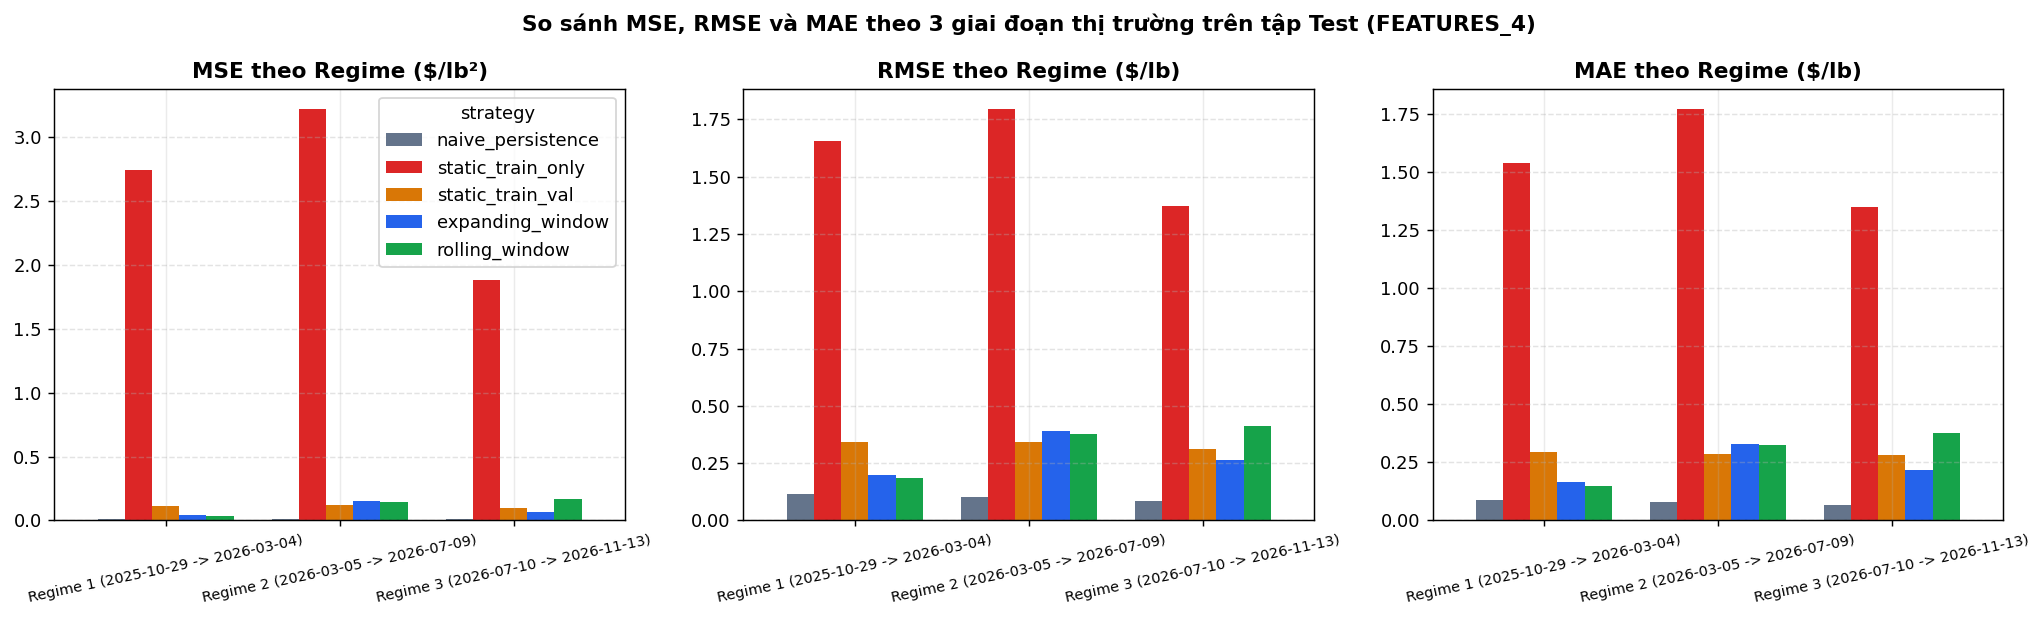

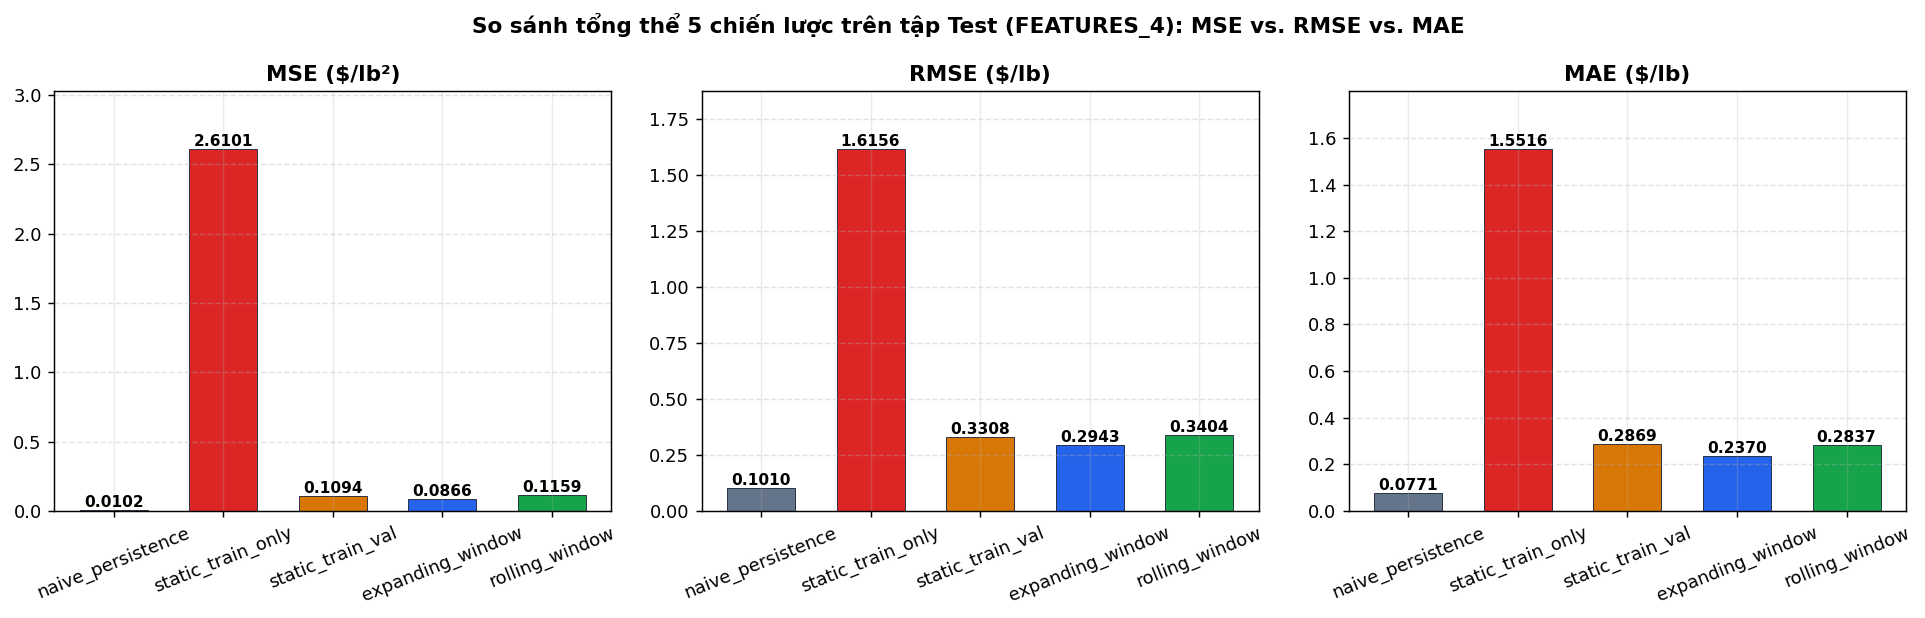

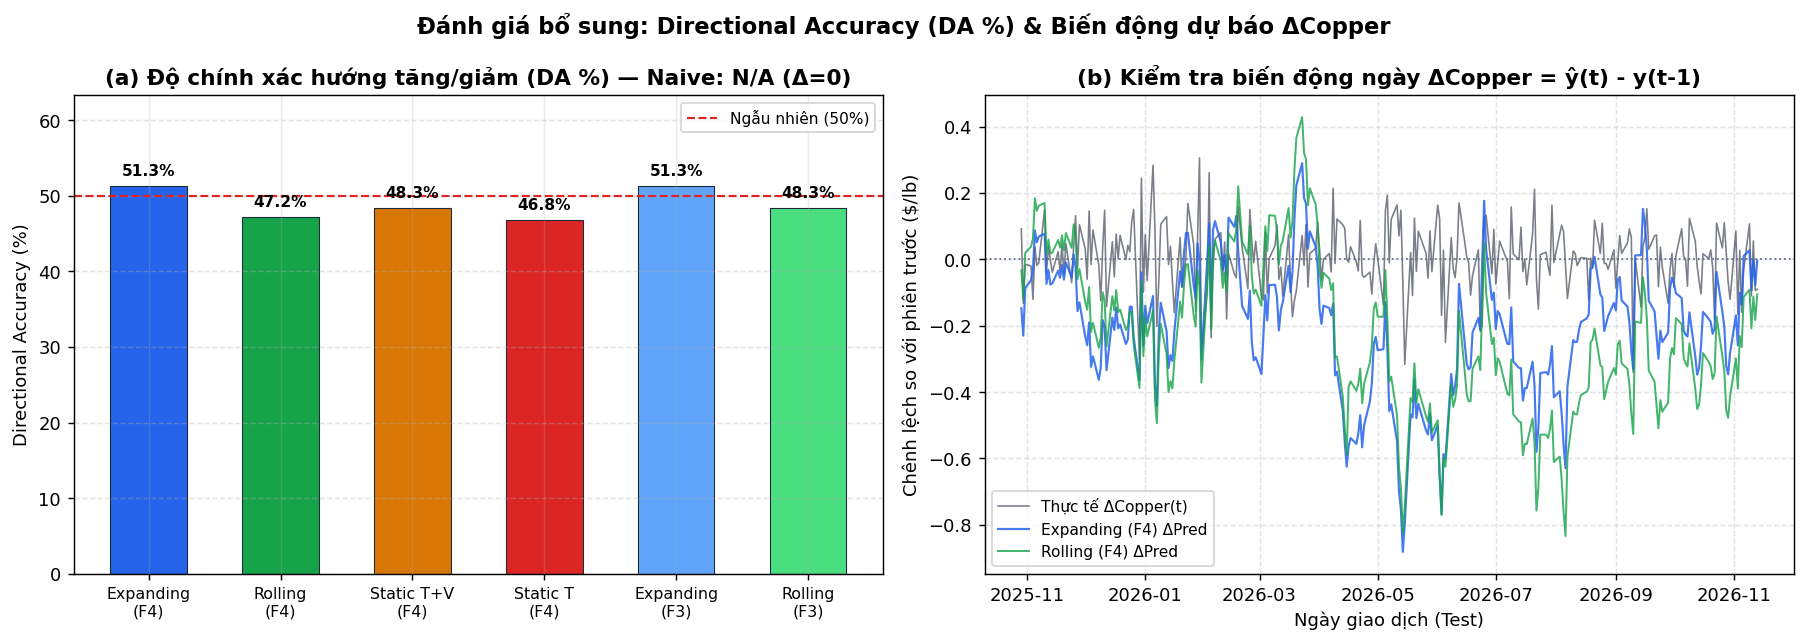

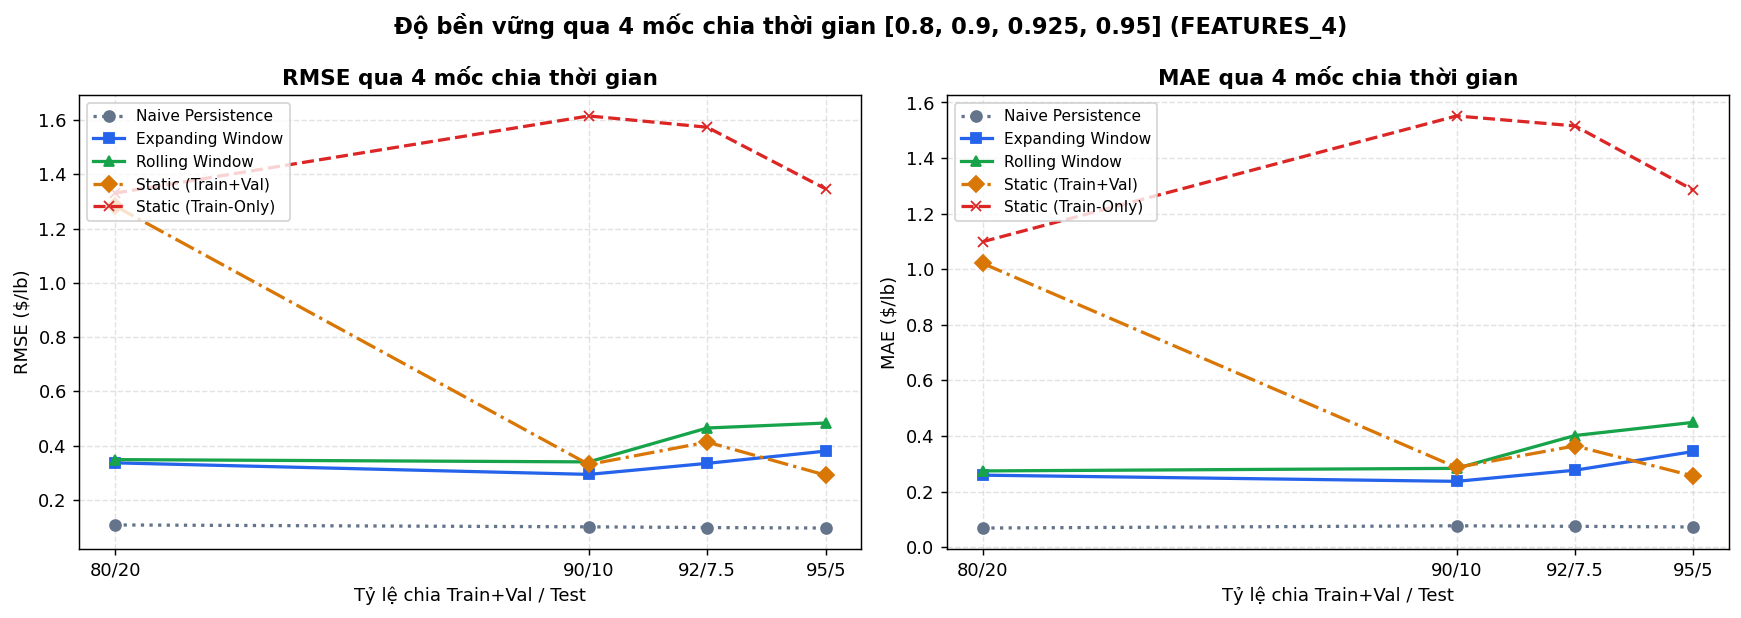

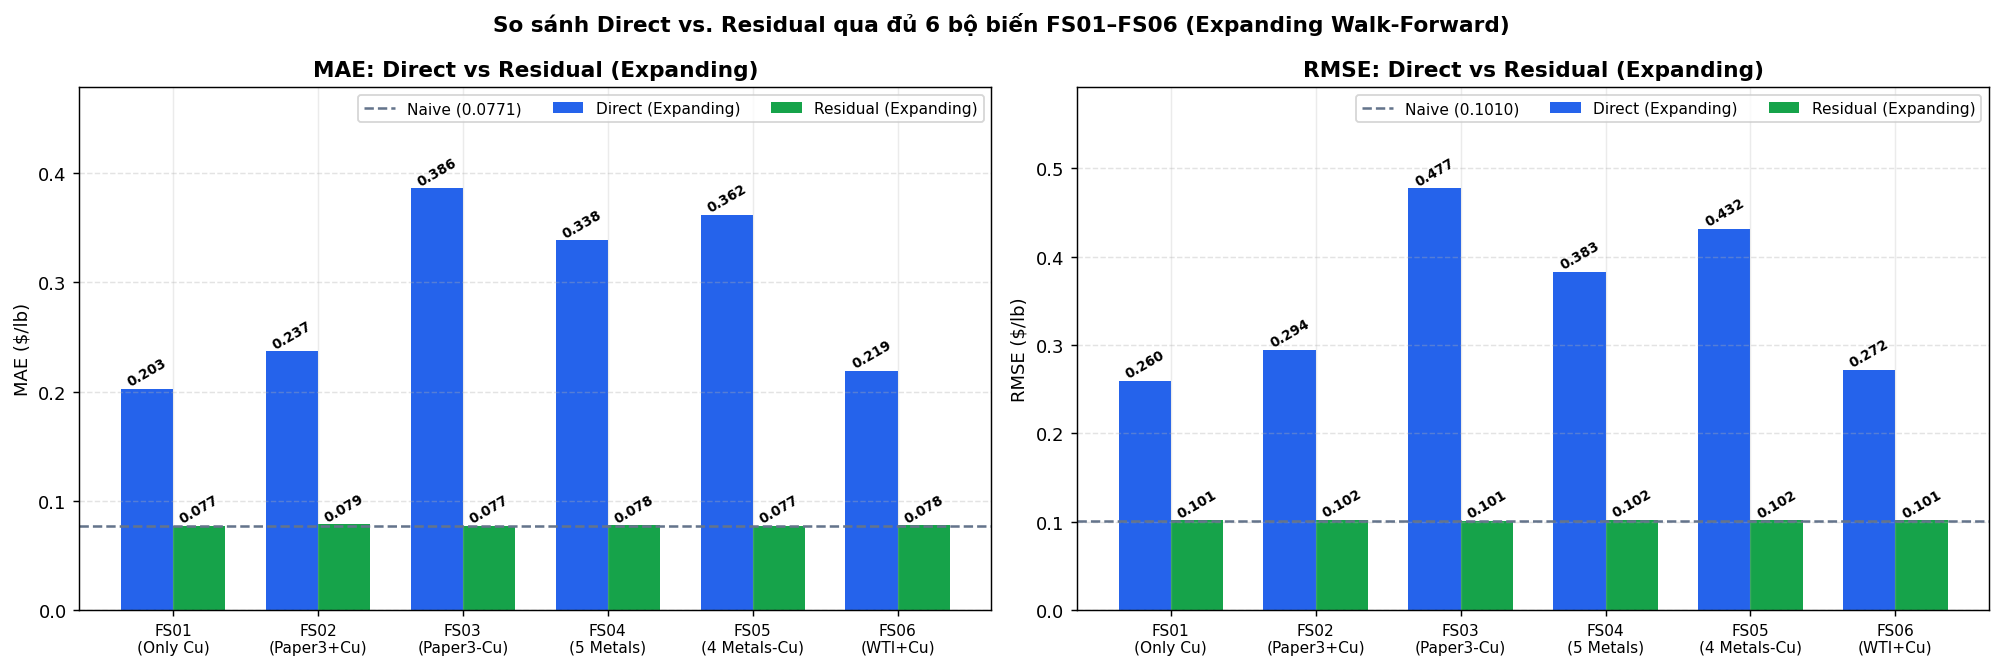

In [11]:
# Fig 2: Sơ đồ minh họa cơ chế Static / Expanding / Rolling
fig, ax = plt.subplots(figsize=(11, 3.6))
y_positions = [3, 2, 1]
labels = ["Static (Train+Val)", "Expanding Window (Bước k)", "Rolling Window (W, Bước k)"]
n_tot = len(data)
n_tv = test_start_primary
n_te = n_tot - n_tv
mid_origin = n_tv + min(120, n_te // 2)
ax.barh(3, n_tv, left=0, height=0.45, color="#1B365D", alpha=0.85, label="Train Window")
ax.barh(3, n_te, left=n_tv, height=0.45, color="#16A34A", alpha=0.75, label="Predict Block")

ax.barh(2, mid_origin, left=0, height=0.45, color="#1B365D", alpha=0.85)
ax.barh(2, BEST_S, left=mid_origin, height=0.45, color="#16A34A", alpha=0.75)

w_show = BEST_W
drop_show = max(0, mid_origin - w_show)
ax.barh(1, w_show, left=drop_show, height=0.45, color="#1B365D", alpha=0.85)
ax.barh(1, drop_show, left=0, height=0.45, color="#E2E8F0", alpha=0.6, label="Dropped Old History")
ax.barh(1, BEST_S, left=mid_origin, height=0.45, color="#16A34A", alpha=0.75)

ax.set_yticks(y_positions)
ax.set_yticklabels(labels)
ax.set_xlabel("Chỉ số phiên giao dịch (2016 -> 2026)")
ax.set_title("Sơ đồ nguyên lý cập nhật dữ liệu: Static vs. Expanding vs. Rolling Window")
ax.legend(loc="lower left", ncol=3)
plt.tight_layout()
fig.savefig(OUT_DIR / "fig2_walkforward_schematic.png", dpi=150)
plt.show()

# Fig 3: Actual vs Predicted trên tập Test
fig, ax = plt.subplots(figsize=(13, 5.2))
df_roll = test_predictions["FEATURES_4__rolling_window"]
df_exp = test_predictions["FEATURES_4__expanding_window"]
df_stat = test_predictions["FEATURES_4__static_train_only"]
df_stv = test_predictions["FEATURES_4__static_train_val"]

dates_t = pd.to_datetime(df_roll["Date"])
ax.plot(dates_t, df_roll["actual"], color="#0F172A", linewidth=1.6, label="Actual Copper Price")
ax.plot(dates_t, df_stat["predicted"], color="#DC2626", linewidth=1.1, linestyle="--", alpha=0.85, label="Static (Train-Only)")
ax.plot(dates_t, df_stv["predicted"], color="#D97706", linewidth=1.1, linestyle="-.", alpha=0.85, label="Static (Train+Val)")
ax.plot(dates_t, df_exp["predicted"], color="#2563EB", linewidth=1.2, alpha=0.9, label=f"Expanding Window (S={BEST_S})")
ax.plot(dates_t, df_roll["predicted"], color="#16A34A", linewidth=1.3, alpha=0.95, label=f"Rolling Window (W={BEST_W}, S={BEST_S})")
ax.set_title("So sánh dự báo giá đồng trên tập Test (2024–2026): Static vs. Expanding vs. Rolling")
ax.set_ylabel("Giá đồng ($/lb)")
ax.set_xlabel("Ngày giao dịch")
ax.legend(loc="best", ncol=2)
plt.tight_layout()
fig.savefig(OUT_DIR / "fig3_actual_vs_predicted.png", dpi=150)
plt.show()

# Fig 4: Cumulative Squared Error (CSE) & Fig 5: Rolling 30-day MAE
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
styles = [
    ("FEATURES_4__naive_persistence", "Naive Persistence", "#64748B", ":"),
    ("FEATURES_4__static_train_only", "Static (Train-Only)", "#DC2626", "--"),
    ("FEATURES_4__static_train_val", "Static (Train+Val)", "#D97706", "-."),
    ("FEATURES_4__expanding_window", "Expanding Window", "#2563EB", "-"),
    ("FEATURES_4__rolling_window", "Rolling Window", "#16A34A", "-"),
]
for key, name, col, ls in styles:
    d = test_predictions[key]
    axes[0].plot(dates_t, d["sq_error"].cumsum(), label=name, color=col, linestyle=ls, linewidth=1.4)
    axes[1].plot(dates_t, d["abs_error"].rolling(30).mean(), label=name, color=col, linestyle=ls, linewidth=1.3)

axes[0].set_title("Sai số bình phương tích lũy theo thời gian (Cumulative Squared Error)")
axes[0].set_ylabel("Tổng bình phương sai số")
axes[0].legend(loc="upper left", ncol=2)

axes[1].set_title("Sai số tuyệt đối trung bình trượt 30 phiên (30-Day Rolling MAE)")
axes[1].set_ylabel("MAE trượt 30 ngày ($/lb)")
axes[1].set_xlabel("Ngày giao dịch")
plt.tight_layout()
fig.savefig(OUT_DIR / "fig4_5_cumulative_and_rolling_errors.png", dpi=150)
plt.show()

# Fig 6: Regime Comparison Bar Chart
fig, ax = plt.subplots(figsize=(10.5, 4.8))
pivot_reg = regime_df.pivot(index="regime", columns="strategy", values="RMSE")[
    ["naive_persistence", "static_train_only", "static_train_val", "expanding_window", "rolling_window"]
]
pivot_reg.plot(kind="bar", ax=ax, width=0.78, color=["#64748B", "#DC2626", "#D97706", "#2563EB", "#16A34A"])
ax.set_title("RMSE của từng chiến lược qua 3 giai đoạn thị trường trên tập Test")
ax.set_ylabel("RMSE ($/lb)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=10)
ax.legend(loc="upper left", ncol=2)
plt.tight_layout()
fig.savefig(OUT_DIR / "fig6_regime_comparison_bar.png", dpi=150)
plt.show()

# Fig 7: Ablation Trade-off (Accuracy vs Retraining Cost)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ab_w = ablation_df[ablation_df["ablation_type"] == "window_size"]
axes[0].plot(ab_w["window_size"].astype(int), ab_w["RMSE"], marker="o", color="#16A34A", linewidth=1.8, label="RMSE")
axes[0].set_title(f"Ảnh hưởng của độ dài cửa sổ trượt W (cố định S={BEST_S})")
axes[0].set_xlabel("Window Size W (số phiên)")
axes[0].set_ylabel("Test RMSE ($/lb)")

ab_s = ablation_df[ablation_df["ablation_type"] == "retrain_stride"]
for strat, col in [("rolling_window", "#16A34A"), ("expanding_window", "#2563EB")]:
    sub = ab_s[ab_s["strategy"] == strat]
    axes[1].scatter(sub["total_train_sec"], sub["RMSE"], s=80, color=col, label=strat)
    for _, r in sub.iterrows():
        axes[1].annotate(f"S={int(r['stride'])}", (r["total_train_sec"], r["RMSE"]),
                         textcoords="offset points", xytext=(6, 4), fontsize=9)
axes[1].set_title("Đánh đổi giữa Độ chính xác (RMSE) & Chi phí tính toán")
axes[1].set_xlabel("Tổng thời gian huấn luyện lại (giây)")
axes[1].set_ylabel("Test RMSE ($/lb)")
axes[1].legend()
plt.tight_layout()
fig.savefig(OUT_DIR / "fig7_ablation_tradeoff.png", dpi=150)
plt.show()
# Fig 6b: Regime MSE / RMSE / MAE Breakdown
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
reg_order = ["naive_persistence", "static_train_only", "static_train_val", "expanding_window", "rolling_window"]
reg_colors = ["#64748B", "#DC2626", "#D97706", "#2563EB", "#16A34A"]
for ax_i, (m_col, m_title) in enumerate([("MSE_price2", "MSE theo Regime ($/lb²)"), ("RMSE", "RMSE theo Regime ($/lb)"), ("MAE", "MAE theo Regime ($/lb)")]):
    piv = regime_df.pivot(index="regime", columns="strategy", values=m_col)[reg_order]
    piv.plot(kind="bar", ax=axes[ax_i], width=0.78, color=reg_colors, legend=(ax_i == 0))
    axes[ax_i].set_title(m_title, fontweight="bold")
    axes[ax_i].set_xlabel("")
    axes[ax_i].tick_params(axis="x", rotation=12, labelsize=8)
    axes[ax_i].grid(axis="y", linestyle="--", alpha=0.35)
fig.suptitle("So sánh MSE, RMSE và MAE theo 3 giai đoạn thị trường trên tập Test (FEATURES_4)", fontweight="bold")
plt.tight_layout()
fig.savefig(OUT_DIR / "fig6_regime_mse_rmse_mae.png", dpi=150)
plt.show()

# Fig 8: So sánh đồng thời cả 3 chỉ số MSE, RMSE và MAE trên tập Test (kèm giá trị trên đỉnh cột)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
f4_sub = main_test_df[(main_test_df["target_mode"] == "direct") & (main_test_df["feature_set"] == "FEATURES_4")].set_index("strategy").loc[
    ["naive_persistence", "static_train_only", "static_train_val", "expanding_window", "rolling_window"]
]
bar_colors = ["#64748B", "#DC2626", "#D97706", "#2563EB", "#16A34A"]
for ax_i, (m_col, m_title) in enumerate([("MSE_price2", "MSE ($/lb²)"), ("RMSE", "RMSE ($/lb)"), ("MAE", "MAE ($/lb)")]):
    bars = axes[ax_i].bar(f4_sub.index, f4_sub[m_col], color=bar_colors, width=0.62, edgecolor="#1E293B", linewidth=0.5)
    axes[ax_i].set_title(m_title, fontweight="bold")
    axes[ax_i].tick_params(axis="x", rotation=22)
    axes[ax_i].grid(axis="y", linestyle="--", alpha=0.35)
    axes[ax_i].set_ylim(0, float(f4_sub[m_col].max()) * 1.16)
    for b in bars:
        h = b.get_height()
        axes[ax_i].text(b.get_x() + b.get_width() / 2, h, f"{h:.4f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
fig.suptitle("So sánh tổng thể 5 chiến lược trên tập Test (FEATURES_4): MSE vs. RMSE vs. MAE", fontweight="bold")
plt.tight_layout()
fig.savefig(OUT_DIR / "fig8_overall_mse_rmse_mae.png", dpi=150)
plt.show()

# Fig 9: Directional Accuracy (DA %) & Biến động ngày ΔCopper
fig, axes = plt.subplots(1, 2, figsize=(14, 5.0))
order_keys = [
    ("FEATURES_4", "expanding_window", "Expanding\n(F4)"),
    ("FEATURES_4", "rolling_window", "Rolling\n(F4)"),
    ("FEATURES_4", "static_train_val", "Static T+V\n(F4)"),
    ("FEATURES_4", "static_train_only", "Static T\n(F4)"),
    ("FEATURES_3", "expanding_window", "Expanding\n(F3)"),
    ("FEATURES_3", "rolling_window", "Rolling\n(F3)"),
]
da_vals = [float(main_test_df[(main_test_df["target_mode"] == "direct") & (main_test_df["feature_set"] == f) & (main_test_df["strategy"] == s)]["DA_pct"].iloc[0]) for f, s, _ in order_keys]
bars = axes[0].bar(np.arange(len(da_vals)), da_vals, color=["#2563EB", "#16A34A", "#D97706", "#DC2626", "#60A5FA", "#4ADE80"], width=0.58, edgecolor="#1E293B", linewidth=0.6)
axes[0].axhline(50.0, color="#DC2626", linestyle="--", linewidth=1.2, label="Ngẫu nhiên (50%)")
axes[0].set_xticks(np.arange(len(da_vals)))
axes[0].set_xticklabels([lbl for _, _, lbl in order_keys], fontsize=8.8)
axes[0].set_ylim(0, max(da_vals) + 12)
axes[0].set_ylabel("Directional Accuracy (%)")
axes[0].set_title("(a) Độ chính xác hướng tăng/giảm (DA %) — Naive: N/A (Δ=0)", fontweight="bold")
axes[0].grid(axis="y", linestyle="--", alpha=0.35)
axes[0].legend(loc="upper right", fontsize=8.5)
for b in bars:
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 1.0, f"{b.get_height():.1f}%", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

d_actual = df_roll["actual"] - df_roll["prev_actual"]
d_exp = df_exp["predicted"] - df_exp["prev_actual"]
d_roll = df_roll["predicted"] - df_roll["prev_actual"]
axes[1].plot(dates_t, d_actual, color="#0F172A", linewidth=0.9, alpha=0.55, label="Thực tế ΔCopper(t)")
axes[1].plot(dates_t, d_exp, color="#2563EB", linewidth=1.2, alpha=0.85, label="Expanding (F4) ΔPred")
axes[1].plot(dates_t, d_roll, color="#16A34A", linewidth=1.1, alpha=0.8, label="Rolling (F4) ΔPred")
axes[1].axhline(0.0, color="#64748B", linestyle=":", linewidth=1.0)
axes[1].set_xlabel("Ngày giao dịch (Test)")
axes[1].set_ylabel("Chênh lệch so với phiên trước ($/lb)")
axes[1].set_title("(b) Kiểm tra biến động ngày ΔCopper = ŷ(t) - y(t-1)", fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.35)
axes[1].legend(loc="lower left", fontsize=8.5)
fig.suptitle("Đánh giá bổ sung: Directional Accuracy (DA %) & Biến động dự báo ΔCopper", fontsize=12.5, fontweight="bold")
plt.tight_layout()
fig.savefig(OUT_DIR / "fig9_directional_accuracy_and_delta_audit.png", dpi=150)
plt.show()

# Fig 10: Cross-Ratio 4 mốc [0.80, 0.90, 0.925, 0.95] (nếu đã chạy run_cross_ratio)
if CFG["run_cross_ratio"] and len(cross_ratio_rows) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
    cr_styles = [
        ("naive_persistence", "Naive Persistence", "#64748B", "o", ":"),
        ("expanding_window", "Expanding Window", "#2563EB", "s", "-"),
        ("rolling_window", "Rolling Window", "#16A34A", "^", "-"),
        ("static_train_val", "Static (Train+Val)", "#D97706", "D", "-."),
        ("static_train_only", "Static (Train-Only)", "#DC2626", "x", "--"),
    ]
    for strat, lbl, col, mk, ls in cr_styles:
        sub_cr = cross_ratio_df[(cross_ratio_df["target_mode"] == "direct") & (cross_ratio_df["strategy"] == strat)].sort_values("ratio")
        axes[0].plot(sub_cr["ratio"], sub_cr["RMSE"], marker=mk, linestyle=ls, color=col, linewidth=1.8, label=lbl)
        axes[1].plot(sub_cr["ratio"], sub_cr["MAE"], marker=mk, linestyle=ls, color=col, linewidth=1.8, label=lbl)
    for ax_i, ttl, yl in [(axes[0], "RMSE qua 4 mốc chia thời gian", "RMSE ($/lb)"), (axes[1], "MAE qua 4 mốc chia thời gian", "MAE ($/lb)")]:
        ax_i.set_xticks(RATIOS)
        ax_i.set_xticklabels([f"{int(r*100)}/{round((1-r)*100, 1):g}" for r in RATIOS])
        ax_i.set_title(ttl, fontweight="bold")
        ax_i.set_xlabel("Tỷ lệ chia Train+Val / Test")
        ax_i.set_ylabel(yl)
        ax_i.grid(True, linestyle="--", alpha=0.35)
        ax_i.legend(loc="upper left", fontsize=8.5)
    fig.suptitle(f"Độ bền vững qua 4 mốc chia thời gian {RATIOS} (FEATURES_4)", fontsize=12.5, fontweight="bold")
    plt.tight_layout()
    fig.savefig(OUT_DIR / "fig10_cross_ratio_4_splits.png", dpi=150)
    plt.show()


# Fig 11: So sánh trực tiếp Direct vs Residual qua đủ 6 bộ biến FS01..FS06 (Expanding Window & Naive)
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))
fset_order = ["FS01_CU", "FEATURES_4", "FEATURES_3", "FS04_METALS_CU", "FS05_METALS_EXO", "FS06_WTI_CU"]
fset_labels = ["FS01\n(Only Cu)", "FS02\n(Paper3+Cu)", "FS03\n(Paper3-Cu)", "FS04\n(5 Metals)", "FS05\n(4 Metals-Cu)", "FS06\n(WTI+Cu)"]
dir_exp = main_test_df[(main_test_df["target_mode"] == "direct") & (main_test_df["strategy"] == "expanding_window")].set_index("feature_set").reindex(fset_order)
res_exp = main_test_df[(main_test_df["target_mode"] == "residual") & (main_test_df["strategy"] == "expanding_window")].set_index("feature_set").reindex(fset_order)
naive_mae_val = float(naive_row["MAE"])
naive_rmse_val = float(naive_row["RMSE"])

x11 = np.arange(len(fset_order))
w11 = 0.36
for ax_i, (m_col, n_ref, ttl) in enumerate([("MAE", naive_mae_val, "MAE: Direct vs Residual (Expanding)"), ("RMSE", naive_rmse_val, "RMSE: Direct vs Residual (Expanding)")]):
    b1 = axes[ax_i].bar(x11 - w11/2, dir_exp[m_col], width=w11, color="#2563EB", label="Direct (Expanding)")
    b2 = axes[ax_i].bar(x11 + w11/2, res_exp[m_col], width=w11, color="#16A34A", label="Residual (Expanding)")
    axes[ax_i].axhline(n_ref, color="#64748B", linestyle="--", linewidth=1.4, label=f"Naive ({n_ref:.4f})")
    axes[ax_i].set_xticks(x11)
    axes[ax_i].set_xticklabels(fset_labels, fontsize=8.5)
    axes[ax_i].set_title(ttl, fontweight="bold")
    axes[ax_i].set_ylabel(f"{m_col} ($/lb)")
    axes[ax_i].grid(axis="y", linestyle="--", alpha=0.35)
    axes[ax_i].set_ylim(0, max(float(dir_exp[m_col].max()), float(res_exp[m_col].max())) * 1.24)
    axes[ax_i].legend(loc="upper right", fontsize=8.5, ncol=3)
    for b in list(b1) + list(b2):
        axes[ax_i].text(b.get_x() + b.get_width()/2, b.get_height(), f"{b.get_height():.3f}", ha="center", va="bottom", fontsize=7.5, fontweight="bold", rotation=30)
fig.suptitle("So sánh Direct vs. Residual qua đủ 6 bộ biến FS01–FS06 (Expanding Walk-Forward)", fontweight="bold")
plt.tight_layout()
fig.savefig(OUT_DIR / "fig11_direct_vs_residual_6_feature_sets.png", dpi=150)
plt.show()


### 7.2. Bộ biểu đồ tổng hợp chuyên sâu cho nhánh Residual & 5 Seeds (`Fig 12` → `Fig 15`)

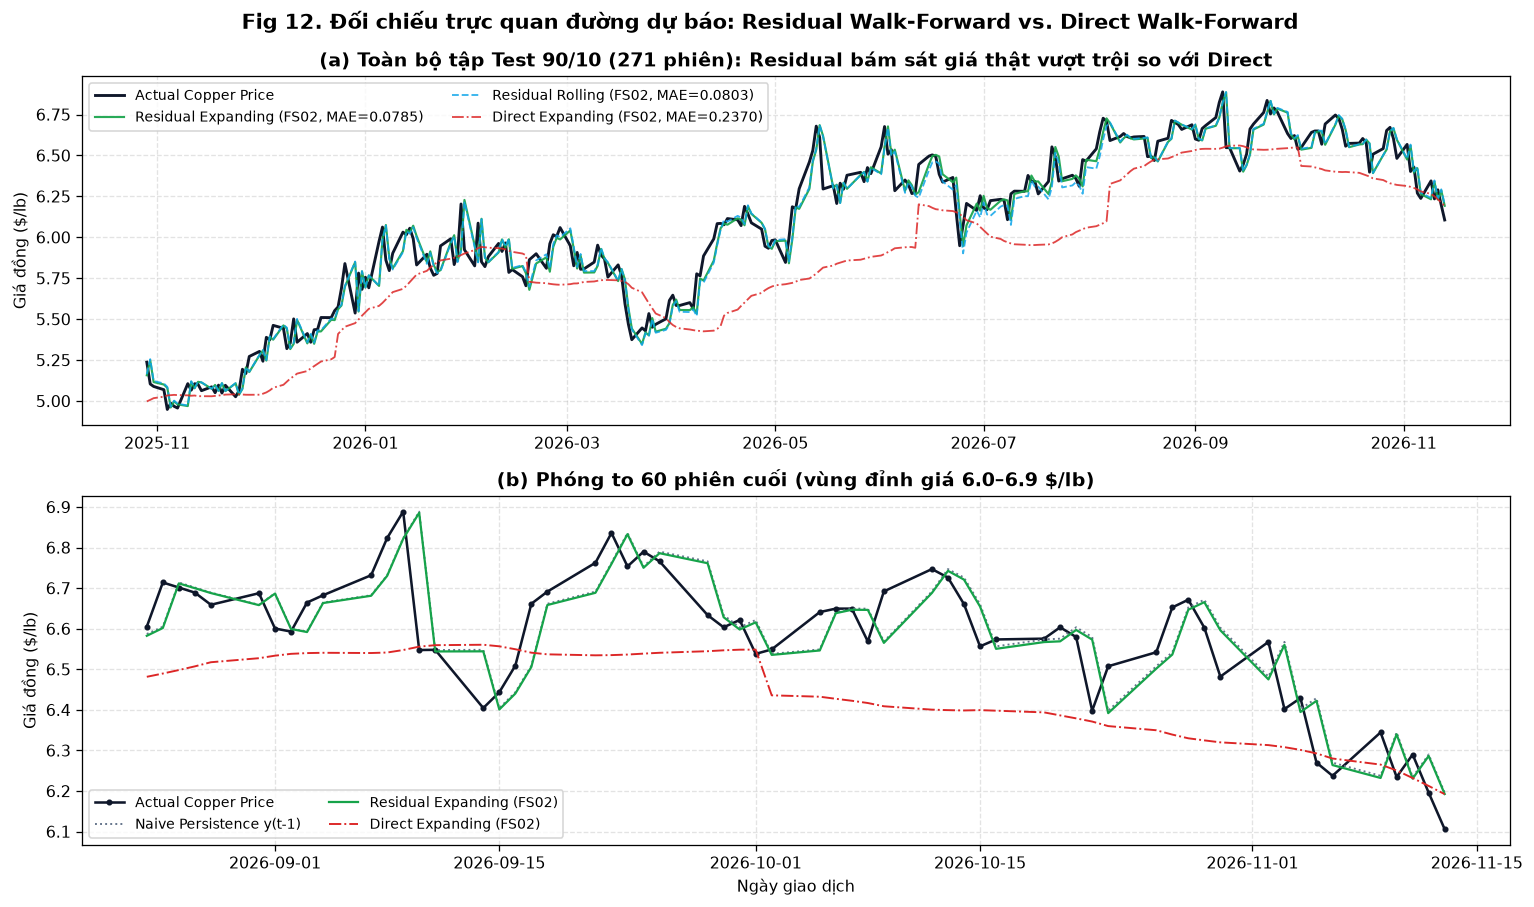

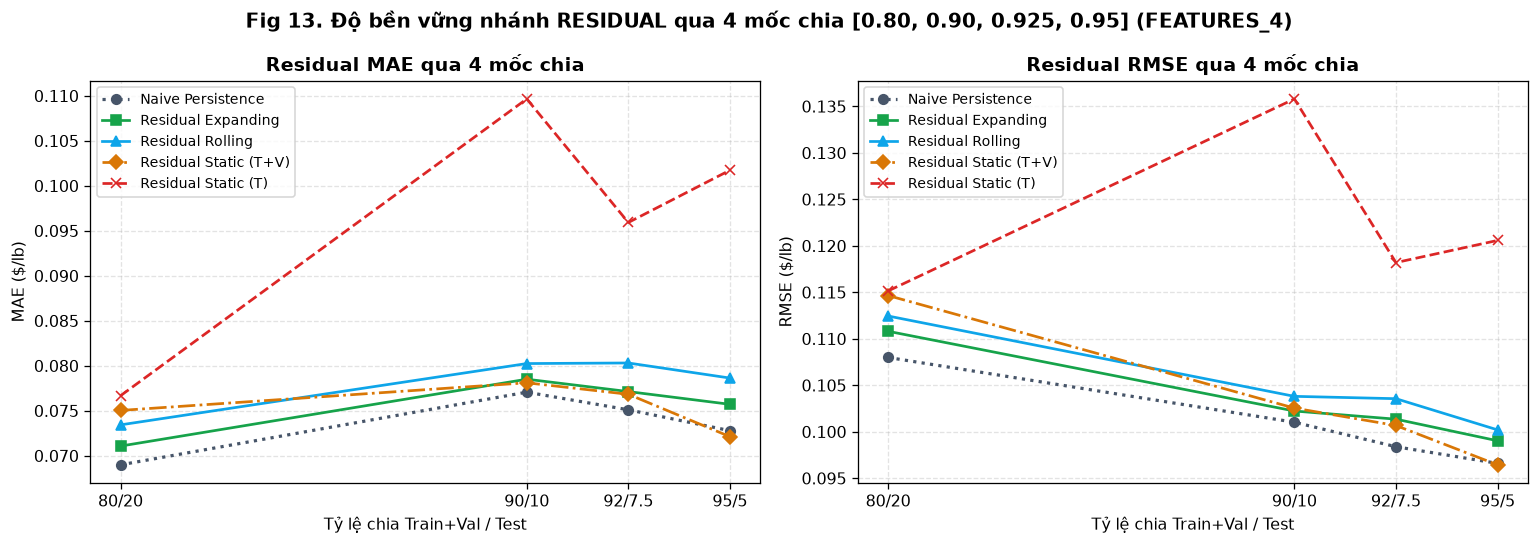

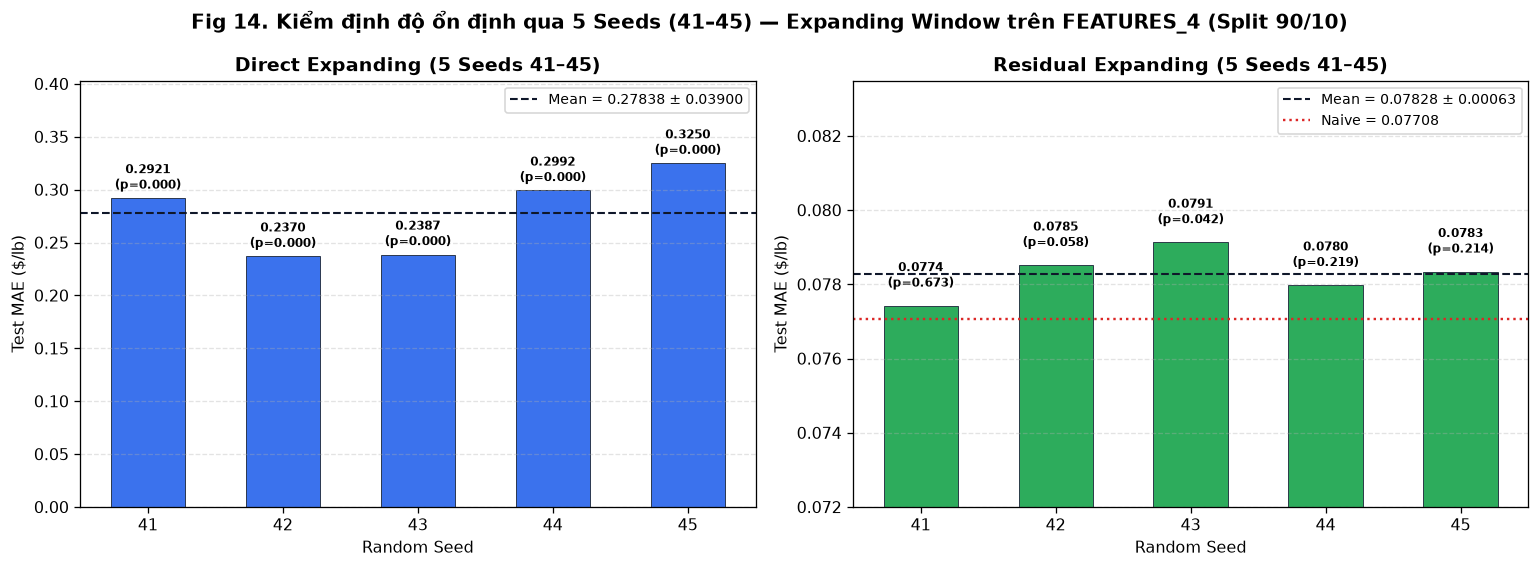

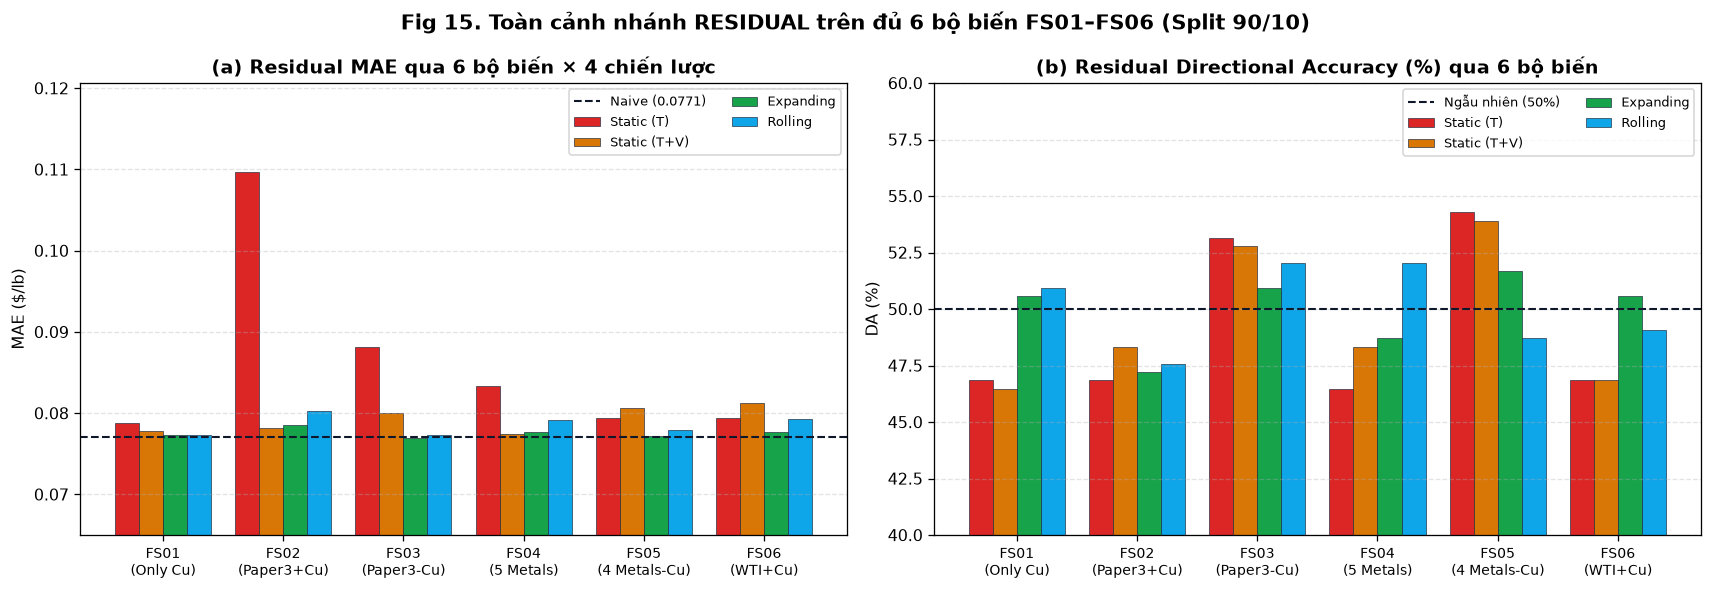

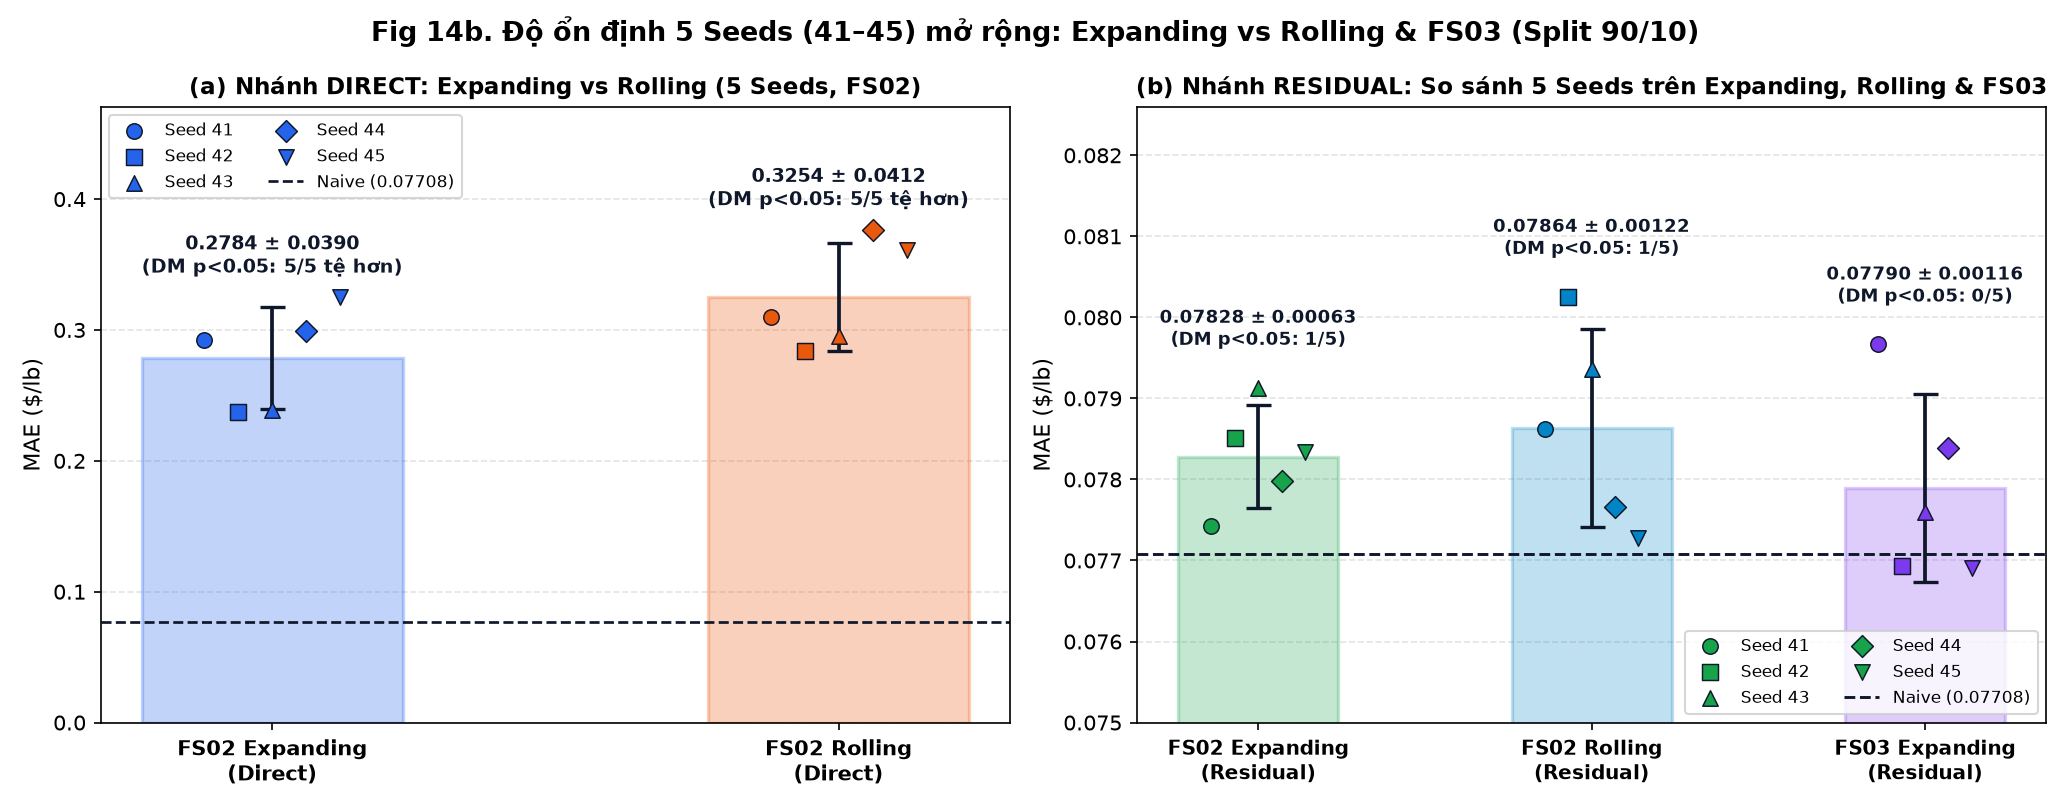

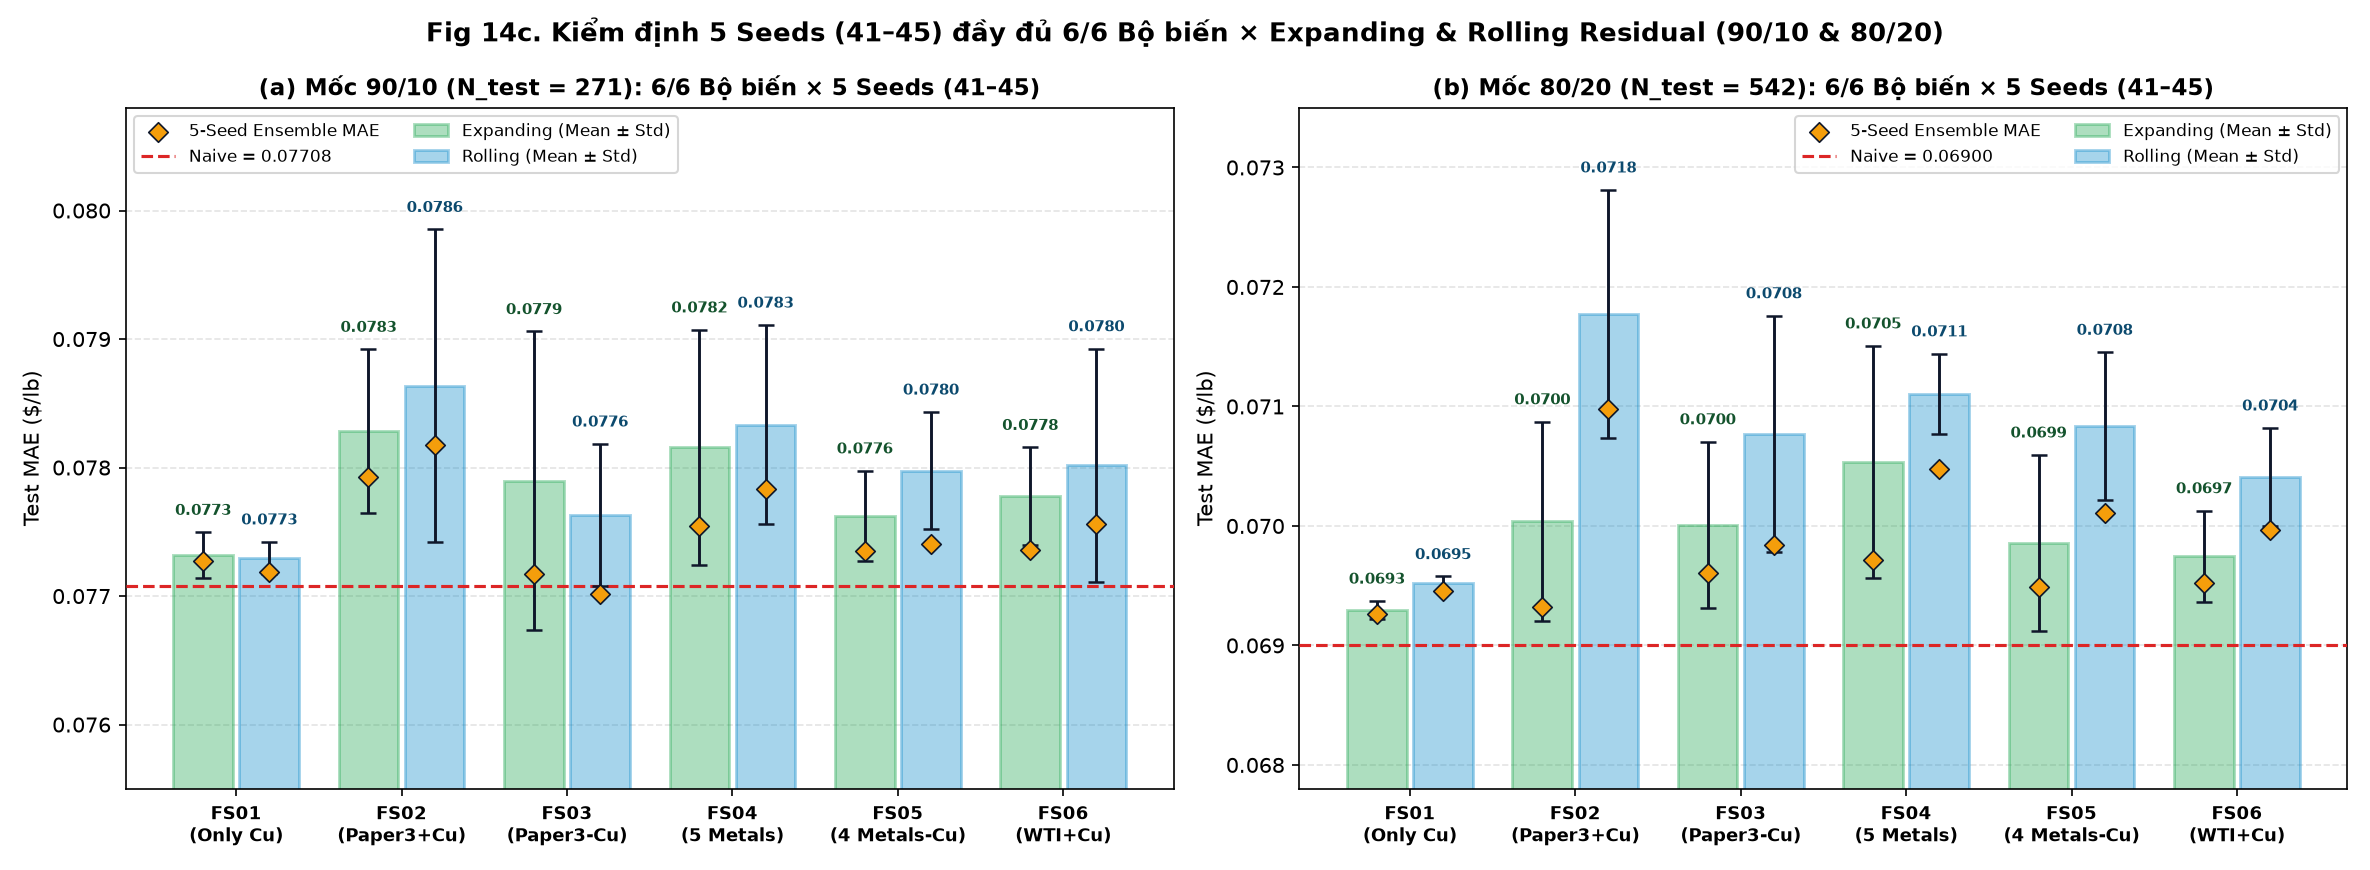

In [19]:
# === MỤC 7.2: BIỂU ĐỒ TỔNG HỢP CHUYÊN SÂU (FIG 12 -> FIG 15) ===
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE_DIR = OUT_DIR if ("OUT_DIR" in globals() and (Path(OUT_DIR) / "phase2_main_test_results.csv").exists()) else Path("result")
MET_DIR = (BASE_DIR / "metrics") if (BASE_DIR / "metrics").exists() else BASE_DIR
PRED_DIR = (BASE_DIR / "predictions") if (BASE_DIR / "predictions").exists() else BASE_DIR
PLOT_DIR = (BASE_DIR / "figures") if (BASE_DIR / "figures").exists() else BASE_DIR

_main_df = pd.read_csv(MET_DIR / "phase2_main_test_results.csv")
_cr_df = pd.read_csv(MET_DIR / "phase2_cross_ratio_results.csv")
_ms_df = pd.read_csv(MET_DIR / "phase2b_multiseed_stability.csv")
_naive_mae = float(_main_df[_main_df["strategy"] == "naive_persistence"].iloc[0]["MAE"])

# --- FIG 12 ---
_df_res_exp = pd.read_csv(PRED_DIR / "pred_RESIDUAL__FEATURES_4__expanding_window.csv")
_df_res_roll = pd.read_csv(PRED_DIR / "pred_RESIDUAL__FEATURES_4__rolling_window.csv")
_df_dir_exp = pd.read_csv(PRED_DIR / "pred_FEATURES_4__expanding_window.csv")
_dates = pd.to_datetime(_df_res_exp["Date"])

fig, axes = plt.subplots(2, 1, figsize=(13.5, 8.0))
ax = axes[0]
ax.plot(_dates, _df_res_exp["actual"], color="#0F172A", linewidth=1.8, label="Actual Copper Price")
ax.plot(_dates, _df_res_exp["predicted"], color="#16A34A", linewidth=1.35, alpha=0.92, label="Residual Expanding (FS02, MAE=0.0785)")
ax.plot(_dates, _df_res_roll["predicted"], color="#0EA5E9", linewidth=1.15, linestyle="--", alpha=0.85, label="Residual Rolling (FS02, MAE=0.0803)")
ax.plot(_dates, _df_dir_exp["predicted"], color="#DC2626", linewidth=1.15, linestyle="-.", alpha=0.85, label="Direct Expanding (FS02, MAE=0.2370)")
ax.set_title("(a) Toàn bộ tập Test 90/10 (271 phiên): Residual bám sát giá thật vượt trội so với Direct", fontweight="bold")
ax.set_ylabel("Giá đồng ($/lb)")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", ncol=2, fontsize=9)

ax2 = axes[1]
_sl = slice(-60, None)
ax2.plot(_dates.iloc[_sl], _df_res_exp["actual"].iloc[_sl], color="#0F172A", marker="o", markersize=2.8, linewidth=1.6, label="Actual Copper Price")
ax2.plot(_dates.iloc[_sl], _df_res_exp["prev_actual"].iloc[_sl], color="#64748B", linestyle=":", linewidth=1.2, label="Naive Persistence y(t-1)")
ax2.plot(_dates.iloc[_sl], _df_res_exp["predicted"].iloc[_sl], color="#16A34A", linewidth=1.4, label="Residual Expanding (FS02)")
ax2.plot(_dates.iloc[_sl], _df_dir_exp["predicted"].iloc[_sl], color="#DC2626", linestyle="-.", linewidth=1.2, label="Direct Expanding (FS02)")
ax2.set_title("(b) Phóng to 60 phiên cuối (vùng đỉnh giá 6.0–6.9 $/lb)", fontweight="bold")
ax2.set_ylabel("Giá đồng ($/lb)")
ax2.set_xlabel("Ngày giao dịch")
ax2.grid(True, linestyle="--", alpha=0.35)
ax2.legend(loc="lower left", ncol=2, fontsize=9)
fig.suptitle("Fig 12. Đối chiếu trực quan đường dự báo: Residual Walk-Forward vs. Direct Walk-Forward", fontsize=13, fontweight="bold")
plt.tight_layout()
fig.savefig(PLOT_DIR / "fig12_residual_vs_direct_actual_pred.png", dpi=150)
plt.show()

# --- FIG 13 ---
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
_ratios = sorted(_cr_df["ratio"].unique())
_cr_naive = _cr_df[(_cr_df["target_mode"] == "direct") & (_cr_df["strategy"] == "naive_persistence")].sort_values("ratio")
_res_styles = [
    ("expanding_window", "Residual Expanding", "#16A34A", "s", "-"),
    ("rolling_window", "Residual Rolling", "#0EA5E9", "^", "-"),
    ("static_train_val", "Residual Static (T+V)", "#D97706", "D", "-."),
    ("static_train_only", "Residual Static (T)", "#DC2626", "x", "--"),
]
for ax_i, (col_m, ttl, yl) in enumerate([("MAE", "Residual MAE qua 4 mốc chia", "MAE ($/lb)"), ("RMSE", "Residual RMSE qua 4 mốc chia", "RMSE ($/lb)")]):
    axes[ax_i].plot(_cr_naive["ratio"], _cr_naive[col_m], color="#475569", marker="o", linestyle=":", linewidth=2.0, label="Naive Persistence")
    for strat, lbl, col, mk, ls in _res_styles:
        sub = _cr_df[(_cr_df["target_mode"] == "residual") & (_cr_df["strategy"] == strat)].sort_values("ratio")
        axes[ax_i].plot(sub["ratio"], sub[col_m], color=col, marker=mk, linestyle=ls, linewidth=1.7, label=lbl)
    axes[ax_i].set_xticks(_ratios)
    axes[ax_i].set_xticklabels([f"{int(r*100)}/{round((1-r)*100, 1):g}" for r in _ratios])
    axes[ax_i].set_title(ttl, fontweight="bold")
    axes[ax_i].set_xlabel("Tỷ lệ chia Train+Val / Test")
    axes[ax_i].set_ylabel(yl)
    axes[ax_i].grid(True, linestyle="--", alpha=0.35)
    axes[ax_i].legend(loc="best", fontsize=8.5)
fig.suptitle("Fig 13. Độ bền vững nhánh RESIDUAL qua 4 mốc chia [0.80, 0.90, 0.925, 0.95] (FEATURES_4)", fontsize=12.5, fontweight="bold")
plt.tight_layout()
fig.savefig(PLOT_DIR / "fig13_cross_ratio_residual_4_splits.png", dpi=150)
plt.show()

# --- FIG 14 ---
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))
for ax_i, (t_mode, col, ttl) in enumerate([("direct", "#2563EB", "Direct Expanding (5 Seeds 41–45)"), ("residual", "#16A34A", "Residual Expanding (5 Seeds 41–45)")]):
    sub = _ms_df[_ms_df["target_mode"] == t_mode].sort_values("seed")
    seeds = sub["seed"].astype(int).astype(str)
    vals = sub["MAE"].to_numpy()
    mean_v, std_v = float(np.mean(vals)), float(np.std(vals, ddof=1))
    bars = axes[ax_i].bar(seeds, vals, color=col, width=0.55, edgecolor="#1E293B", linewidth=0.6, alpha=0.9)
    axes[ax_i].axhline(mean_v, color="#0F172A", linestyle="--", linewidth=1.3, label=f"Mean = {mean_v:.5f} ± {std_v:.5f}")
    if t_mode == "residual":
        axes[ax_i].axhline(_naive_mae, color="#DC2626", linestyle=":", linewidth=1.5, label=f"Naive = {_naive_mae:.5f}")
        axes[ax_i].set_ylim(0.072, max(vals.max(), _naive_mae) * 1.055)
        y_off = 0.0004
    else:
        axes[ax_i].set_ylim(0, vals.max() * 1.24)
        y_off = vals.max() * 0.015
    axes[ax_i].set_title(ttl, fontweight="bold")
    axes[ax_i].set_xlabel("Random Seed")
    axes[ax_i].set_ylabel("Test MAE ($/lb)")
    axes[ax_i].grid(axis="y", linestyle="--", alpha=0.35)
    axes[ax_i].legend(loc="upper right", fontsize=8.5)
    for b, p_v in zip(bars, sub["DM_L1_p_value"]):
        axes[ax_i].text(b.get_x() + b.get_width()/2, b.get_height() + y_off, f"{b.get_height():.4f}\n(p={p_v:.3f})", ha="center", va="bottom", fontsize=7.8, fontweight="bold")
fig.suptitle("Fig 14. Kiểm định độ ổn định qua 5 Seeds (41–45) — Expanding Window trên FEATURES_4 (Split 90/10)", fontsize=12.5, fontweight="bold")
plt.tight_layout()
fig.savefig(PLOT_DIR / "fig14_multiseed_stability_5seeds.png", dpi=150)
plt.show()

# --- FIG 15 ---
fig, axes = plt.subplots(1, 2, figsize=(15.0, 5.2))
_f_order = ["FS01_CU", "FEATURES_4", "FEATURES_3", "FS04_METALS_CU", "FS05_METALS_EXO", "FS06_WTI_CU"]
_f_labels = ["FS01\n(Only Cu)", "FS02\n(Paper3+Cu)", "FS03\n(Paper3-Cu)", "FS04\n(5 Metals)", "FS05\n(4 Metals-Cu)", "FS06\n(WTI+Cu)"]
_s_order = ["static_train_only", "static_train_val", "expanding_window", "rolling_window"]
_s_labels = ["Static (T)", "Static (T+V)", "Expanding", "Rolling"]
_s_colors = ["#DC2626", "#D97706", "#16A34A", "#0EA5E9"]

_res_only = _main_df[_main_df["target_mode"] == "residual"]
_x = np.arange(len(_f_order))
_w = 0.20

for ax_i, (m_col, ref_val, ref_lbl, ttl, yl) in enumerate([
    ("MAE", _naive_mae, f"Naive ({_naive_mae:.4f})", "(a) Residual MAE qua 6 bộ biến × 4 chiến lược", "MAE ($/lb)"),
    ("DA_pct", 50.0, "Ngẫu nhiên (50%)", "(b) Residual Directional Accuracy (%) qua 6 bộ biến", "DA (%)"),
]):
    for j, (st, slbl, col) in enumerate(zip(_s_order, _s_labels, _s_colors)):
        sub = _res_only[_res_only["strategy"] == st].set_index("feature_set").reindex(_f_order)
        axes[ax_i].bar(_x + (j - 1.5) * _w, sub[m_col], width=_w, color=col, label=slbl, edgecolor="#1E293B", linewidth=0.4)
    axes[ax_i].axhline(ref_val, color="#0F172A", linestyle="--", linewidth=1.3, label=ref_lbl)
    axes[ax_i].set_xticks(_x)
    axes[ax_i].set_xticklabels(_f_labels, fontsize=8.5)
    axes[ax_i].set_title(ttl, fontweight="bold")
    axes[ax_i].set_ylabel(yl)
    if m_col == "MAE":
        axes[ax_i].set_ylim(0.065, float(_res_only["MAE"].max()) * 1.10)
    else:
        axes[ax_i].set_ylim(40, 60)
    axes[ax_i].grid(axis="y", linestyle="--", alpha=0.35)
    axes[ax_i].legend(loc="upper right", fontsize=8.0, ncol=2)

fig.suptitle("Fig 15. Toàn cảnh nhánh RESIDUAL trên đủ 6 bộ biến FS01–FS06 (Split 90/10)", fontsize=13, fontweight="bold")
plt.tight_layout()
fig.savefig(PLOT_DIR / "fig15_6features_residual_comparison.png", dpi=150)
plt.show()
# --- FIG 14b ---
if (MET_DIR / "phase2c_multiseed_extended.csv").exists():
    _df_2c = pd.read_csv(MET_DIR / "phase2c_multiseed_extended.csv")
    _df_2b_ext = _ms_df.assign(feature_set="FEATURES_4", strategy="expanding_window")
    _df_ms_all = pd.concat([_df_2b_ext, _df_2c], ignore_index=True)

    fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.4))
    _seed_mk = {41: "o", 42: "s", 43: "^", 44: "D", 45: "v"}

    ax = axes[0]
    _dir_cfgs = [
        ("FEATURES_4", "expanding_window", "FS02 Expanding\n(Direct)", "#2563EB"),
        ("FEATURES_4", "rolling_window", "FS02 Rolling\n(Direct)", "#EA580C"),
    ]
    for i, (fs, st, lbl, col) in enumerate(_dir_cfgs):
        sub = _df_ms_all[(_df_ms_all["feature_set"] == fs) & (_df_ms_all["strategy"] == st) & (_df_ms_all["target_mode"] == "direct")].sort_values("seed")
        mean_v, std_v = sub["MAE"].mean(), sub["MAE"].std()
        ax.bar(i, mean_v, width=0.46, color=col, alpha=0.28, edgecolor=col, linewidth=1.6, zorder=2)
        ax.errorbar(i, mean_v, yerr=std_v, fmt="none", ecolor="#0F172A", elinewidth=1.8, capsize=6, capthick=1.6, zorder=4)
        for off, (_, r) in zip(np.linspace(-0.12, 0.12, len(sub)), sub.iterrows()):
            s_id = int(r["seed"])
            ax.scatter(i + off, r["MAE"], marker=_seed_mk[s_id], s=55, color=col, edgecolor="#0F172A", linewidth=0.7, zorder=5,
                       label=f"Seed {s_id}" if i == 0 else None)
        ax.text(i, max(sub["MAE"].max(), mean_v + std_v) + 0.014, f"{mean_v:.4f} ± {std_v:.4f}\n(DM p<0.05: 5/5 tệ hơn)",
                ha="center", va="bottom", fontsize=9.0, fontweight="bold", color="#0F172A")
    ax.axhline(_naive_mae, color="#0F172A", linestyle="--", linewidth=1.3, label=f"Naive ({_naive_mae:.5f})")
    ax.set_xticks(np.arange(len(_dir_cfgs)))
    ax.set_xticklabels([c[2] for c in _dir_cfgs], fontsize=10, fontweight="bold")
    ax.set_ylabel("MAE ($/lb)", fontsize=10.5)
    ax.set_ylim(0.0, float(_df_ms_all[_df_ms_all["target_mode"] == "direct"]["MAE"].max()) * 1.25)
    ax.set_title("(a) Nhánh DIRECT: Expanding vs Rolling (5 Seeds, FS02)", fontsize=11, fontweight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.legend(loc="upper left", fontsize=8.3, ncol=2, frameon=True)

    ax = axes[1]
    _res_cfgs = [
        ("FEATURES_4", "expanding_window", "FS02 Expanding\n(Residual)", "#16A34A"),
        ("FEATURES_4", "rolling_window", "FS02 Rolling\n(Residual)", "#0284C7"),
        ("FEATURES_3", "expanding_window", "FS03 Expanding\n(Residual)", "#7C3AED"),
    ]
    for i, (fs, st, lbl, col) in enumerate(_res_cfgs):
        sub = _df_ms_all[(_df_ms_all["feature_set"] == fs) & (_df_ms_all["strategy"] == st) & (_df_ms_all["target_mode"] == "residual")].sort_values("seed")
        mean_v, std_v = sub["MAE"].mean(), sub["MAE"].std()
        n_sig = int((sub["DM_L1_p_value"] < 0.05).sum())
        ax.bar(i, mean_v, width=0.48, color=col, alpha=0.25, edgecolor=col, linewidth=1.6, zorder=2)
        ax.errorbar(i, mean_v, yerr=std_v, fmt="none", ecolor="#0F172A", elinewidth=1.8, capsize=6, capthick=1.6, zorder=4)
        for off, (_, r) in zip(np.linspace(-0.14, 0.14, len(sub)), sub.iterrows()):
            s_id = int(r["seed"])
            ax.scatter(i + off, r["MAE"], marker=_seed_mk[s_id], s=55, color=col, edgecolor="#0F172A", linewidth=0.7, zorder=5,
                       label=f"Seed {s_id}" if i == 0 else None)
        ax.text(i, max(sub["MAE"].max(), mean_v + std_v) + 0.00045, f"{mean_v:.5f} ± {std_v:.5f}\n(DM p<0.05: {n_sig}/5)",
                ha="center", va="bottom", fontsize=8.8, fontweight="bold", color="#0F172A")
    ax.axhline(_naive_mae, color="#0F172A", linestyle="--", linewidth=1.4, label=f"Naive ({_naive_mae:.5f})")
    ax.set_xticks(np.arange(len(_res_cfgs)))
    ax.set_xticklabels([c[2] for c in _res_cfgs], fontsize=9.8, fontweight="bold")
    ax.set_ylabel("MAE ($/lb)", fontsize=10.5)
    ax.set_ylim(0.0750, 0.0826)
    ax.set_title("(b) Nhánh RESIDUAL: So sánh 5 Seeds trên Expanding, Rolling & FS03", fontsize=11, fontweight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.legend(loc="lower right", fontsize=8.3, ncol=2, frameon=True)

    fig.suptitle("Fig 14b. Độ ổn định 5 Seeds (41–45) mở rộng: Expanding vs Rolling & FS03 (Split 90/10)", fontsize=12.8, fontweight="bold")
    plt.tight_layout()
    fig.savefig(PLOT_DIR / "fig14b_multiseed_extended_comparison.png", dpi=150)
    plt.show()
# --- FIG 14c ---
if (MET_DIR / "phase2d_full_6fs_multiseed_summary.csv").exists():
    _s_2d = pd.read_csv(MET_DIR / "phase2d_full_6fs_multiseed_summary.csv")
    _fs_ord = ["FS01_CU", "FEATURES_4", "FEATURES_3", "FS04_METALS_CU", "FS05_METALS_EXO", "FS06_WTI_CU"]
    _fs_lbl = ["FS01\n(Only Cu)", "FS02\n(Paper3+Cu)", "FS03\n(Paper3-Cu)", "FS04\n(5 Metals)", "FS05\n(4 Metals-Cu)", "FS06\n(WTI+Cu)"]
    fig, axes = plt.subplots(1, 2, figsize=(15.8, 5.8))
    _x = np.arange(len(_fs_ord))
    for ax_i, (r_val, ttl_s, ylims) in enumerate([
        (0.90, "(a) Mốc 90/10 (N_test = 271): 6/6 Bộ biến × 5 Seeds (41–45)", (0.0755, 0.0808)),
        (0.80, "(b) Mốc 80/20 (N_test = 542): 6/6 Bộ biến × 5 Seeds (41–45)", (0.0678, 0.0735)),
    ]):
        ax = axes[ax_i]
        sub_r = _s_2d[np.isclose(_s_2d["ratio"], r_val)]
        naive_v = float(sub_r["naive_MAE"].iloc[0])
        for j, (st, slbl, col, scol) in enumerate([
            ("expanding_window", "Expanding (Mean ± Std)", "#16A34A", "#14532D"),
            ("rolling_window", "Rolling (Mean ± Std)", "#0284C7", "#0C4A6E"),
        ]):
            sub = sub_r[sub_r["strategy"] == st].set_index("feature_set").reindex(_fs_ord)
            means, stds, ens = sub["MAE_mean"].to_numpy(), sub["MAE_std"].to_numpy(), sub["Ensemble_5seed_MAE"].to_numpy()
            xpos = _x + (-0.20 if j == 0 else 0.20)
            ax.bar(xpos, means, width=0.36, color=col, alpha=0.35, edgecolor=col, linewidth=1.4, label=slbl, zorder=2)
            ax.errorbar(xpos, means, yerr=stds, fmt="none", ecolor="#0F172A", elinewidth=1.4, capsize=4, capthick=1.2, zorder=4)
            ax.scatter(xpos, ens, marker="D", s=44, color="#F59E0B", edgecolor="#0F172A", linewidth=0.8, zorder=5,
                       label="5-Seed Ensemble MAE" if j == 0 else None)
            for xi, mv, sv in zip(xpos, means, stds):
                ax.text(xi, mv + sv + (ylims[1] - ylims[0]) * 0.020, f"{mv:.4f}", ha="center", va="bottom", fontsize=7.4, fontweight="bold", color=scol)
        ax.axhline(naive_v, color="#DC2626", linestyle="--", linewidth=1.5, label=f"Naive = {naive_v:.5f}", zorder=3)
        ax.set_xticks(_x)
        ax.set_xticklabels(_fs_lbl, fontsize=8.8, fontweight="bold")
        ax.set_ylabel("Test MAE ($/lb)", fontsize=10.2)
        ax.set_ylim(*ylims)
        ax.set_title(ttl_s, fontsize=10.8, fontweight="bold")
        ax.grid(axis="y", linestyle="--", alpha=0.35)
        ax.legend(loc="upper left" if ax_i == 0 else "upper right", fontsize=8.2, ncol=2, frameon=True)
    fig.suptitle("Fig 14c. Kiểm định 5 Seeds (41–45) đầy đủ 6/6 Bộ biến × Expanding & Rolling Residual (90/10 & 80/20)", fontsize=12.6, fontweight="bold")
    plt.tight_layout()
    fig.savefig(PLOT_DIR / "fig14c_full_6fs_multiseed_90_80.png", dpi=150)
    plt.show()


## 8. Báo cáo tổng kết tự động & Kiểm kê tệp đầu ra

Toàn bộ kết quả đã được sắp xếp gọn trong `quan task/result/`:
- **Bảng chỉ số (`result/metrics/`):** `14` tệp CSV (`benchmark_complete_metrics.csv`, `phase1_validation_screening.csv`, `phase2_cross_ratio_results.csv`, `phase2b_multiseed_stability.csv`, `phase2c_multiseed_extended*.csv`, `phase2d_full_6fs_multiseed_{metrics,summary}.csv`, `phase3_ablation_study.csv`, `phase4_regime_extended_metrics.csv`, `phase5_diebold_mariano_tests.csv`, ...).
- **Dự báo theo ngày test (`result/predictions/`):** `51` tệp CSV (`49` tệp `pred_*.csv` tại `90/10` + `phase2d_full_6fs_multiseed_predictions_{90,80}.csv` cho 120 lượt 5-seed).
- **Biểu đồ (`result/figures/`):** `17` biểu đồ tổng hợp (`fig1` → `fig15`, `fig14b`, `fig14c`) và `24` biểu đồ chi tiết theo 6 bộ biến trong `result/figures/per_feature_set/FS01/` → `FS06/`.
- **Báo cáo Markdown tự động:** `result/rolling_expanding_summary_report.md`.

In [12]:
def generate_summary_report(out_dir: Path):
    f4_dir = main_test_df[(main_test_df["target_mode"] == "direct") & (main_test_df["feature_set"] == "FEATURES_4")].set_index("strategy")
    lines = [
        "# Báo cáo thực nghiệm Phương pháp 4 (Full Parity): Rolling & Expanding Window Forecasting",
        "",
        f"- **Chế độ chạy:** `{MODE}` | **Dữ liệu:** {len(data)} phiên ({data.index.min().date()} -> {data.index.max().date()})",
        f"- **Tỷ lệ chia:** `{RATIOS}` (Chính: `PRIMARY_RATIO = {PRIMARY_RATIO}`)",
        f"- **Chính sách Walk-Forward chọn từ Validation:** `W* = {BEST_W}`, `S* = {BEST_S}`, `update_mode* = {BEST_UPDATE_MODE}`",
        f"- **Kiến trúc chuẩn số đông (`PAPER_CONFIG`):** 2-layer LSTM ({ACTIVE_HP}), Lookback = {LOOKBACK}, Horizon = {HORIZON}",
        "",
        "## 1. Bảng chỉ số chính trên tập Test (FEATURES_4 Direct vs. Residual)",
        "",
        "| Mode | Bộ biến | Chiến lược | MAE ($/lb) | RMSE ($/lb) | MAPE (%) | MASE | R² | DA (%) | ΔMAE vs Naive |",
        "|---|---|---|---:|---:|---:|---:|---:|---:|---:|",
    ]
    for _, r in main_test_df.iterrows():
        da_str = "—" if pd.isna(r["DA_pct"]) else f"{r['DA_pct']:.2f}%"
        lines.append(
            f"| {r['target_mode']} | {r['feature_set']} | {r['strategy']} | {r['MAE']:.4f} | {r['RMSE']:.4f} | "
            f"{r['MAPE_pct']:.2f}% | {r['MASE']:.4f} | {r['R2']:.4f} | {da_str} | {r['Delta_MAE_vs_Naive_pct']:+.2f}% |"
        )

    if len(multiseed_rows) > 0:
        lines += [
            "",
            f"## 2. Độ ổn định qua 5 Seeds ({SEEDS_MULTI}, Expanding Window, FEATURES_4)",
            "",
            "| Mode | Seed | MAE | RMSE | DA (%) | ΔMAE vs Naive | DM(L1) p-value |",
            "|---|---:|---:|---:|---:|---:|---:|",
        ]
        for _, r in multiseed_df.iterrows():
            lines.append(
                f"| {r['target_mode']} | {int(r['seed'])} | {r['MAE']:.5f} | {r['RMSE']:.5f} | {r['DA_pct']:.2f}% | {r['Delta_MAE_vs_Naive_pct']:+.2f}% | {r['DM_L1_p_value']:.4f} |"
            )

    if (out_dir / "phase2c_multiseed_extended.csv").exists():
        ext_df = pd.read_csv(out_dir / "phase2c_multiseed_extended.csv")
        ext_sum = pd.read_csv(out_dir / "phase2c_multiseed_extended_summary.csv")
        lines += [
            "",
            f"## 2B. Độ ổn định qua 5 Seeds mở rộng ({SEEDS_MULTI}, Rolling FS02 & Expanding FS03, Phase 2C)",
            "",
            "| Bộ biến | Chiến lược | Mode | Seed | MAE | RMSE | DA (%) | ΔMAE vs Naive | DM(L1) p-value |",
            "|---|---|---|---:|---:|---:|---:|---:|---:|",
        ]
        for _, r in ext_df.iterrows():
            lines.append(
                f"| {r['feature_set']} | {r['strategy']} | {r['target_mode']} | {int(r['seed'])} | "
                f"{r['MAE']:.5f} | {r['RMSE']:.5f} | {r['DA_pct']:.2f}% | {r['Delta_MAE_vs_Naive_pct']:+.2f}% | {r['DM_L1_p_value']:.4f} |"
            )
        lines += [
            "",
            "### Tổng hợp Mean ± Std qua 5 Seeds (5 cấu hình Phase 2B + 2C)",
            "",
            "| Bộ biến | Chiến lược | Mode | Mean MAE ± Std | Mean RMSE | Mean DA (%) | Mean ΔMAE vs Naive | Số seed DM p<0.05 |",
            "|---|---|---|---:|---:|---:|---:|---:|",
        ]
        for _, r in ext_sum.iterrows():
            lines.append(
                f"| {r['feature_set']} | {r['strategy']} | {r['target_mode']} | {r['MAE_mean']:.5f} ± {r['MAE_std']:.5f} | "
                f"{r['RMSE_mean']:.5f} | {r['DA_mean']:.2f}% | {r['DeltaMAE_vs_Naive_mean_pct']:+.2f}% | {int(r['seeds_DM_p_lt_005'])}/5 |"
            )

    _p2d_f = (out_dir / "metrics" / "phase2d_full_6fs_multiseed_summary.csv") if (out_dir / "metrics" / "phase2d_full_6fs_multiseed_summary.csv").exists() else (out_dir / "phase2d_full_6fs_multiseed_summary.csv")
    if _p2d_f.exists():
        p2d_sum = pd.read_csv(_p2d_f)
        lines += [
            "",
            "## 2C. Ma trận Walk-Forward 5 Seeds đầy đủ 6/6 Bộ biến (90/10 & 80/20, Phase 2D — 120 lượt)",
            "",
            "| Mốc | Bộ biến | Chiến lược | Naive MAE | Mean MAE ± Std | Ensemble 5-Seed MAE | Ensemble vs Naive | Ensemble DM p | Số seed thắng DM 5% |",
            "|---:|---|---|---:|---:|---:|---:|---:|---:|",
        ]
        for _, r in p2d_sum.iterrows():
            lines.append(
                f"| {r['ratio']:.2f} | {r['feature_set']} | {r['strategy']} | {r['naive_MAE']:.5f} | "
                f"{r['MAE_mean']:.5f} ± {r['MAE_std']:.5f} | {r['Ensemble_5seed_MAE']:.5f} | "
                f"{r['Ensemble_vs_Naive_pct']:+.2f}% | {r['Ensemble_DM_HAC_p']:.4f} | {int(r['seeds_DM_win_5pct'])}/5 |"
            )

    if CFG["run_cross_ratio"] and len(cross_ratio_rows) > 0:
        lines += [
            "",
            f"## 3. Độ bền vững qua 4 mốc chia thời gian {RATIOS} (FEATURES_4)",
            "",
            "| Mode | Ratio | n_test | Chiến lược | MAE ($/lb) | RMSE ($/lb) | R² | DA (%) |",
            "|---|---|---:|---|---:|---:|---:|---:|",
        ]
        for _, row in cross_ratio_df.iterrows():
            da_str = "—" if pd.isna(row["DA_pct"]) else f"{row['DA_pct']:.2f}%"
            lines.append(
                f"| {row['target_mode']} | {row['ratio']:.3f} | {int(row['n_test'])} | {row['strategy']} | "
                f"{row['MAE']:.4f} | {row['RMSE']:.4f} | {row['R2']:.4f} | {da_str} |"
            )

    lines += [
        "",
        "## 4. Kiểm định ý nghĩa thống kê Diebold-Mariano (DM Test - HLN 1997)",
        "",
        "| So sánh | Loss | DM Stat | p-value | Có ý nghĩa (5%) |",
        "|---|---|---:|---:|:---:|",
    ]
    for _, row in dm_df.iterrows():
        sig = "Có" if row["significant_5pct"] else "Không"
        lines.append(f"| {row['comparison']} | {row['loss']} | {row['DM_stat']:.3f} | {row['p_value']:.4f} | {sig} |")

    report_text = "\n".join(lines)
    (out_dir / "rolling_expanding_summary_report.md").write_text(report_text, encoding="utf-8")
    return report_text

report_md = generate_summary_report(OUT_DIR)
display(Markdown(report_md))
print(f"\nHoàn tất toàn bộ Full Parity Edition! Lưu tại: {OUT_DIR}")

import shutil
zip_base = str(OUT_DIR.parent / f"{OUT_DIR.parent.name}_{OUT_DIR.name}_results")
zip_path = shutil.make_archive(zip_base, "zip", root_dir=OUT_DIR)
print(f"Đã nén toàn bộ kết quả thành 1 file duy nhất để dễ tải: {zip_path}")


# Báo cáo thực nghiệm Phương pháp 4 (Full Parity): Rolling & Expanding Window Forecasting

- **Chế độ chạy:** `FULL_RESEARCH_MODE` | **Dữ liệu:** 2710 phiên (2016-01-13 -> 2026-11-13)
- **Tỷ lệ chia:** `[0.8, 0.9, 0.925, 0.95]` (Chính: `PRIMARY_RATIO = 0.9`)
- **Chính sách Walk-Forward chọn từ Validation:** `W* = 756`, `S* = 40`, `update_mode* = cold_start`
- **Kiến trúc chuẩn số đông (`PAPER_CONFIG`):** 2-layer LSTM ({'lstm_units_1': 39, 'lstm_units_2': 111, 'learning_rate': 5e-05}), Lookback = 22, Horizon = 1

## 1. Bảng chỉ số chính trên tập Test (FEATURES_4 Direct vs. Residual)

| Mode | Bộ biến | Chiến lược | MAE ($/lb) | RMSE ($/lb) | MAPE (%) | MASE | R² | DA (%) | ΔMAE vs Naive |
|---|---|---|---:|---:|---:|---:|---:|---:|---:|
| direct | FS01_CU | static_train_only | 0.4928 | 0.5342 | 7.94% | 14.3635 | -0.1782 | 46.84% | +539.36% |
| direct | FS01_CU | static_train_val | 0.3355 | 0.3776 | 5.40% | 9.0626 | 0.4112 | 47.58% | +335.34% |
| direct | FS01_CU | expanding_window | 0.2026 | 0.2595 | 3.38% | 5.4732 | 0.7219 | 53.90% | +162.92% |
| direct | FS01_CU | rolling_window | 0.2739 | 0.3337 | 4.56% | 7.3987 | 0.5402 | 50.56% | +255.42% |
| direct | FEATURES_4 | naive_persistence | 0.0771 | 0.1010 | 1.28% | 2.0817 | 0.9579 | — | +0.00% |
| direct | FEATURES_4 | static_train_only | 1.5516 | 1.6156 | 25.53% | 45.2235 | -9.7766 | 46.84% | +1913.04% |
| direct | FEATURES_4 | static_train_val | 0.2869 | 0.3308 | 4.66% | 7.7477 | 0.5481 | 48.33% | +272.18% |
| direct | FEATURES_4 | expanding_window | 0.2370 | 0.2943 | 3.84% | 6.3999 | 0.6423 | 51.30% | +207.43% |
| direct | FEATURES_4 | rolling_window | 0.2837 | 0.3404 | 4.54% | 7.6626 | 0.5215 | 47.21% | +268.09% |
| direct | FEATURES_3 | static_train_only | 0.3199 | 0.3853 | 5.29% | 9.3241 | 0.3871 | 52.79% | +315.05% |
| direct | FEATURES_3 | static_train_val | 0.3663 | 0.4842 | 6.09% | 9.8923 | 0.0318 | 55.02% | +375.20% |
| direct | FEATURES_3 | expanding_window | 0.3861 | 0.4770 | 6.22% | 10.4269 | 0.0604 | 51.30% | +400.88% |
| direct | FEATURES_3 | rolling_window | 0.4608 | 0.5522 | 7.31% | 12.4441 | -0.2592 | 48.33% | +497.78% |
| direct | FS04_METALS_CU | static_train_only | 1.3227 | 1.3893 | 21.56% | 38.5519 | -6.9697 | 46.84% | +1616.07% |
| direct | FS04_METALS_CU | static_train_val | 0.7246 | 0.7804 | 11.64% | 19.5695 | -1.5143 | 47.21% | +840.07% |
| direct | FS04_METALS_CU | expanding_window | 0.3384 | 0.3829 | 5.45% | 9.1407 | 0.3948 | 50.19% | +339.10% |
| direct | FS04_METALS_CU | rolling_window | 0.3497 | 0.3999 | 5.60% | 9.4455 | 0.3396 | 50.19% | +353.74% |
| direct | FS05_METALS_EXO | static_train_only | 0.5638 | 0.6678 | 8.91% | 16.4321 | -0.8415 | 48.70% | +631.44% |
| direct | FS05_METALS_EXO | static_train_val | 0.5762 | 0.6902 | 9.08% | 15.5630 | -0.9670 | 46.84% | +647.61% |
| direct | FS05_METALS_EXO | expanding_window | 0.3618 | 0.4315 | 5.75% | 9.7721 | 0.2312 | 48.33% | +369.43% |
| direct | FS05_METALS_EXO | rolling_window | 0.4141 | 0.4737 | 6.64% | 11.1841 | 0.0736 | 49.44% | +437.26% |
| direct | FS06_WTI_CU | static_train_only | 0.5585 | 0.6267 | 8.89% | 16.2772 | -0.6218 | 48.33% | +624.55% |
| direct | FS06_WTI_CU | static_train_val | 0.5257 | 0.5891 | 8.37% | 14.1992 | -0.4331 | 47.21% | +582.09% |
| direct | FS06_WTI_CU | expanding_window | 0.2192 | 0.2721 | 3.57% | 5.9205 | 0.6942 | 49.81% | +184.41% |
| direct | FS06_WTI_CU | rolling_window | 0.2742 | 0.3282 | 4.40% | 7.4062 | 0.5553 | 48.70% | +255.77% |
| residual | FS01_CU | static_train_only | 0.0788 | 0.1021 | 1.30% | 2.2962 | 0.9570 | 46.84% | +2.21% |
| residual | FS01_CU | static_train_val | 0.0778 | 0.1013 | 1.29% | 2.1019 | 0.9576 | 46.47% | +0.97% |
| residual | FS01_CU | expanding_window | 0.0774 | 0.1015 | 1.28% | 2.0893 | 0.9575 | 50.56% | +0.37% |
| residual | FS01_CU | rolling_window | 0.0773 | 0.1017 | 1.28% | 2.0883 | 0.9573 | 50.93% | +0.31% |
| residual | FEATURES_4 | static_train_only | 0.1097 | 0.1358 | 1.80% | 3.1964 | 0.9238 | 46.84% | +42.28% |
| residual | FEATURES_4 | static_train_val | 0.0781 | 0.1026 | 1.29% | 2.1099 | 0.9566 | 48.33% | +1.35% |
| residual | FEATURES_4 | expanding_window | 0.0785 | 0.1022 | 1.30% | 2.1206 | 0.9568 | 47.21% | +1.87% |
| residual | FEATURES_4 | rolling_window | 0.0803 | 0.1038 | 1.33% | 2.1676 | 0.9555 | 47.58% | +4.13% |
| residual | FEATURES_3 | static_train_only | 0.0882 | 0.1143 | 1.47% | 2.5707 | 0.9461 | 53.16% | +14.43% |
| residual | FEATURES_3 | static_train_val | 0.0800 | 0.1060 | 1.33% | 2.1602 | 0.9536 | 52.79% | +3.77% |
| residual | FEATURES_3 | expanding_window | 0.0769 | 0.1011 | 1.28% | 2.0777 | 0.9578 | 50.93% | -0.19% |
| residual | FEATURES_3 | rolling_window | 0.0774 | 0.1017 | 1.28% | 2.0893 | 0.9573 | 52.04% | +0.36% |
| residual | FS04_METALS_CU | static_train_only | 0.0834 | 0.1056 | 1.37% | 2.4301 | 0.9540 | 46.47% | +8.17% |
| residual | FS04_METALS_CU | static_train_val | 0.0775 | 0.1007 | 1.28% | 2.0921 | 0.9581 | 48.33% | +0.50% |
| residual | FS04_METALS_CU | expanding_window | 0.0777 | 0.1023 | 1.29% | 2.0983 | 0.9568 | 48.70% | +0.80% |
| residual | FS04_METALS_CU | rolling_window | 0.0791 | 0.1029 | 1.31% | 2.1369 | 0.9563 | 52.04% | +2.65% |
| residual | FS05_METALS_EXO | static_train_only | 0.0794 | 0.1054 | 1.32% | 2.3149 | 0.9542 | 54.28% | +3.04% |
| residual | FS05_METALS_EXO | static_train_val | 0.0806 | 0.1071 | 1.34% | 2.1773 | 0.9526 | 53.90% | +4.59% |
| residual | FS05_METALS_EXO | expanding_window | 0.0772 | 0.1015 | 1.28% | 2.0850 | 0.9574 | 51.67% | +0.16% |
| residual | FS05_METALS_EXO | rolling_window | 0.0779 | 0.1024 | 1.29% | 2.1033 | 0.9567 | 48.70% | +1.04% |
| residual | FS06_WTI_CU | static_train_only | 0.0794 | 0.1024 | 1.31% | 2.3134 | 0.9567 | 46.84% | +2.98% |
| residual | FS06_WTI_CU | static_train_val | 0.0812 | 0.1036 | 1.34% | 2.1932 | 0.9557 | 46.84% | +5.35% |
| residual | FS06_WTI_CU | expanding_window | 0.0776 | 0.1015 | 1.29% | 2.0969 | 0.9575 | 50.56% | +0.73% |
| residual | FS06_WTI_CU | rolling_window | 0.0792 | 0.1030 | 1.31% | 2.1397 | 0.9562 | 49.07% | +2.78% |

## 2. Độ ổn định qua 5 Seeds ([41, 42, 43, 44, 45], Expanding Window, FEATURES_4)

| Mode | Seed | MAE | RMSE | DA (%) | ΔMAE vs Naive | DM(L1) p-value |
|---|---:|---:|---:|---:|---:|---:|
| direct | 41 | 0.29207 | 0.35185 | 49.81% | +278.94% | 0.0000 |
| direct | 42 | 0.23696 | 0.29435 | 51.30% | +207.43% | 0.0000 |
| direct | 43 | 0.23867 | 0.28423 | 50.19% | +209.65% | 0.0000 |
| direct | 44 | 0.29922 | 0.34450 | 49.44% | +288.21% | 0.0000 |
| direct | 45 | 0.32497 | 0.37067 | 49.44% | +321.62% | 0.0000 |
| residual | 41 | 0.07742 | 0.10136 | 50.93% | +0.45% | 0.6734 |
| residual | 42 | 0.07852 | 0.10224 | 47.21% | +1.87% | 0.0583 |
| residual | 43 | 0.07913 | 0.10326 | 49.07% | +2.67% | 0.0420 |
| residual | 44 | 0.07798 | 0.10190 | 49.07% | +1.17% | 0.2185 |
| residual | 45 | 0.07834 | 0.10231 | 47.96% | +1.64% | 0.2138 |


## 2B. Độ ổn định qua 5 Seeds mở rộng ([41, 42, 43, 44, 45], Rolling FS02 & Expanding FS03, Phase 2C)

| Bộ biến | Chiến lược | Mode | Seed | MAE | RMSE | DA (%) | ΔMAE vs Naive | DM(L1) p-value |
|---|---|---|---:|---:|---:|---:|---:|---:|
| FEATURES_4 | rolling_window | direct | 41 | 0.31027 | 0.37492 | 49.07% | +302.55% | 0.0000 |
| FEATURES_4 | rolling_window | direct | 42 | 0.28371 | 0.34043 | 47.21% | +268.09% | 0.0000 |
| FEATURES_4 | rolling_window | direct | 43 | 0.29525 | 0.34960 | 46.47% | +283.05% | 0.0000 |
| FEATURES_4 | rolling_window | direct | 44 | 0.37650 | 0.43297 | 48.33% | +388.48% | 0.0000 |
| FEATURES_4 | rolling_window | direct | 45 | 0.36138 | 0.41878 | 49.81% | +368.85% | 0.0000 |
| FEATURES_4 | rolling_window | residual | 41 | 0.07862 | 0.10211 | 47.58% | +2.01% | 0.1015 |
| FEATURES_4 | rolling_window | residual | 42 | 0.08026 | 0.10382 | 47.58% | +4.13% | 0.0071 |
| FEATURES_4 | rolling_window | residual | 43 | 0.07936 | 0.10279 | 49.44% | +2.96% | 0.0751 |
| FEATURES_4 | rolling_window | residual | 44 | 0.07766 | 0.10153 | 52.42% | +0.76% | 0.4535 |
| FEATURES_4 | rolling_window | residual | 45 | 0.07728 | 0.10089 | 51.67% | +0.27% | 0.7668 |
| FEATURES_3 | expanding_window | residual | 41 | 0.07967 | 0.10491 | 50.56% | +3.36% | 0.0969 |
| FEATURES_3 | expanding_window | residual | 42 | 0.07693 | 0.10107 | 50.93% | -0.19% | 0.7862 |
| FEATURES_3 | expanding_window | residual | 43 | 0.07760 | 0.10156 | 48.33% | +0.68% | 0.3970 |
| FEATURES_3 | expanding_window | residual | 44 | 0.07839 | 0.10381 | 51.67% | +1.71% | 0.3775 |
| FEATURES_3 | expanding_window | residual | 45 | 0.07691 | 0.10137 | 51.30% | -0.22% | 0.8433 |

### Tổng hợp Mean ± Std qua 5 Seeds (5 cấu hình Phase 2B + 2C)

| Bộ biến | Chiến lược | Mode | Mean MAE ± Std | Mean RMSE | Mean DA (%) | Mean ΔMAE vs Naive | Số seed DM p<0.05 |
|---|---|---|---:|---:|---:|---:|---:|
| FEATURES_3 | expanding_window | residual | 0.07790 ± 0.00116 | 0.10254 | 50.56% | +1.07% | 0/5 |
| FEATURES_4 | expanding_window | direct | 0.27838 ± 0.03900 | 0.32912 | 50.04% | +261.17% | 5/5 |
| FEATURES_4 | expanding_window | residual | 0.07828 ± 0.00063 | 0.10221 | 48.85% | +1.56% | 1/5 |
| FEATURES_4 | rolling_window | direct | 0.32542 ± 0.04117 | 0.38334 | 48.18% | +322.21% | 5/5 |
| FEATURES_4 | rolling_window | residual | 0.07864 ± 0.00122 | 0.10223 | 49.74% | +2.02% | 1/5 |

## 2C. Ma trận Walk-Forward 5 Seeds đầy đủ 6/6 Bộ biến (90/10 & 80/20, Phase 2D — 120 lượt)

| Mốc | Bộ biến | Chiến lược | Naive MAE | Mean MAE ± Std | Ensemble 5-Seed MAE | Ensemble vs Naive | Ensemble DM p | Số seed thắng DM 5% |
|---:|---|---|---:|---:|---:|---:|---:|---:|
| 0.90 | FS01_CU | expanding_window | 0.07708 | 0.07732 ± 0.00018 | 0.07727 | +0.25% | 0.4691 | 0/5 |
| 0.90 | FS01_CU | rolling_window | 0.07708 | 0.07730 ± 0.00013 | 0.07719 | +0.15% | 0.7340 | 0/5 |
| 0.90 | FEATURES_4 | expanding_window | 0.07708 | 0.07828 ± 0.00064 | 0.07793 | +1.10% | 0.1638 | 0/5 |
| 0.90 | FEATURES_4 | rolling_window | 0.07708 | 0.07864 ± 0.00122 | 0.07818 | +1.43% | 0.0958 | 0/5 |
| 0.90 | FEATURES_3 | expanding_window | 0.07708 | 0.07790 ± 0.00116 | 0.07717 | +0.12% | 0.8866 | 0/5 |
| 0.90 | FEATURES_3 | rolling_window | 0.07708 | 0.07763 ± 0.00055 | 0.07702 | -0.07% | 0.9276 | 0/5 |
| 0.90 | FS04_METALS_CU | expanding_window | 0.07708 | 0.07816 ± 0.00092 | 0.07755 | +0.61% | 0.5279 | 0/5 |
| 0.90 | FS04_METALS_CU | rolling_window | 0.07708 | 0.07833 ± 0.00078 | 0.07783 | +0.98% | 0.1802 | 0/5 |
| 0.90 | FS05_METALS_EXO | expanding_window | 0.07708 | 0.07762 ± 0.00035 | 0.07735 | +0.35% | 0.6809 | 0/5 |
| 0.90 | FS05_METALS_EXO | rolling_window | 0.07708 | 0.07798 ± 0.00046 | 0.07741 | +0.43% | 0.5474 | 0/5 |
| 0.90 | FS06_WTI_CU | expanding_window | 0.07708 | 0.07778 ± 0.00038 | 0.07735 | +0.36% | 0.4499 | 0/5 |
| 0.90 | FS06_WTI_CU | rolling_window | 0.07708 | 0.07802 ± 0.00091 | 0.07756 | +0.63% | 0.3744 | 0/5 |
| 0.80 | FS01_CU | expanding_window | 0.06900 | 0.06930 ± 0.00007 | 0.06926 | +0.37% | 0.1175 | 0/5 |
| 0.80 | FS01_CU | rolling_window | 0.06900 | 0.06952 ± 0.00006 | 0.06946 | +0.66% | 0.0255 | 0/5 |
| 0.80 | FEATURES_4 | expanding_window | 0.06900 | 0.07004 ± 0.00084 | 0.06932 | +0.46% | 0.5218 | 0/5 |
| 0.80 | FEATURES_4 | rolling_window | 0.06900 | 0.07177 ± 0.00104 | 0.07098 | +2.86% | 0.0195 | 0/5 |
| 0.80 | FEATURES_3 | expanding_window | 0.06900 | 0.07001 ± 0.00069 | 0.06960 | +0.87% | 0.1514 | 0/5 |
| 0.80 | FEATURES_3 | rolling_window | 0.06900 | 0.07077 ± 0.00099 | 0.06984 | +1.21% | 0.1281 | 0/5 |
| 0.80 | FS04_METALS_CU | expanding_window | 0.06900 | 0.07054 ± 0.00097 | 0.06972 | +1.04% | 0.1951 | 0/5 |
| 0.80 | FS04_METALS_CU | rolling_window | 0.06900 | 0.07110 ± 0.00034 | 0.07048 | +2.14% | 0.0363 | 0/5 |
| 0.80 | FS05_METALS_EXO | expanding_window | 0.06900 | 0.06986 ± 0.00074 | 0.06949 | +0.71% | 0.1560 | 0/5 |
| 0.80 | FS05_METALS_EXO | rolling_window | 0.06900 | 0.07084 ± 0.00062 | 0.07011 | +1.61% | 0.0201 | 0/5 |
| 0.80 | FS06_WTI_CU | expanding_window | 0.06900 | 0.06975 ± 0.00038 | 0.06952 | +0.76% | 0.1025 | 0/5 |
| 0.80 | FS06_WTI_CU | rolling_window | 0.06900 | 0.07041 ± 0.00041 | 0.06997 | +1.40% | 0.0212 | 0/5 |
## 3. Độ bền vững qua 4 mốc chia thời gian [0.8, 0.9, 0.925, 0.95] (FEATURES_4)

| Mode | Ratio | n_test | Chiến lược | MAE ($/lb) | RMSE ($/lb) | R² | DA (%) |
|---|---|---:|---|---:|---:|---:|---:|
| direct | 0.800 | 542 | naive_persistence | 0.0690 | 0.1080 | 0.9833 | — |
| direct | 0.800 | 542 | static_train_only | 1.0993 | 1.3312 | -1.5368 | 46.85% |
| direct | 0.800 | 542 | static_train_val | 1.0210 | 1.2836 | -1.3588 | 48.15% |
| direct | 0.800 | 542 | expanding_window | 0.2592 | 0.3369 | 0.8375 | 51.48% |
| direct | 0.800 | 542 | rolling_window | 0.2745 | 0.3488 | 0.8258 | 49.07% |
| direct | 0.900 | 271 | naive_persistence | 0.0771 | 0.1010 | 0.9579 | — |
| direct | 0.900 | 271 | static_train_only | 1.5516 | 1.6156 | -9.7766 | 46.84% |
| direct | 0.900 | 271 | static_train_val | 0.2869 | 0.3308 | 0.5481 | 48.33% |
| direct | 0.900 | 271 | expanding_window | 0.2370 | 0.2943 | 0.6423 | 51.30% |
| direct | 0.900 | 271 | rolling_window | 0.2837 | 0.3404 | 0.5215 | 47.21% |
| direct | 0.925 | 204 | naive_persistence | 0.0751 | 0.0984 | 0.9238 | — |
| direct | 0.925 | 204 | static_train_only | 1.5157 | 1.5739 | -18.4912 | 47.03% |
| direct | 0.925 | 204 | static_train_val | 0.3644 | 0.4134 | -0.3449 | 49.01% |
| direct | 0.925 | 204 | expanding_window | 0.2770 | 0.3351 | 0.1167 | 51.98% |
| direct | 0.925 | 204 | rolling_window | 0.4018 | 0.4653 | -0.7038 | 48.51% |
| direct | 0.950 | 136 | naive_persistence | 0.0728 | 0.0966 | 0.7359 | — |
| direct | 0.950 | 136 | static_train_only | 1.2845 | 1.3466 | -50.3169 | 45.19% |
| direct | 0.950 | 136 | static_train_val | 0.2559 | 0.2915 | -1.4045 | 46.67% |
| direct | 0.950 | 136 | expanding_window | 0.3444 | 0.3802 | -3.0899 | 45.93% |
| direct | 0.950 | 136 | rolling_window | 0.4493 | 0.4837 | -5.6202 | 45.19% |
| residual | 0.800 | 542 | static_train_only | 0.0767 | 0.1152 | 0.9810 | 53.70% |
| residual | 0.800 | 542 | static_train_val | 0.0750 | 0.1147 | 0.9812 | 49.81% |
| residual | 0.800 | 542 | expanding_window | 0.0711 | 0.1108 | 0.9824 | 51.30% |
| residual | 0.800 | 542 | rolling_window | 0.0734 | 0.1125 | 0.9819 | 51.48% |
| residual | 0.900 | 271 | static_train_only | 0.1097 | 0.1358 | 0.9238 | 46.84% |
| residual | 0.900 | 271 | static_train_val | 0.0781 | 0.1026 | 0.9566 | 48.33% |
| residual | 0.900 | 271 | expanding_window | 0.0785 | 0.1022 | 0.9568 | 47.21% |
| residual | 0.900 | 271 | rolling_window | 0.0803 | 0.1038 | 0.9555 | 47.58% |
| residual | 0.925 | 204 | static_train_only | 0.0959 | 0.1182 | 0.8901 | 47.03% |
| residual | 0.925 | 204 | static_train_val | 0.0768 | 0.1007 | 0.9202 | 52.97% |
| residual | 0.925 | 204 | expanding_window | 0.0771 | 0.1014 | 0.9192 | 45.54% |
| residual | 0.925 | 204 | rolling_window | 0.0803 | 0.1036 | 0.9156 | 45.05% |
| residual | 0.950 | 136 | static_train_only | 0.1017 | 0.1206 | 0.5885 | 45.19% |
| residual | 0.950 | 136 | static_train_val | 0.0721 | 0.0965 | 0.7367 | 54.81% |
| residual | 0.950 | 136 | expanding_window | 0.0757 | 0.0990 | 0.7224 | 51.85% |
| residual | 0.950 | 136 | rolling_window | 0.0786 | 0.1002 | 0.7158 | 47.41% |

## 4. Kiểm định ý nghĩa thống kê Diebold-Mariano (DM Test - HLN 1997)

| So sánh | Loss | DM Stat | p-value | Có ý nghĩa (5%) |
|---|---|---:|---:|:---:|
| Rolling vs Static (Train-Only) | L1 | -45.521 | 0.0000 | Có |
| Rolling vs Static (Train-Only) | L2 | -29.198 | 0.0000 | Có |
| Rolling vs Static (Train+Val) | L1 | -0.304 | 0.7612 | Không |
| Rolling vs Static (Train+Val) | L2 | 0.927 | 0.3550 | Không |
| Expanding vs Static (Train-Only) | L1 | -51.359 | 0.0000 | Có |
| Expanding vs Static (Train-Only) | L2 | -30.092 | 0.0000 | Có |
| Expanding vs Static (Train+Val) | L1 | -5.755 | 0.0000 | Có |
| Expanding vs Static (Train+Val) | L2 | -4.153 | 0.0000 | Có |
| Rolling vs Expanding | L1 | 6.632 | 0.0000 | Có |
| Rolling vs Expanding | L2 | 6.277 | 0.0000 | Có |
| Rolling vs Naive Persistence | L1 | 17.000 | 0.0000 | Có |
| Rolling vs Naive Persistence | L2 | 12.903 | 0.0000 | Có |
| Expanding vs Naive Persistence | L1 | 14.277 | 0.0000 | Có |
| Expanding vs Naive Persistence | L2 | 10.335 | 0.0000 | Có |
| Rolling (FS02 Paper3+Cu) vs Rolling (FS03 Paper3-Cu) | L1 | -15.819 | 0.0000 | Có |
| Rolling (FS02 Paper3+Cu) vs Rolling (FS03 Paper3-Cu) | L2 | -12.910 | 0.0000 | Có |
| Expanding (FS02 Paper3+Cu) vs Expanding (FS03 Paper3-Cu) | L1 | -7.681 | 0.0000 | Có |
| Expanding (FS02 Paper3+Cu) vs Expanding (FS03 Paper3-Cu) | L2 | -8.150 | 0.0000 | Có |
| Expanding (FS04 5 Metals) vs Expanding (FS02 Paper3+Cu) | L1 | 10.827 | 0.0000 | Có |
| Expanding (FS04 5 Metals) vs Expanding (FS02 Paper3+Cu) | L2 | 9.059 | 0.0000 | Có |
| Rolling (FS04 5 Metals) vs Rolling (FS02 Paper3+Cu) | L1 | 8.345 | 0.0000 | Có |
| Rolling (FS04 5 Metals) vs Rolling (FS02 Paper3+Cu) | L2 | 7.355 | 0.0000 | Có |
| Expanding (FS02 Paper3+Cu) vs Expanding (FS01 Only Copper) | L1 | 3.365 | 0.0009 | Có |
| Expanding (FS02 Paper3+Cu) vs Expanding (FS01 Only Copper) | L2 | 2.994 | 0.0030 | Có |
| Expanding (FS06 WTI+Cu) vs Expanding (FS04 5 Metals) | L1 | -14.499 | 0.0000 | Có |
| Expanding (FS06 WTI+Cu) vs Expanding (FS04 5 Metals) | L2 | -12.275 | 0.0000 | Có |
| Expanding (FS04 5 Metals+Cu) vs Expanding (FS05 4 Metals-Cu) | L1 | -2.969 | 0.0033 | Có |
| Expanding (FS04 5 Metals+Cu) vs Expanding (FS05 4 Metals-Cu) | L2 | -6.374 | 0.0000 | Có |
| [Residual FS01] Expanding vs Naive Persistence | L1 | 0.761 | 0.4475 | Không |
| [Residual FS01] Expanding vs Naive Persistence | L2 | 1.242 | 0.2154 | Không |
| [Residual FS02] Expanding vs Naive Persistence | L1 | 1.898 | 0.0587 | Không |
| [Residual FS02] Expanding vs Naive Persistence | L2 | 1.400 | 0.1627 | Không |
| [Residual FS02] Rolling vs Naive Persistence | L1 | 2.709 | 0.0072 | Có |
| [Residual FS02] Rolling vs Naive Persistence | L2 | 2.208 | 0.0281 | Có |
| [Residual FS04] Expanding vs Naive Persistence | L1 | 0.600 | 0.5491 | Không |
| [Residual FS04] Expanding vs Naive Persistence | L2 | 0.930 | 0.3531 | Không |
| [Residual FS06] Expanding vs Naive Persistence | L1 | 0.939 | 0.3485 | Không |
| [Residual FS06] Expanding vs Naive Persistence | L2 | 0.735 | 0.4629 | Không |
| Residual Expanding vs Direct Expanding (FS02) | L1 | -14.166 | 0.0000 | Có |
| Residual Expanding vs Direct Expanding (FS02) | L2 | -10.301 | 0.0000 | Có |


Hoàn tất toàn bộ Full Parity Edition (kèm Phase 2D 6/6 FS × 5-Seed × 90/10 & 80/20)! Lưu tại: quan task/result/
